# **Lead–Lag Relationships Between Bitcoin and Internet Attention: EDAB 6808**

## Members

- Lwazi Nhlapo (2021856345)
- Reatile Seekoei (2021109463 )


# **Introduction**
This project examines the relationship between internet attention, measured through Google Trends search activity, and Bitcoin market performance. Specifically, it investigates whether search interest in selected Bitcoin-related keywords can act as leading or lagging indicators of Bitcoin market activity, including price movements, returns, trading volume, and volatility. The analysis will involve statistical techniques and machine learning models to test whether online search behaviour contains predictive information about Bitcoin market dynamics. The study aims to assess both the timing of attention effects and their practical usefulness as indicators of market activity.

### **Research Question**:
Does internet attention, measured using Google Trends search intensity for Bitcoin related search keywords, lead or lag Bitcoin returns, trading volume, and volatility, and do these search terms serve as a useful predictor of Bitcoin market activity during the period 1 January 2025 to 31 December 2025?

### **Hypothesis Set 1: Lead–Lag Relationship**
*This tests whether Google Trends attention moves before or after Bitcoin activity.*
* *H₀₁*:
There is no significant lead–lag relationship between Google Trends search interest and Bitcoin market activity.

* *H₁₁*:
There is a significant lead–lag relationship between Google Trends search interest and Bitcoin market activity.

#### **Hypothesis Set 2: Granger Cuasality Predictive Power**
This tests whether Google Trends improves prediction of Bitcoin activity.
* *H₀₂*:
Google Trends search interest does not Granger-cause Bitcoin market activity and is not a useful predictor of Bitcoin market activity.

* *H₁₂*: Google Trends search interest Granger-causes Bitcoin market activity and is a useful predictor of Bitcoin market activity.

### **Hypothesis Set 3: Random Regressor Predictive Power**
* *H₀₃*: Including Google Trends variables in machine learning models does not significantly improve the prediction accuracy of Bitcoin returns or price movement.

* *H₁₃*: Including Google Trends variables in machine learning models significantly improves the prediction accuracy of Bitcoin returns or price movement.

### **Hypothesis Set 4: Volatility Modelling (GARCH)**
* *H₀₄*: Google Trends attention variables do not significantly explain periods of heightened Bitcoin volatility.

* *H₁₄*: Google Trends attention variables significantly explain periods of heightened Bitcoin volatility.




# Import Relevant Packages

In [ ]:
!pip -q install yfinance pytrends statsmodels pandas matplotlib arch

# Import required libraries
import numpy as np
import pandas as pd
import random
from pytrends.request import TrendReq
import yfinance as yf
from arch import arch_model
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Define utility functions for reproducibility and modularity

def fetch_bitcoin_data(start_date, end_date):
    """
    Fetch Bitcoin price and volume data from Yahoo Finance.

    Parameters:
    start_date (str): Start date in 'YYYY-MM-DD' format
    end_date (str): End date in 'YYYY-MM-DD' format

    Returns:
    pd.DataFrame: DataFrame with Bitcoin data
    """
    btc_data = yf.download('BTC-USD', start=start_date, end=end_date)
    return btc_data

def fetch_google_trends(keywords, start_date, end_date, geo='US'):
    """
    Fetch Google Trends data for given keywords.

    Parameters:
    keywords (list): List of keywords to search
    start_date (str): Start date in 'YYYY-MM-DD' format
    end_date (str): End date in 'YYYY-MM-DD' format
    geo (str): Geographic region (default 'US')

    Returns:
    pd.DataFrame: DataFrame with trends data
    """
    pytrends = TrendReq(hl='en-US', tz=360)
    pytrends.build_payload(keywords, timeframe=f'{start_date} {end_date}', geo=geo)
    trends_data = pytrends.interest_over_time()
    return trends_data

def perform_granger_test(data, max_lag=10):
    """
    Perform Granger causality test between two time series.

    Parameters:
    data (pd.DataFrame): DataFrame with two columns
    max_lag (int): Maximum lag to test

    Returns:
    dict: Test results
    """
    from statsmodels.tsa.stattools import grangercausalitytests
    results = grangercausalitytests(data, max_lag, verbose=False)
    return results

def fit_garch_model(returns, p=1, q=1):
    """
    Fit GARCH model to returns data.

    Parameters:
    returns (pd.Series): Time series of returns
    p (int): ARCH order
    q (int): GARCH order

    Returns:
    arch.model: Fitted GARCH model
    """
    model = arch_model(returns, vol='Garch', p=p, q=q)
    fitted_model = model.fit(disp='off')
    return fitted_model

# Set random seed for reproducibility
np.random.seed(42)
random.seed(42)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import warnings
import yfinance as yf
import statsmodels.api as sm

from pytrends.request import TrendReq
from datetime import datetime, timedelta
from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy.stats import t
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, learning_curve
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from arch import arch_model

# Set random seed for reproducibility
plt.rcParams['figure.figsize'] = (12, 6)
np.random.seed(42)

# Upload Data

In [ ]:
ticker = "BTC-USD"
start_date= "2025-01-01"
end_date = "2026-01-01"

terms = ["Bitcoin", "BTC Price", "Bitcoin News", "Crypto Crash","Buy Bitcoin"]



In [ ]:
stock = yf.download(ticker, start=start_date, end=end_date, auto_adjust=False, progress=False)


display(stock.head(10))


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
Date,,,,,,
2025-01-01,94419.757812,94419.757812,94929.867188,92788.125000,93425.101562,24519888919
2025-01-02,96886.875000,96886.875000,97739.820312,94201.570312,94416.289062,46009564411
2025-01-03,98107.429688,98107.429688,98956.914062,96034.617188,96881.726562,35611391163
2025-01-04,98236.226562,98236.226562,98734.429688,97562.976562,98106.992188,22342608078
2025-01-05,98314.960938,98314.960938,98813.304688,97291.765625,98233.906250,20525254825
2025-01-06,102078.085938,102078.085938,102482.875000,97926.148438,98314.953125,51823432705
2025-01-07,96922.703125,96922.703125,102712.484375,96132.875000,102248.851562,58685738547
2025-01-08,95043.523438,95043.523438,97258.320312,92525.843750,96924.164062,63875859171


| Keyword      | Relevance                                                      | Link to Sector Context                                                                             | Literature Support                                                                                                                                                                   |
| ------------ | ---------------------------------------------------------------------------------- | -------------------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| Bitcoin      | Captures overall public interest and baseline search activity related to Bitcoin   | Reflects general investor attention in a highly retail-driven cryptocurrency market                | Da, Engelberg & Gao (2011) – In Search of Attention show that search volume proxies investor attention. Aalborg, Molnár & de Vries (2019) confirm this relationship specifically for Bitcoin markets |
| Buy Bitcoin  | Indicates active intention to invest or participate in the Bitcoin market          | Represents retail investor behaviour and demand-side pressure in cryptocurrency markets            | Joseph, Wintoki & Zhang (2019) show search activity predicts market behaviour. Corbet, Lucey & Yarovaya (2019) highlight strong retail-driven dynamics in crypto markets                             |
| BTC price    | Reflects users actively monitoring Bitcoin price movements                         | Indicates informed investors reacting to market changes and volatility                             | Joseph, Wintoki & Zhang (2019) demonstrate that price-related searches reflect investor engagement with financial markets                                                                            |
| Bitcoin news | Captures demand for information regarding Bitcoin developments and external events | Linked to information-driven trading and market reactions in crypto markets                        | Corbet, Lucey & Yarovaya (2019) show that information flow and sentiment significantly influence cryptocurrency market behaviour                                                                     |
| Crypto crash | Captures fear-driven or panic-related search behaviour during downturns            | Reflects negative sentiment and uncertainty, which are key drivers of volatility in crypto markets | Corbet, Lucey & Yarovaya (2019) highlight the role of sentiment in crypto markets. Aalborg, Molnár & de Vries (2019) show attention spikes during periods of market stress                           |



The selected keywords were designed to capture multiple dimensions of investor attention in the Bitcoin market, including general awareness, investment intent, price monitoring, information demand, and negative sentiment. Prior literature establishes that online search activity serves as a proxy for investor attention (Da et al., 2011), and more recent studies confirm its relevance in explaining asset price movements (Joseph et al., 2019). This relationship is particularly strong in cryptocurrency markets, where retail participation and sentiment play a dominant role (Corbet et al., 2019). Furthermore, empirical evidence shows that Google Trends data is closely linked to Bitcoin price dynamics and attention-driven behaviour (Aalborg et al., 2019). Therefore, the selected keywords are both theoretically grounded and contextually relevant for capturing internet attention in the Bitcoin market.

# Data Preprocessing

In [ ]:
stock.index = pd.to_datetime(stock.index)
type(stock.index)
stock.index.min(), stock.index.max()

(Timestamp('2025-01-01 00:00:00'), Timestamp('2025-12-31 00:00:00'))

Rename Adj close to Price, display first 10 rows of columns and check for any missing values

In [ ]:
stock.rename(columns={"Adj Close": "Price"}, inplace=True)
display(stock.head(10))

print("missing values in stock data:", stock.isna().sum().sum())
stock.isna().sum()

Price,Price,Close,High,Low,Open,Volume
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
Date,,,,,,
2025-01-01,94419.757812,94419.757812,94929.867188,92788.125000,93425.101562,24519888919
2025-01-02,96886.875000,96886.875000,97739.820312,94201.570312,94416.289062,46009564411
2025-01-03,98107.429688,98107.429688,98956.914062,96034.617188,96881.726562,35611391163
2025-01-04,98236.226562,98236.226562,98734.429688,97562.976562,98106.992188,22342608078
2025-01-05,98314.960938,98314.960938,98813.304688,97291.765625,98233.906250,20525254825
2025-01-06,102078.085938,102078.085938,102482.875000,97926.148438,98314.953125,51823432705
2025-01-07,96922.703125,96922.703125,102712.484375,96132.875000,102248.851562,58685738547
2025-01-08,95043.523438,95043.523438,97258.320312,92525.843750,96924.164062,63875859171


missing values in stock data: 0


Price   Ticker 
Price   BTC-USD    0
Close   BTC-USD    0
High    BTC-USD    0
Low     BTC-USD    0
Open    BTC-USD    0
Volume  BTC-USD    0
dtype: int64

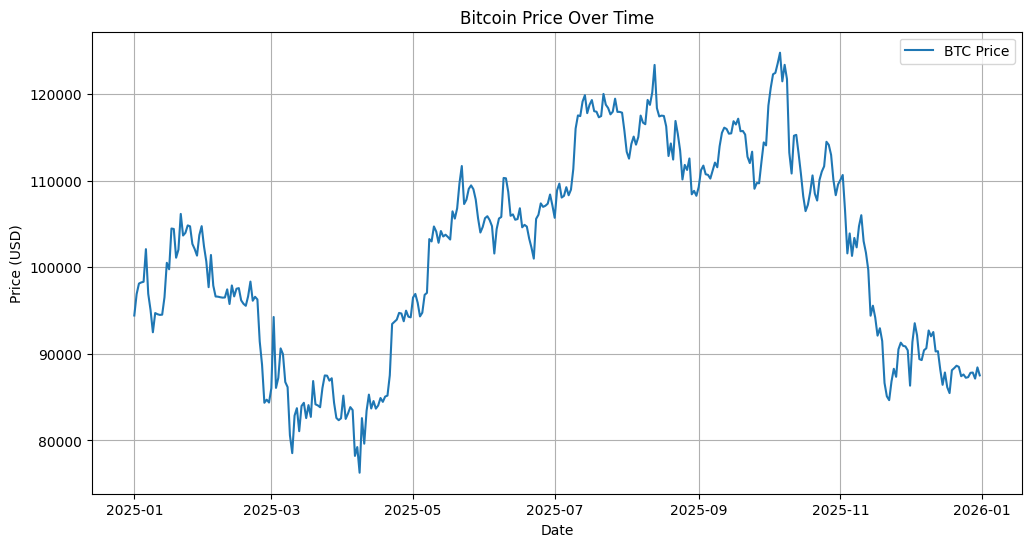

In [ ]:
#Visualize the stock price
plt.plot(stock.index, stock["Price"], label="BTC Price")
plt.title("Bitcoin Price Over Time")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Extract Price and Volume for analysis
stock_data = pd.concat([
    stock[('Price', ticker)].rename('Price'),
    stock[('Volume', ticker)].rename('Volume')
], axis=1)

stock_data.index = pd.to_datetime(stock_data.index)

print("Missing values in stock data:", stock_data.isna().sum().sum())
display(stock_data.head(10))
display(stock_data.isna().sum())

# =======================
# Daily Returns Calculation
# =======================

# Simple returns
stock_data['Returns'] = stock_data['Price'].pct_change()

# Log Price and Log Returns
stock_data['Log Price'] = np.log(stock_data['Price'])
stock_data['Log Returns'] = stock_data['Log Price'].diff()

# =========================
# Aggregate BTC daily data to weekly
# =========================

# Weekly price = last observed price of the week
price_w = stock_data['Price'].resample('W-SUN').last()

# Weekly simple return = close-to-close weekly return
simple_return_w = price_w.pct_change()

# Weekly log return = sum of daily log returns within the week
log_return_w = stock_data['Log Returns'].resample('W-SUN').sum()

# Weekly volume = sum of daily volume
volume_w = stock_data['Volume'].resample('W-SUN').sum()

# Combine into final weekly dataframe
stock_weekly = pd.concat([
    price_w.rename('Price'),
    simple_return_w.rename('Returns'),
    log_return_w.rename('Log Returns'),
    volume_w.rename('Volume')
], axis=1).dropna()

print("Stock weekly shape:", stock_weekly.shape)
display(stock_weekly.head(10))



Missing values in stock data: 0


,Price,Volume
Date,,
2025-01-01,94419.757812,24519888919
2025-01-02,96886.875000,46009564411
2025-01-03,98107.429688,35611391163
2025-01-04,98236.226562,22342608078
2025-01-05,98314.960938,20525254825
2025-01-06,102078.085938,51823432705
2025-01-07,96922.703125,58685738547
2025-01-08,95043.523438,63875859171
2025-01-09,92484.039062,62777261693


Price     0
Volume    0
dtype: int64

Stock weekly shape: (52, 4)


,Price,Returns,Log Returns,Volume
Date,,,,
2025-01-12,94488.437500,-0.038921,-0.039699,338967010865
2025-01-19,101089.609375,0.069862,0.067530,437782936416
2025-01-26,102682.500000,0.015757,0.015634,471816874719
2025-02-02,97688.976562,-0.048631,-0.049853,362117614322
2025-02-09,96500.093750,-0.012170,-0.012245,388753129798
2025-02-16,96175.031250,-0.003369,-0.003374,230337481014
2025-02-23,96273.921875,0.001028,0.001028,210283176728
2025-03-02,94248.351562,-0.021040,-0.021264,424642208809
2025-03-09,80601.039062,-0.144802,-0.156422,351467410238


| Variable                                | Best Weekly Aggregation Method                    | Why This is Best for Bitcoin (Domain Justification)                                                                                                                                                                             | Literature Support                                                                                                                                                                                        |
| --------------------------------------- | ------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Week Boundary**                       | **UTC calendar week ending Sunday**               | Bitcoin trades 24/7, so unlike equities there is no natural “market close.” Using a Sunday UTC close ensures the full trading week (including weekends) is captured and aligns more consistently with Google Trends weekly data | Ali et al. (2025) show that the choice of weekly benchmark (e.g., Friday vs weekend) significantly affects results. Zhang et al. (2021) emphasize proper alignment between attention data and market data |
| **Weekly Price**                        | **Last observed daily closing price of the week** | The last price reflects the most up-to-date market information and preserves jumps and volatility. Averaging would smooth out important movements in a highly volatile asset like Bitcoin                                       | Ali et al. (2025) highlight that endpoint selection affects crypto return measurement. Aslanidis et al. (2022) use price–attention relationships that depend on consistent price definitions              |
| **Weekly Simple Return**                | **Close-to-close return**: ((P_t / P_{t-1}) - 1)  | This reflects actual investor gain/loss over the week and aligns directly with the chosen weekly price. It is intuitive for interpretation and reporting                                                                        | Hoang et al. (2024) analyze relationships between search activity and returns, requiring consistent return definitions. Lin (2021) links investor attention to return dynamics                            |
| **Weekly Log Return**                   | **Sum of daily log returns**                      | Log returns are additive across time, making them ideal for time-series modelling and volatility analysis. This method preserves intra-week information and is standard in financial econometrics                               | Bergsli et al. (2022) use return-based models for volatility. Zhang et al. (2021) rely on properly constructed return series in time-series analysis                                                      |
| **Weekly Trading Volume**               | **Sum of daily trading volume**                   | Volume is a flow variable, so summing captures total trading activity. This is crucial in crypto markets where trading intensity varies significantly and is linked to volatility and price discovery                           | Yarovaya et al. (2022) show trading volume plays a key role in price formation. Schwenkler & Zheng (2025) compute weekly volume as aggregated trading activity and link it to market dynamics             |
| **Frequency Alignment (BTC vs Trends)** | **Aggregate BTC to weekly (match Trends)**        | Google Trends data is naturally weekly, so aligning Bitcoin data avoids mismatched frequencies and ensures valid statistical comparisons in lead–lag and causality analysis                                                     | Aslanidis et al. (2022) and Hoang et al. (2024) both rely on aligned frequencies between attention and market variables                                                                                   |

Bitcoin daily data were aggregated to weekly frequency using UTC calendar weeks ending on Sunday to ensure consistency with Google Trends data and to capture the full 24/7 trading cycle of cryptocurrency markets. Weekly price was defined as the last observed closing price, while weekly simple returns were calculated on a close-to-close basis. Weekly log returns were computed as the sum of daily log returns, allowing for time-additive properties suitable for econometric modelling. Trading volume was aggregated as the sum of daily volume to reflect total market activity. This approach is supported by recent literature highlighting the importance of benchmark timing, return construction, and volume aggregation in cryptocurrency markets (Ali et al., 2025; Bergsli et al., 2022; Yarovaya et al., 2022).



In [ ]:
# Fetch Google Trends data
pytrends = TrendReq(hl='en-US', tz=0)
pytrends.build_payload(terms, timeframe=f'{start_date} {end_date}', geo='')
trends_data = pytrends.interest_over_time()
print("Missing values in trends data:", trends_data.isna().sum().sum())
print("Number of partial rows:", trends_data['isPartial'].sum())
display(trends_data.head(10))
trends_data.shape[0]

Missing values in trends data: 0
Number of partial rows: 0


,Bitcoin,BTC Price,Bitcoin News,Crypto Crash,Buy Bitcoin,isPartial
date,,,,,,
2024-12-29,59,4,1,0,1,False
2025-01-05,60,4,1,0,1,False
2025-01-12,58,4,1,0,1,False
2025-01-19,74,5,2,0,1,False
2025-01-26,56,4,1,0,1,False
2025-02-02,58,4,1,0,1,False
2025-02-09,40,3,1,0,1,False
2025-02-16,40,3,1,0,1,False
2025-02-23,63,5,1,0,1,False


53

* Google Trends data were collected using the pytrends library, which provides access to Google trends time series .
* The query was built using the selected Bitcoin-related search terms(Bitcoin, BTC Price, Bitcoin News, Crypto Crash, Buy Bitcoin) over the specified sample period.
* The interest_over_time() function returned weekly search intensity values for each keyword, scaled from 0 to 100, where 100 represents the peak search interest for that term in the selected period.
* The resulting dataset was inspected for missing values

In [ ]:
trends = trends_data.copy()
if 'isPartial' in trends.columns:
    trends.drop(columns=['isPartial'], inplace=True)
trends.index = pd.to_datetime(trends.index)


trends = trends.rename(columns={
    "Bitcoin": "Trend_Bitcoin",
    "BTC Price": "Trend_BTC_Price",
    "Bitcoin News": "Trend_Bitcoin_News",
    "Crypto Crash": "Trend_Crypto_Crash",
    "Buy Bitcoin": "Trend_Buy_Bitcoin"
})

display(trends.head(10))
trends.isna().sum()


,Trend_Bitcoin,Trend_BTC_Price,Trend_Bitcoin_News,Trend_Crypto_Crash,Trend_Buy_Bitcoin
date,,,,,
2024-12-29,59,4,1,0,1
2025-01-05,60,4,1,0,1
2025-01-12,58,4,1,0,1
2025-01-19,74,5,2,0,1
2025-01-26,56,4,1,0,1
2025-02-02,58,4,1,0,1
2025-02-09,40,3,1,0,1
2025-02-16,40,3,1,0,1
2025-02-23,63,5,1,0,1


Trend_Bitcoin         0
Trend_BTC_Price       0
Trend_Bitcoin_News    0
Trend_Crypto_Crash    0
Trend_Buy_Bitcoin     0
dtype: int64

In [ ]:
trends= trends.resample('W-SUN').mean()
merged_data = pd.merge(stock_weekly, trends, left_index=True, right_index=True, how='inner').sort_index()
display(merged_data.head(10))
merged_data = merged_data.ffill().bfill()
print("Merged weekly dataset shape:", merged_data.shape)
print("\nMissing values after merge:")
print(merged_data.isna().sum())


#raw copy for analysis
analysis_data = merged_data.copy()
df=analysis_data.copy()

#normalize numeric columns for better comparability
numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = (df[numeric_cols] - df[numeric_cols].mean()) / df[numeric_cols].std()





,Price,Returns,Log Returns,Volume,Trend_Bitcoin,Trend_BTC_Price,Trend_Bitcoin_News,Trend_Crypto_Crash,Trend_Buy_Bitcoin
2025-01-12,94488.437500,-0.038921,-0.039699,338967010865,58.0,4.0,1.0,0.0,1.0
2025-01-19,101089.609375,0.069862,0.067530,437782936416,74.0,5.0,2.0,0.0,1.0
2025-01-26,102682.500000,0.015757,0.015634,471816874719,56.0,4.0,1.0,0.0,1.0
2025-02-02,97688.976562,-0.048631,-0.049853,362117614322,58.0,4.0,1.0,0.0,1.0
2025-02-09,96500.093750,-0.012170,-0.012245,388753129798,40.0,3.0,1.0,0.0,1.0
2025-02-16,96175.031250,-0.003369,-0.003374,230337481014,40.0,3.0,1.0,0.0,1.0
2025-02-23,96273.921875,0.001028,0.001028,210283176728,63.0,5.0,1.0,0.0,1.0
2025-03-02,94248.351562,-0.021040,-0.021264,424642208809,66.0,5.0,1.0,0.0,1.0
2025-03-09,80601.039062,-0.144802,-0.156422,351467410238,59.0,5.0,1.0,0.0,1.0
2025-03-16,82579.687500,0.024549,0.024252,245099235090,42.0,3.0,1.0,0.0,1.0


Merged weekly dataset shape: (51, 9)

Missing values after merge:
Price                 0
Returns               0
Log Returns           0
Volume                0
Trend_Bitcoin         0
Trend_BTC_Price       0
Trend_Bitcoin_News    0
Trend_Crypto_Crash    0
Trend_Buy_Bitcoin     0
dtype: int64


Inner Join, keeps dates exist in both stock weekly and trends, drops non-overlapping weeks:
* Better choice for: correlation, regression, stationarity tests, or Granger causality

* Google Trends data was resampled to weekly frequency using a Sunday endpoint to ensure consistency with the aggregated Bitcoin data.
* Missing values were handled using forward and backward filling to maintain continuity.
* A copy of the merged dataset was created for analysis
* All numerical variables were standardised using z-score normalisation. Ensures that variables measured on different scales are directly comparable in analysis and visualisation.

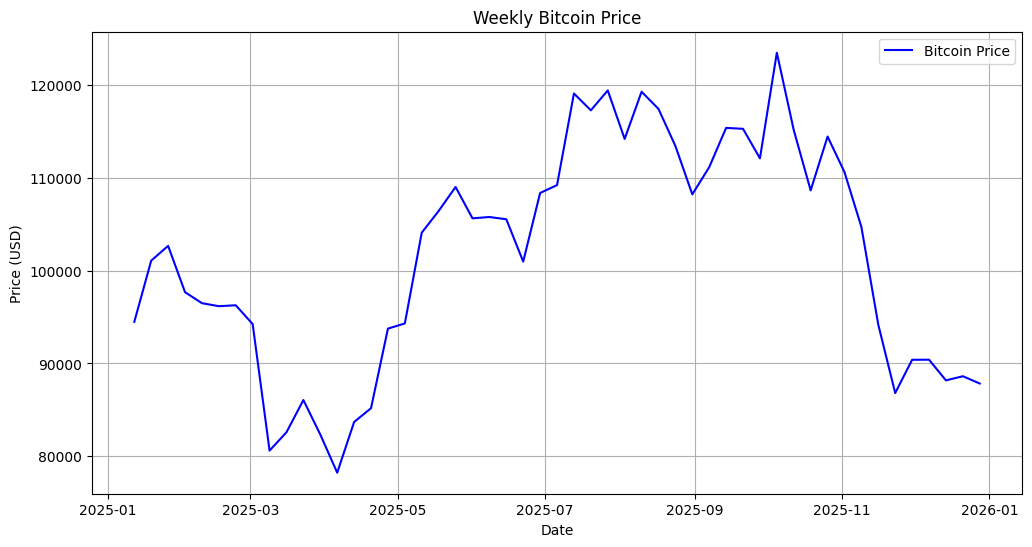

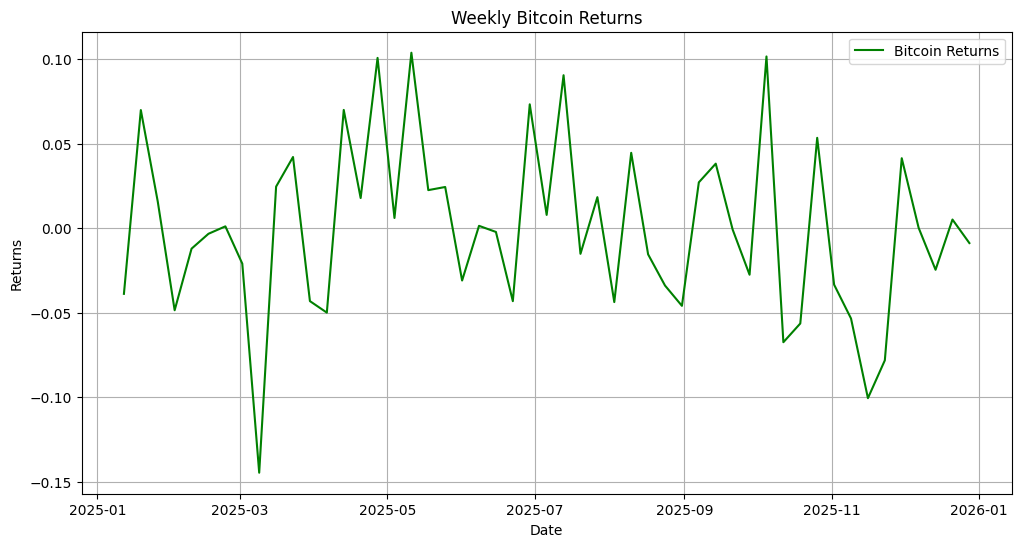

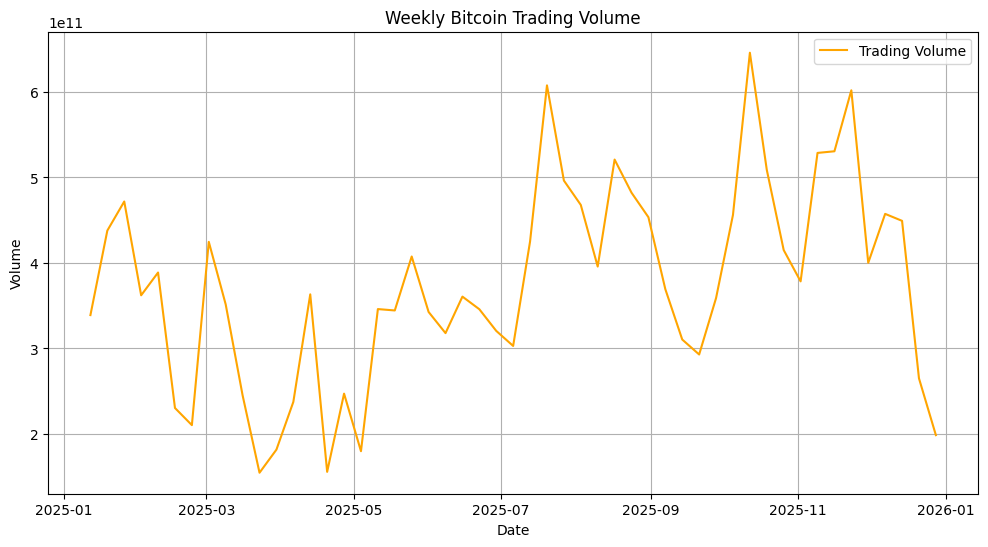

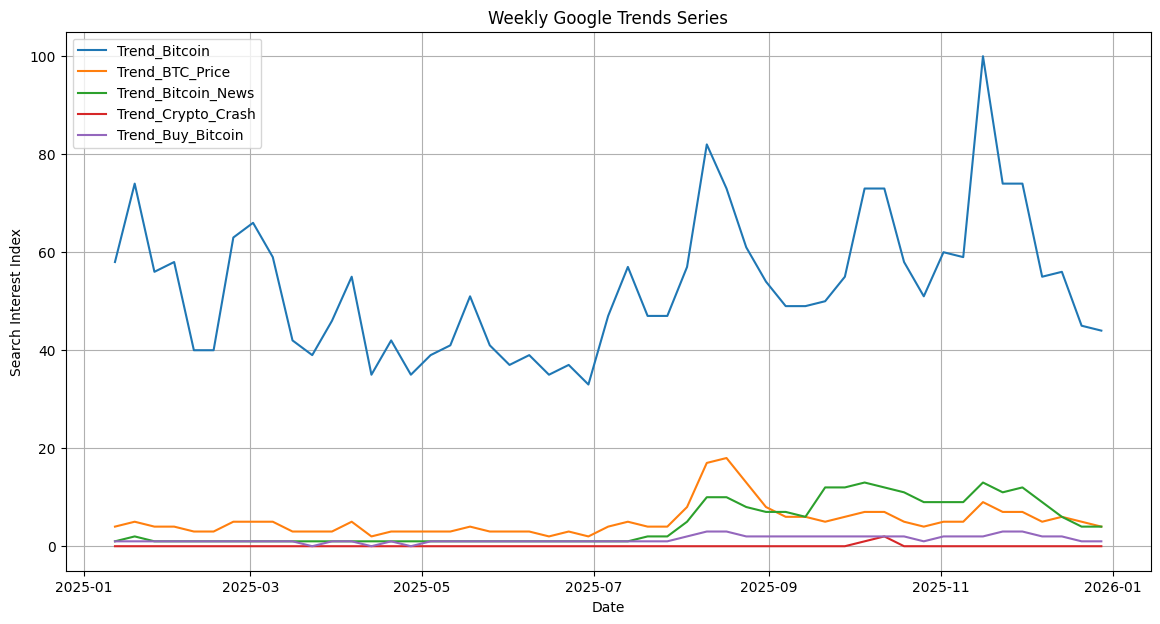

In [ ]:
#=======================
# Weekly Bitcoin Price
#=======================
plt.figure(figsize=(12, 6))
plt.plot(analysis_data.index, analysis_data['Price'], color='blue', label='Bitcoin Price')
plt.title('Weekly Bitcoin Price')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True)
plt.show()

#=======================
# Weekly Bitcoin Returns
#=======================
plt.figure(figsize=(12, 6))
plt.plot(analysis_data.index, analysis_data['Returns'], color='green', label='Bitcoin Returns')
plt.title('Weekly Bitcoin Returns')
plt.xlabel('Date')
plt.ylabel('Returns')
plt.legend()
plt.grid(True)
plt.show()

#=======================
# Weekly Bitcoin Trading Volume
#=======================

plt.figure(figsize=(12, 6))
plt.plot(analysis_data.index, analysis_data['Volume'], color='orange', label='Trading Volume')
plt.title('Weekly Bitcoin Trading Volume')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.legend()
plt.grid(True)
plt.show()


#=======================
# Weekly Google Trends Series
#=======================
plt.figure(figsize=(14, 7))
for col in analysis_data.columns:
    if col != 'Price' and col != 'Returns' and col != 'Volume' and col!= 'Log Returns':
        plt.plot(analysis_data.index, analysis_data[col], label=col)

plt.title('Weekly Google Trends Series')
plt.xlabel('Date')
plt.ylabel('Search Interest Index')
plt.legend()
plt.grid(True)
plt.show()


1. Weekly Bitcoin Price
* Early-year decline (Jan–Mar)
* Strong recovery and rally (May–Oct)
* Sharp correction (Nov–Dec)

Interpretation:
* Clear market regimes (bear → bull → correction)
* Search activity appears to rise during or after major price movements
* Suggests attention is reactive rather than predictive

2. Weekly Bitcoin Returns
* Highly volatile, fluctuating around zero
* Large positive and negative spikes
* No smooth trend reflects short-term market shocks

Interpretation:
* Returns capture short-run reactions, not long-term trends
* No clear visual pattern that searches consistently lead returns

3. Weekly Bitcoin Trading Volume
* Volume increases:Mid-yearr, Late-year (Oct–Nov peaks)
* Spikes coincide with volatile periods

Interpretation:
* Google Trends likely captures investor participation and attention
* Suggests Trends may be useful for predicting: trading activity, market intensity

4. Weekly Google Trends Series
* Trend_Bitcoin → strongest variation over time
* Other terms increase mainly later in the year
* Trend_Crypto_Crash remains low except during stress periods

Interpretation:
Different terms capture different behaviours:
* General attention → Bitcoin
* Monitoring → BTC Price
* Information → Bitcoin News
* Fear → Crypto Crash
* Intent → Buy Bitcoin

Search spikes occur:
* During price rallies
* During high volume periods
* Google Trends moves with the market, not independently
* Suggests: Attention is a lagging indicator

Google Trends appears to be:
A useful explanatory variable for Bitcoin market activity, particularly for trading volume and investor attention


,Price,Returns,Log Returns,Volume,Trend_Bitcoin,Trend_BTC_Price,Trend_Bitcoin_News,Trend_Crypto_Crash,Trend_Buy_Bitcoin
2025-01-12,-0.589312,-0.730789,-0.716501,-0.299559,0.344976,-0.378197,-0.804342,-0.189389,-0.542191
2025-01-19,-0.050597,1.358552,1.332896,0.540310,1.484654,-0.067099,-0.576445,-0.189389,-0.542191
2025-01-26,0.079397,0.319387,0.341047,0.829576,0.202516,-0.378197,-0.804342,-0.189389,-0.542191
2025-02-02,-0.328119,-0.917277,-0.910573,-0.102794,0.344976,-0.378197,-0.804342,-0.189389,-0.542191
2025-02-09,-0.425143,-0.216998,-0.191789,0.123590,-0.937162,-0.689294,-0.804342,-0.189389,-0.542191
2025-02-16,-0.451671,-0.047951,-0.022252,-1.222837,-0.937162,-0.689294,-0.804342,-0.189389,-0.542191
2025-02-23,-0.443601,0.036495,0.061879,-1.393285,0.701126,-0.067099,-0.804342,-0.189389,-0.542191
2025-03-02,-0.608905,-0.387351,-0.364172,0.428623,0.914815,-0.067099,-0.804342,-0.189389,-0.542191
2025-03-09,-1.722648,-2.764380,-2.947361,-0.193314,0.416206,-0.067099,-0.804342,-0.189389,-0.542191
2025-03-16,-1.561173,0.488240,0.505755,-1.097372,-0.794702,-0.689294,-0.804342,-0.189389,-0.542191


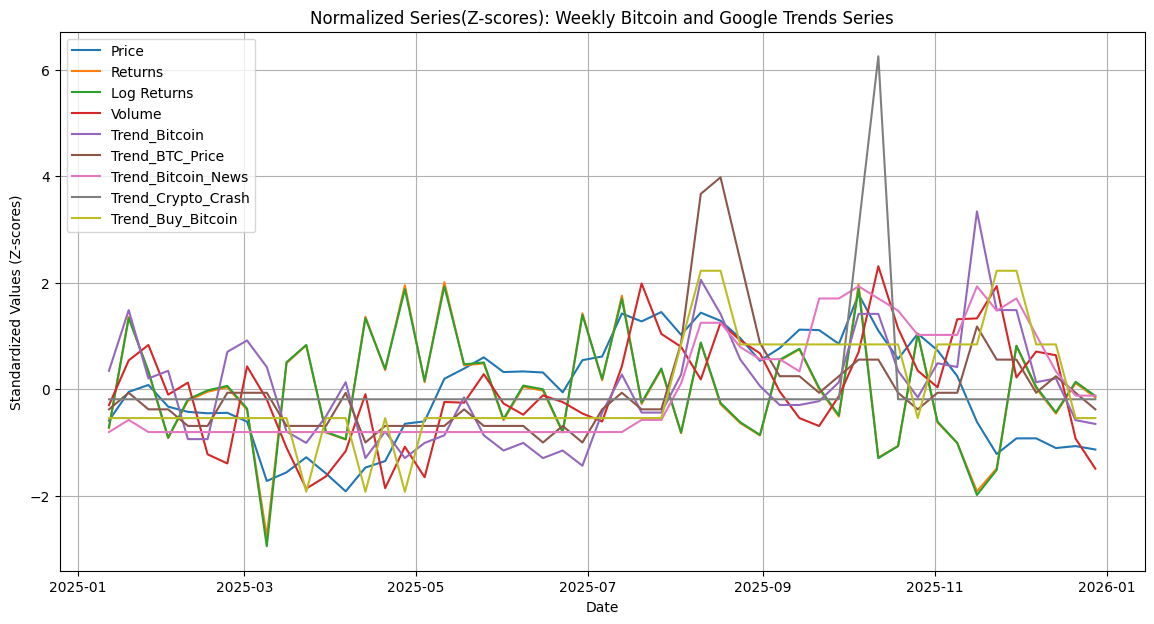

In [ ]:
display(df.head(10))
plt.figure(figsize=(14, 7))
for col in df.columns:
    if col != 'isPartial':
        plt.plot(df.index, df[col], label=col)

plt.title('Normalized Series(Z-scores): Weekly Bitcoin and Google Trends Series')
plt.xlabel('Date')
plt.ylabel('Standardized Values (Z-scores)')
plt.legend()
plt.grid(True)
plt.show()


The normalized series indicates that Google Trends variables generally move simultaenously with or slightly after Bitcoin market activity, rather than consistently preceding it. While certain search terms, particularly general attention (“Bitcoin”), show strong co-movement with returns and volatility, the overall pattern suggests that internet attention is largely reactive. As a result, Google Trends appears to have limited predictive power for Bitcoin returns but provides valuable insight into market sentiment, investor behaviour, and periods of heightened trading activity.

Google Trends reflects investor reaction and sentiment cycles, but does not consistently lead Bitcoin market movements.

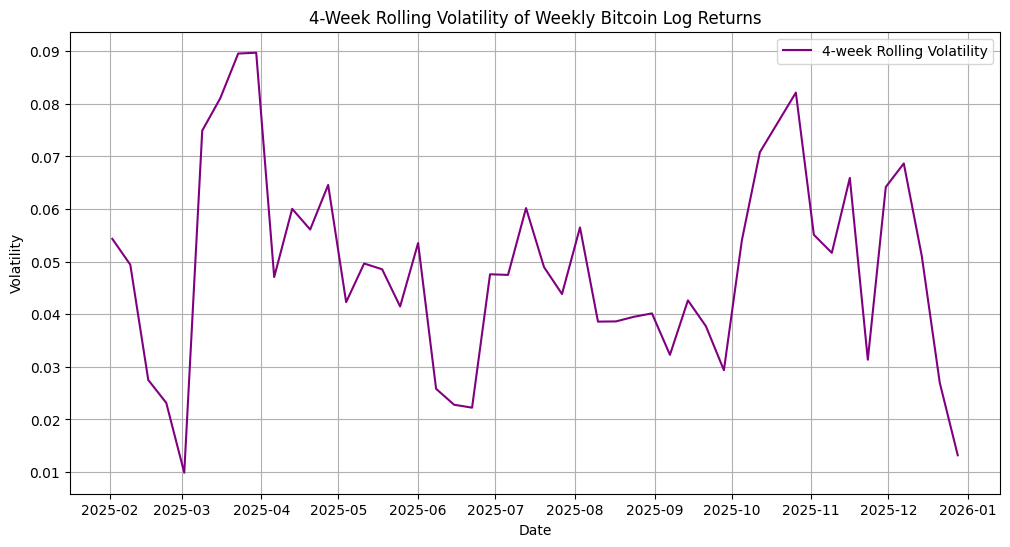

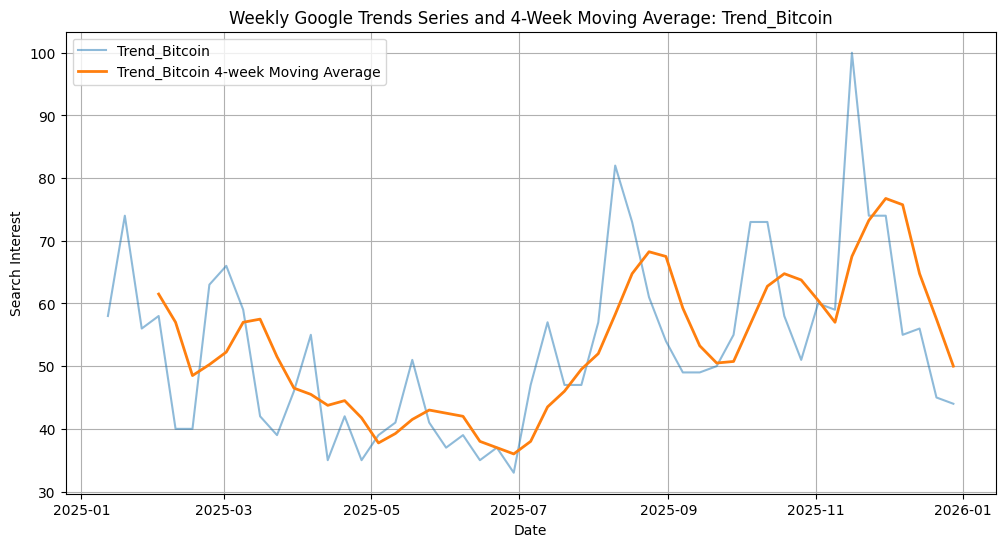

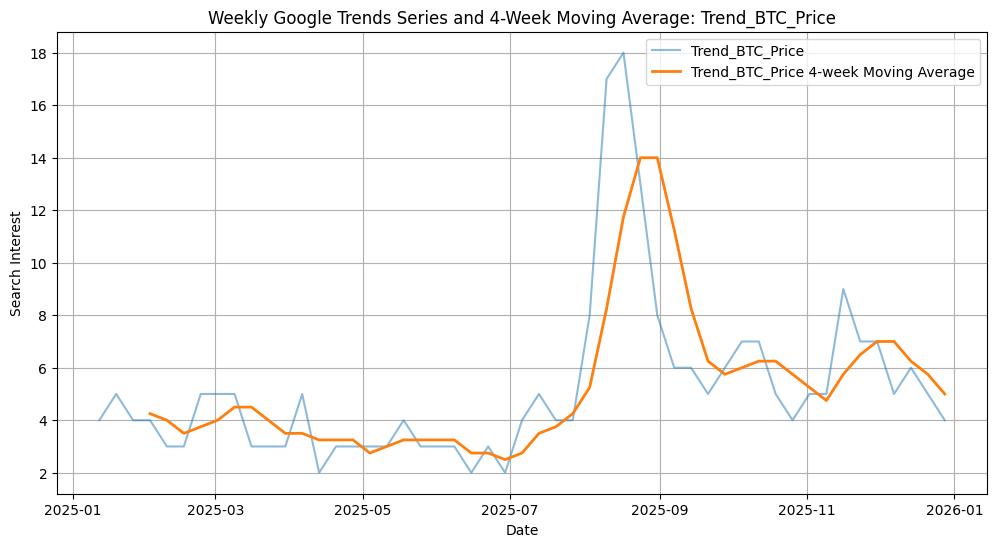

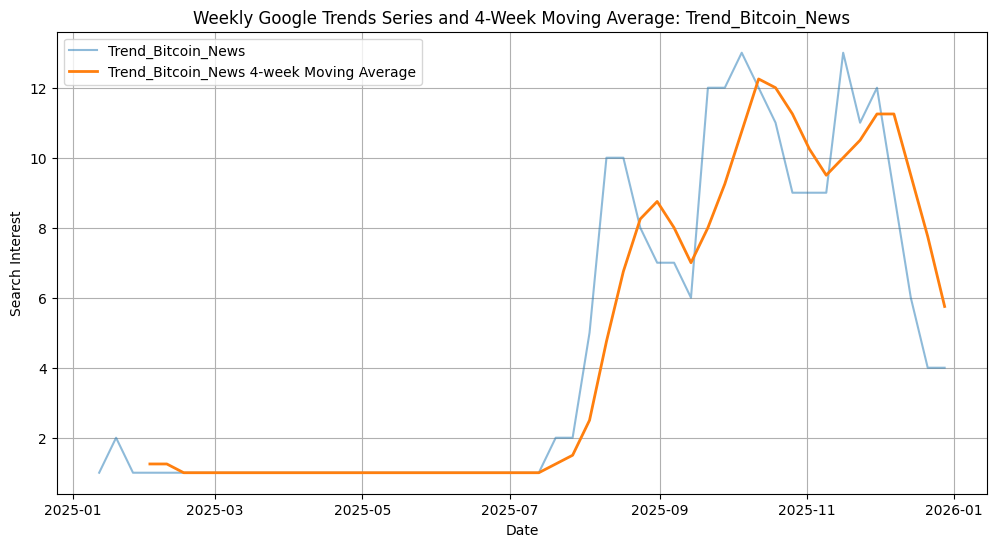

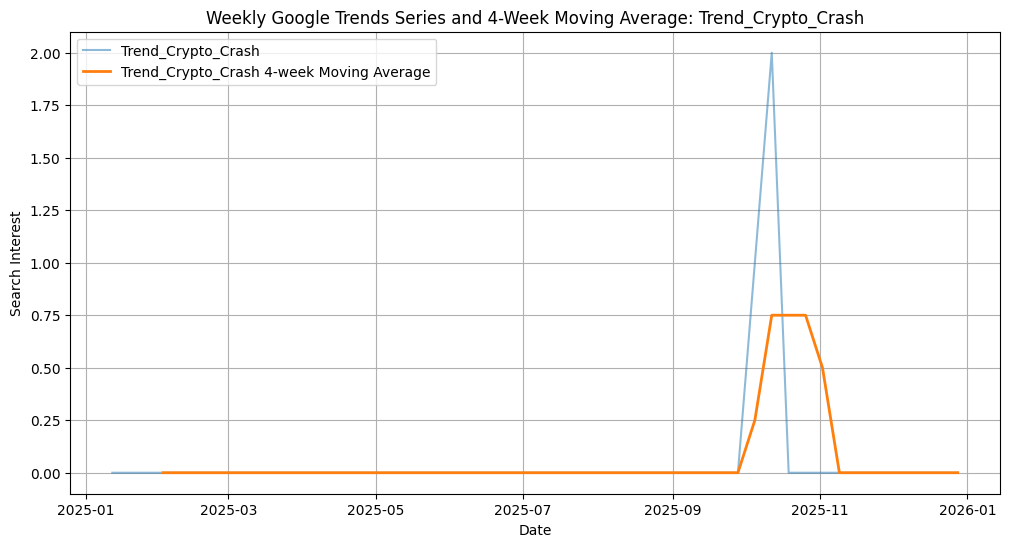

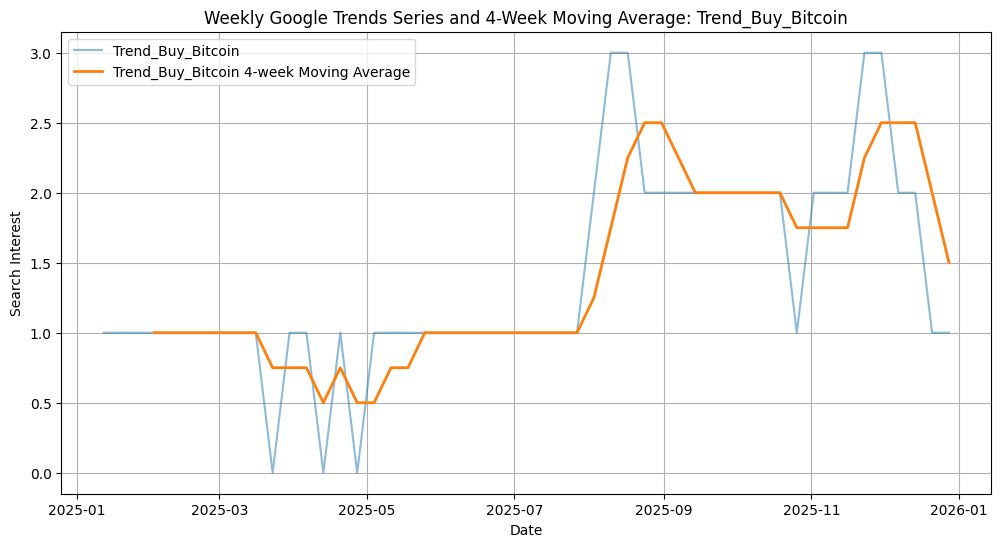

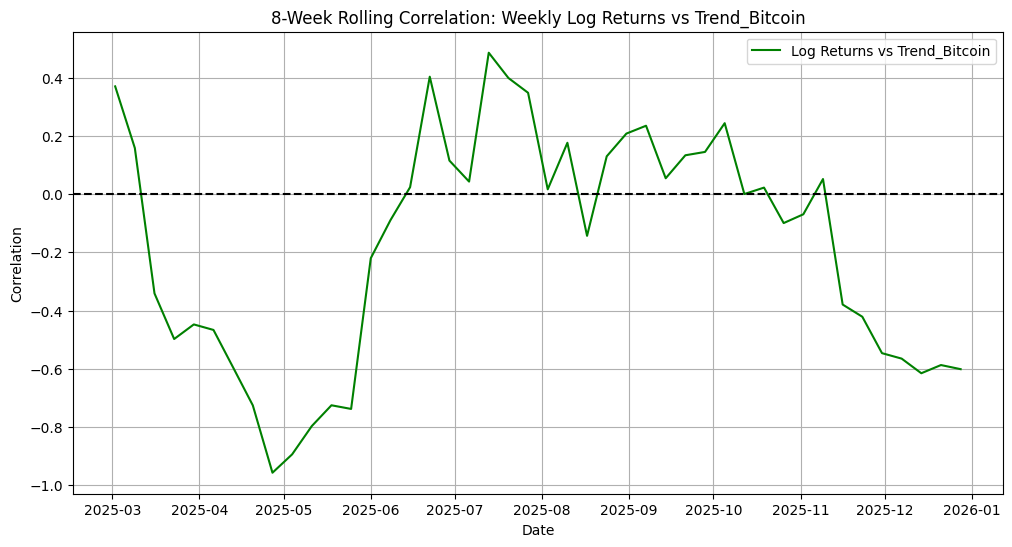

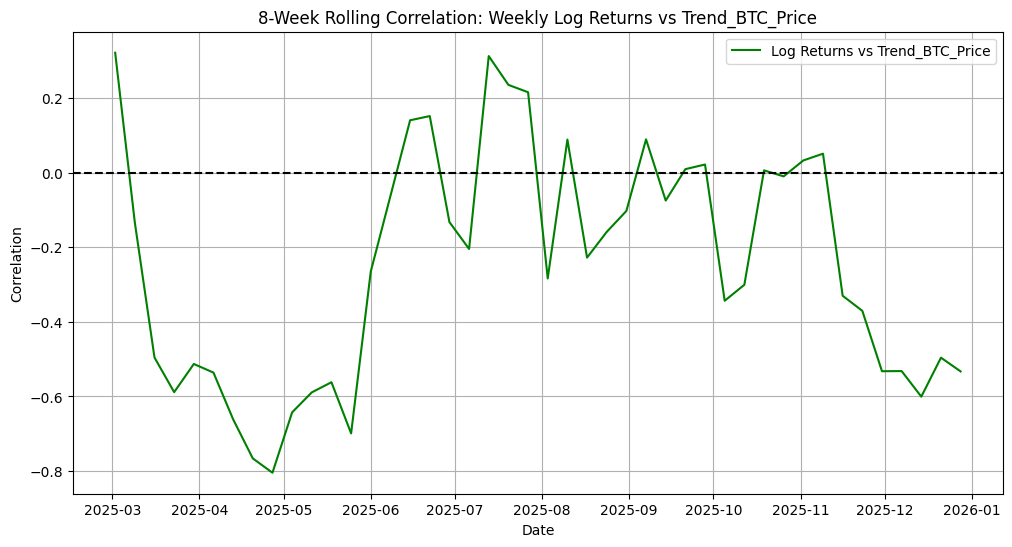

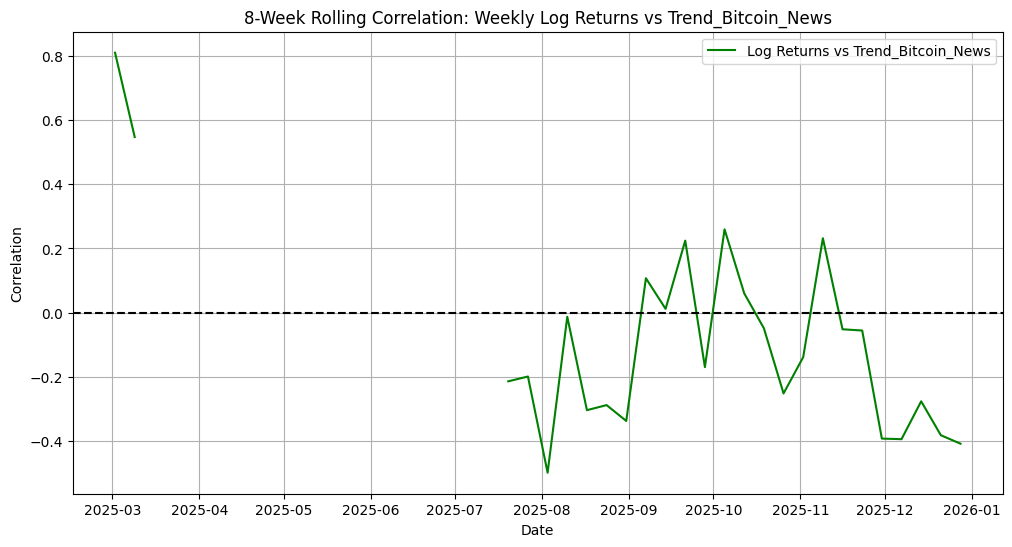

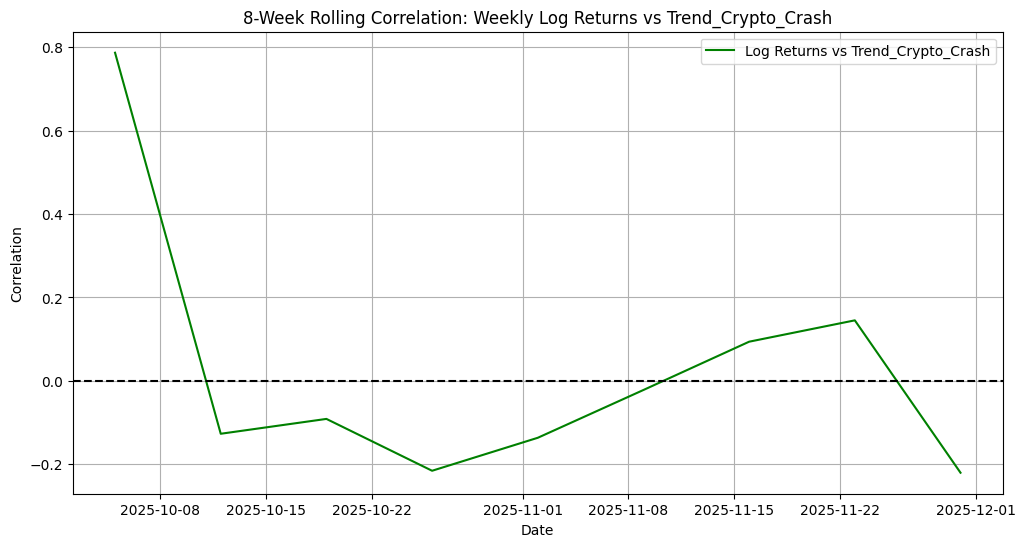

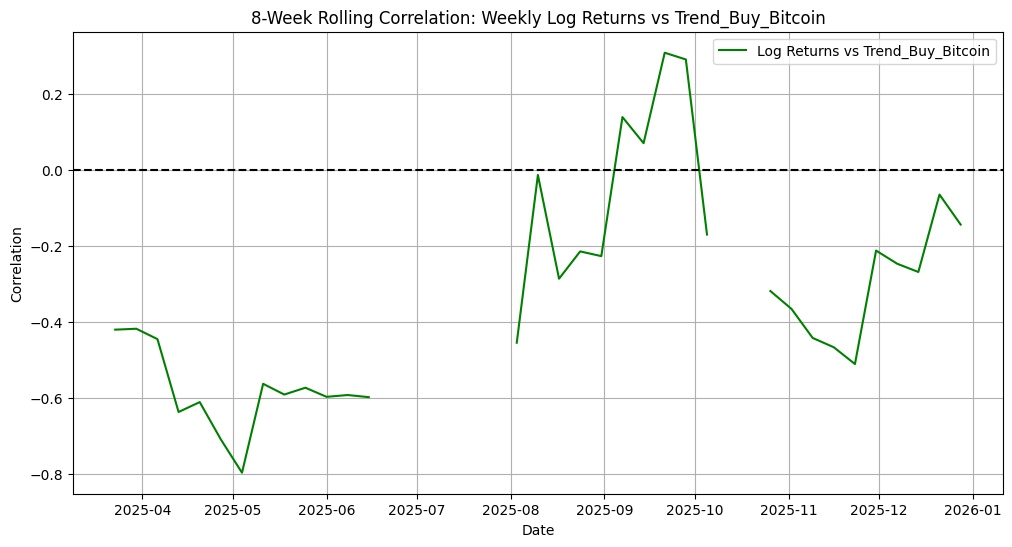

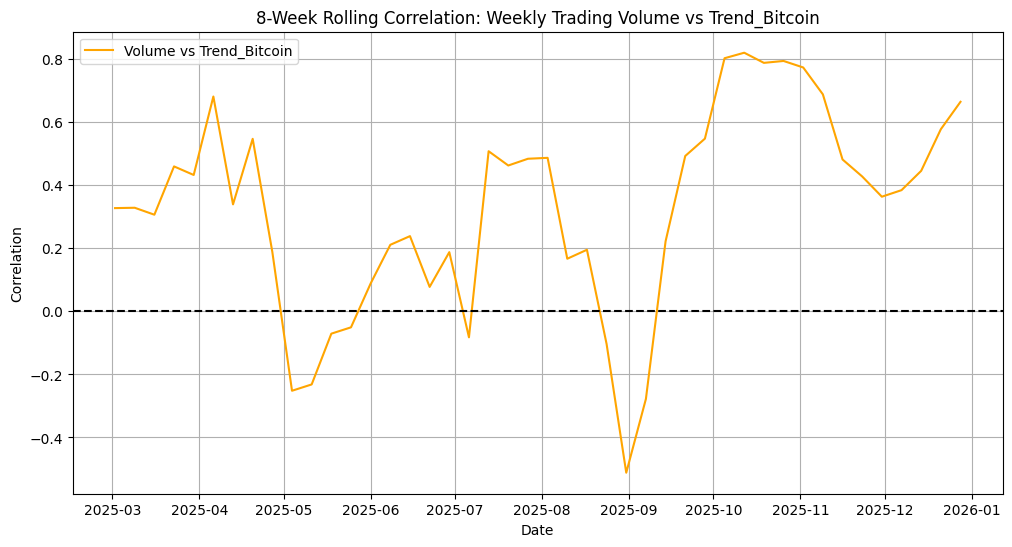

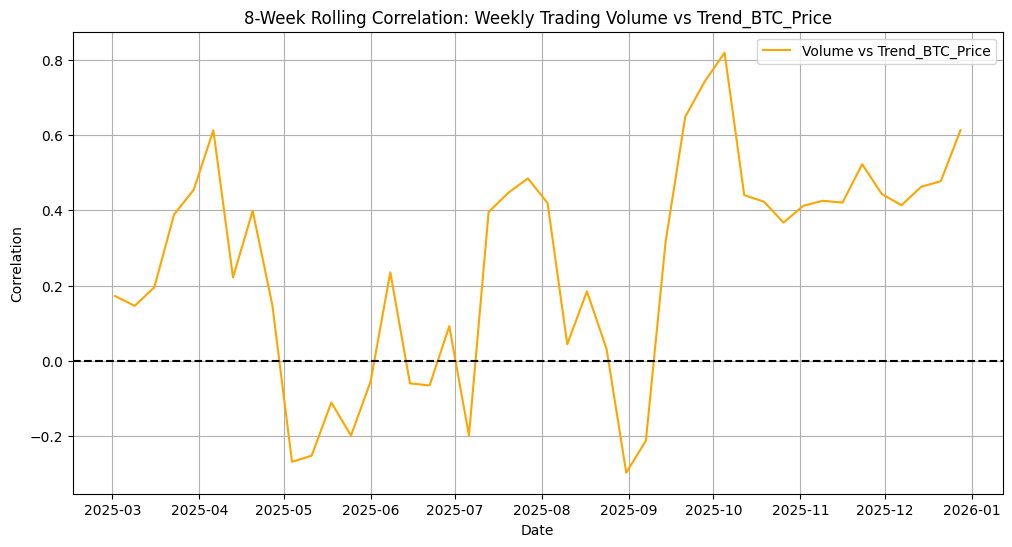

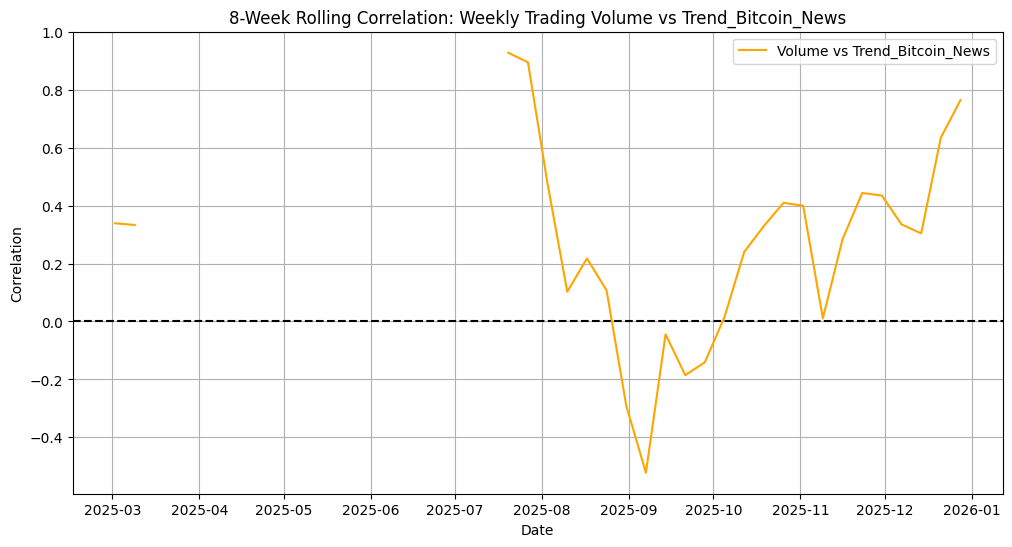

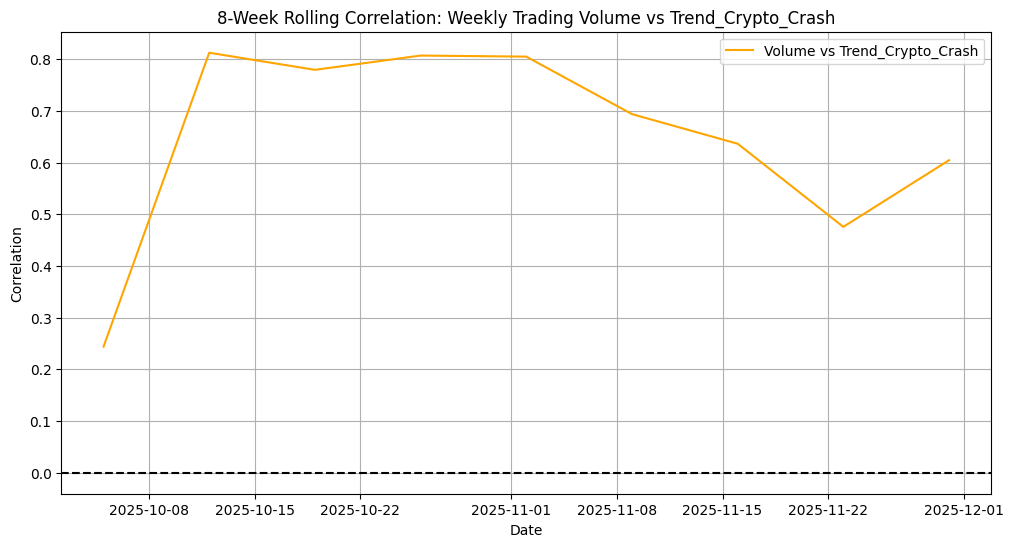

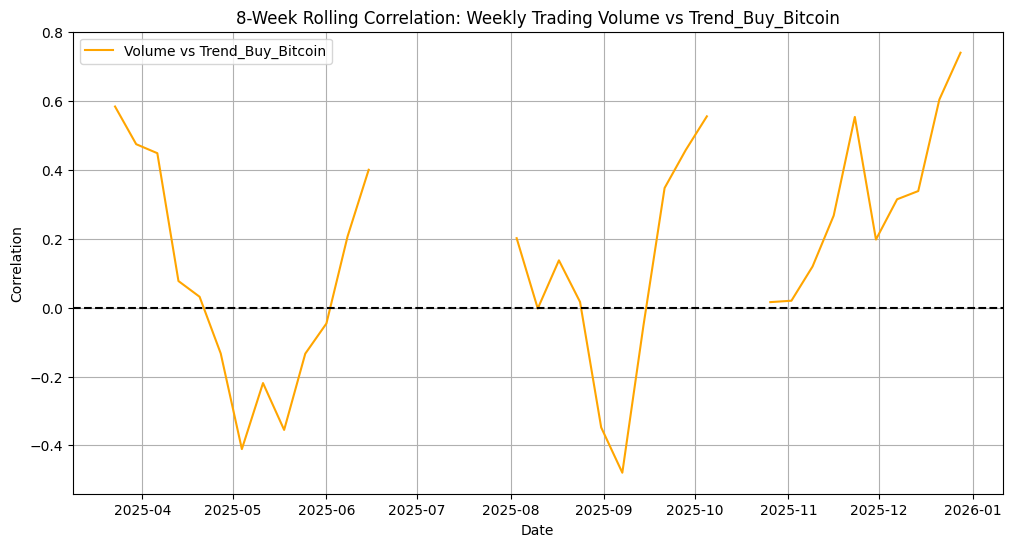

In [ ]:
window_short = 4
window_corr = 8

df_roll = analysis_data.copy()

# Identify Google Trends columns
trend_cols = [col for col in df_roll.columns if col not in ['Price', 'Returns', 'Log Returns', 'Volume', 'isPartial']]

# Rolling volatility of weekly log returns
df_roll["rolling_volatility_4w"] = df_roll["Log Returns"].rolling(window_short).std()

# Rolling means for Google Trends attention variables
for col in trend_cols:
    df_roll[f"{col}_ma4"] = df_roll[col].rolling(window_short).mean()

# Rolling correlation: weekly log returns vs each trend variable
for col in trend_cols:
    df_roll[f"corr_logret_{col}_8w"] = df_roll["Log Returns"].rolling(window_corr).corr(df_roll[col])

# Rolling correlation: weekly trading volume vs each trend variable
for col in trend_cols:
    df_roll[f"corr_vol_{col}_8w"] = df_roll["Volume"].rolling(window_corr).corr(df_roll[col])

# Plot rolling volatility
plt.figure(figsize=(12, 6))
plt.plot(df_roll.index, df_roll["rolling_volatility_4w"], label="4-week Rolling Volatility", color="purple")
plt.title("4-Week Rolling Volatility of Weekly Bitcoin Log Returns")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.legend()
plt.grid(True)
plt.show()

# Plot rolling mean for each Google Trends series
for col in trend_cols:
    plt.figure(figsize=(12, 6))
    plt.plot(df_roll.index, df_roll[col], alpha=0.5, label=col)
    plt.plot(df_roll.index, df_roll[f"{col}_ma4"], label=f"{col} 4-week Moving Average", linewidth=2)
    plt.title(f"Weekly Google Trends Series and 4-Week Moving Average: {col}")
    plt.xlabel("Date")
    plt.ylabel("Search Interest")
    plt.legend()
    plt.grid(True)
    plt.show()

# Plot rolling correlation: log returns vs Google Trends
for col in trend_cols:
    plt.figure(figsize=(12, 6))
    plt.plot(df_roll.index, df_roll[f"corr_logret_{col}_8w"], label=f"Log Returns vs {col}", color="green")
    plt.axhline(0, linestyle="--", color="black")
    plt.title(f"8-Week Rolling Correlation: Weekly Log Returns vs {col}")
    plt.xlabel("Date")
    plt.ylabel("Correlation")
    plt.legend()
    plt.grid(True)
    plt.show()

# Plot rolling correlation: volume vs Google Trends
for col in trend_cols:
    plt.figure(figsize=(12, 6))
    plt.plot(df_roll.index, df_roll[f"corr_vol_{col}_8w"], label=f"Volume vs {col}", color="orange")
    plt.axhline(0, linestyle="--", color="black")
    plt.title(f"8-Week Rolling Correlation: Weekly Trading Volume vs {col}")
    plt.xlabel("Date")
    plt.ylabel("Correlation")
    plt.legend()
    plt.grid(True)
    plt.show()


Rolling-Window Analysis: Key Insights

Relationship between Google Trends and Bitcoin market activity is:
* Time-varying
* Dependent on market conditions
* No evidence of a stable, constant relationship across the sample

Volatility & Attention
Volatility spikes (especially Oct–Nov) align with:
* Increases in: Trend_Bitcoin, Trend_BTC_Price, Trend_Bitcoin_News (Internet attention rises during market stress)
* Trend_Crypto_Crash shows a sharp spike during this period (Strong link between attention and uncertainty)

Trend_Bitcoin and Trend_Bitcoin_News show (Trends Moving Averages (4-week)):
* Sustained upward trends during mid-to-late-year rally
* Attention does not consistently increase before market turning points
* Limited predictive value, More reactive than leading

Returns vs Trends
* Correlations are: Highly unstable (Frequently change sign), Example:
* Trend_Bitcoin: (Positive mid-year, Strongly negative late-year)
* instability in: (Trend_BTC_Price, Trend_Buy_Bitcoin) : Weak and inconsistent relationship
* Google Trends is not a reliable predictor of returns

Volume vs Trends
* Correlations are: Mostly positive, More stable and persistent
* Strong relationships observed: Volume vs Trend_Bitcoin, Volume vs Trend_Crypto_Crash (correlation > 0.8 in peaks)
* Trend_BTC_Price and Trend_Bitcoin_News show sustained positive relationshipsAttention is strongly linked to trading activity

Thus, Google Trends:
* Weak for predicting returns
* Strong for explaining trading volume and investor activity
* Attention behaves as: Reactive to market events and not a consistent leading indicator

 Internet attention is more closely linked to market participation and investor engagement than to price direction or return predictability.

### Augmented Dickey Fuller Test(ADF Stationary Test)
* Ho: Series has a unit root(non stationary)
* Ha: Series Stationary
* Decision rule:
    * if p-value < 0.05, reject the null and conclude the series is stationary
    * if p-value >= 0.05, fail to reject the null and conclude the series is non-stationary

In [ ]:
from statsmodels.tsa.stattools import adfuller

def adf_table(df):
    rows = []
    for col in df.columns:
        series = df[col].dropna()
        result = adfuller(series, autolag='AIC')
        rows.append({
            'Variable': col,
            'ADF Statistic': result[0],
            'p-value': result[1],
            'Lags Used': result[2],
            'N Obs': result[3],
            'Stationary at 5%': 'Yes' if result[1] < 0.05 else 'No'
        })
    return pd.DataFrame(rows).sort_values('p-value')

adf_results = adf_table(analysis_data)
display(adf_results)


,Variable,ADF Statistic,p-value,Lags Used,N Obs,Stationary at 5%
7,Trend_Crypto_Crash,-8.837688,1.701519e-14,11,39,Yes
1,Returns,-7.073251,4.875383e-10,0,50,Yes
2,Log Returns,-7.000441,7.345576e-10,0,50,Yes
4,Trend_Bitcoin,-3.386907,1.141340e-02,0,50,Yes
5,Trend_BTC_Price,-3.315820,1.418597e-02,1,49,Yes
8,Trend_Buy_Bitcoin,-2.732520,6.857792e-02,0,50,No
6,Trend_Bitcoin_News,-2.448870,1.284154e-01,10,40,No
3,Volume,-1.768479,3.962196e-01,3,47,No
0,Price,-1.363872,5.994688e-01,0,50,No


The Augmented Dickey-Fuller test was used to assess whether each weekly series was stationary.

Variables with p-values below 0.05 are considered stationary and can be used directly in time-series analysis.
Variables with p-values above 0.05 are considered non-stationary and should be transformed, typically by first differencing, before applying techniques such as cross-correlation, Granger causality, or ARIMA-type modelling.

The ADF results confirm that Bitcoin returns, Log Returns and Trend_Bitcoin, Trend_BTC_Price, Trend_Crypto_Crash are stationary which makes them good candidates for testing whether attention leads or lags Bitcoin returns or volume. While Price, Volume, Trend_Bitcoin_News, and Trend_Buy_Bitcoin exhibit non-stationary behaviour so they need transformation before you can interpret them as short run predictive signals..

This indicates the presence of underlying trends in both market activity and investor attention.
To ensure valid statistical inference and avoid spurious relationships, non-stationary variables are transformed through differencing before further analysis.

### Differencing and re testing stationarity
Differencing removes trends, we difference Price, Volume, Trend_Bitcoin_News, and Trend_Buy_Bitcoin

In [ ]:
analysis_diff = analysis_data.copy()

analysis_diff['Price'] = analysis_diff['Price'].diff()
analysis_diff['Volume'] = analysis_diff['Volume'].diff()
analysis_diff['Trend_Bitcoin_News'] = analysis_diff['Trend_Bitcoin_News'].diff()
analysis_diff['Trend_Buy_Bitcoin'] = analysis_diff['Trend_Buy_Bitcoin'].diff()

analysis_diff = analysis_diff.dropna()

display(analysis_diff.head(10))
adf_results_diff = adf_table(analysis_diff)
display(adf_results_diff)

,Price,Returns,Log Returns,Volume,Trend_Bitcoin,Trend_BTC_Price,Trend_Bitcoin_News,Trend_Crypto_Crash,Trend_Buy_Bitcoin
2025-01-19,6601.171875,0.069862,0.067530,9.881593e+10,74.0,5.0,1.0,0.0,0.0
2025-01-26,1592.890625,0.015757,0.015634,3.403394e+10,56.0,4.0,-1.0,0.0,0.0
2025-02-02,-4993.523438,-0.048631,-0.049853,-1.096993e+11,58.0,4.0,0.0,0.0,0.0
2025-02-09,-1188.882812,-0.012170,-0.012245,2.663552e+10,40.0,3.0,0.0,0.0,0.0
2025-02-16,-325.062500,-0.003369,-0.003374,-1.584156e+11,40.0,3.0,0.0,0.0,0.0
2025-02-23,98.890625,0.001028,0.001028,-2.005430e+10,63.0,5.0,0.0,0.0,0.0
2025-03-02,-2025.570312,-0.021040,-0.021264,2.143590e+11,66.0,5.0,0.0,0.0,0.0
2025-03-09,-13647.312500,-0.144802,-0.156422,-7.317480e+10,59.0,5.0,0.0,0.0,0.0
2025-03-16,1978.648438,0.024549,0.024252,-1.063682e+11,42.0,3.0,0.0,0.0,0.0
2025-03-23,3474.687500,0.042077,0.041216,-9.046144e+10,39.0,3.0,0.0,0.0,-1.0


,Variable,ADF Statistic,p-value,Lags Used,N Obs,Stationary at 5%
8,Trend_Buy_Bitcoin,-9.197826,2.039951e-15,0,49,Yes
7,Trend_Crypto_Crash,-8.666320,4.673977e-14,11,38,Yes
0,Price,-7.069678,4.974639e-10,0,49,Yes
1,Returns,-6.952233,9.626822e-10,0,49,Yes
2,Log Returns,-6.881901,1.426373e-09,0,49,Yes
3,Volume,-6.430460,1.702491e-08,2,47,Yes
4,Trend_Bitcoin,-3.520247,7.482079e-03,0,49,Yes
5,Trend_BTC_Price,-3.324662,1.381143e-02,1,48,Yes
6,Trend_Bitcoin_News,-1.924955,3.204141e-01,5,44,No


* Variables found to be non-stationary in levels were transformed using differencing
* Bitcoin price, trading volume, and Trend_Buy_Bitcoin were first differenced.
* Trend_Bitcoin_News required second differencing to achieve stationarity.

After transformation, the ADF results were re-evaluated to confirm that the series satisfied the stationarity assumption needed for lead-lag and causality analysis.

In [ ]:
# Second difference only for Trend_Bitcoin_News
analysis_diff['Trend_Bitcoin_News'] = analysis_diff['Trend_Bitcoin_News'].diff()

analysis_diff = analysis_diff.dropna()

display(analysis_diff.head(10))
adf_results_diff2 = adf_table(analysis_diff)
display(adf_results_diff2)

,Price,Returns,Log Returns,Volume,Trend_Bitcoin,Trend_BTC_Price,Trend_Bitcoin_News,Trend_Crypto_Crash,Trend_Buy_Bitcoin
2025-01-26,1592.890625,0.015757,0.015634,3.403394e+10,56.0,4.0,-2.0,0.0,0.0
2025-02-02,-4993.523438,-0.048631,-0.049853,-1.096993e+11,58.0,4.0,1.0,0.0,0.0
2025-02-09,-1188.882812,-0.012170,-0.012245,2.663552e+10,40.0,3.0,0.0,0.0,0.0
2025-02-16,-325.062500,-0.003369,-0.003374,-1.584156e+11,40.0,3.0,0.0,0.0,0.0
2025-02-23,98.890625,0.001028,0.001028,-2.005430e+10,63.0,5.0,0.0,0.0,0.0
2025-03-02,-2025.570312,-0.021040,-0.021264,2.143590e+11,66.0,5.0,0.0,0.0,0.0
2025-03-09,-13647.312500,-0.144802,-0.156422,-7.317480e+10,59.0,5.0,0.0,0.0,0.0
2025-03-16,1978.648438,0.024549,0.024252,-1.063682e+11,42.0,3.0,0.0,0.0,0.0
2025-03-23,3474.687500,0.042077,0.041216,-9.046144e+10,39.0,3.0,0.0,0.0,-1.0
2025-03-30,-3719.851562,-0.043227,-0.044189,2.699995e+10,46.0,3.0,0.0,0.0,1.0


,Variable,ADF Statistic,p-value,Lags Used,N Obs,Stationary at 5%
8,Trend_Buy_Bitcoin,-9.099451,3.639008e-15,0,48,Yes
7,Trend_Crypto_Crash,-8.491502,1.309687e-13,11,37,Yes
0,Price,-6.954453,9.507805e-10,0,48,Yes
1,Returns,-6.820647,2.006025e-09,0,48,Yes
2,Log Returns,-6.757948,2.840032e-09,0,48,Yes
3,Volume,-6.396125,2.048782e-08,2,46,Yes
6,Trend_Bitcoin_News,-5.516026,1.924224e-06,6,42,Yes
5,Trend_BTC_Price,-3.285187,1.555372e-02,1,47,Yes
4,Trend_Bitcoin,-3.250111,1.726124e-02,0,48,Yes


The Trend_Bitcoin_News series remained non-stationary even after second differencing, suggesting strong persistence or structural instability over the sample period. To avoid spurious inference, this variable was excluded from formal stationarity-dependent tests such as Granger causality and cross-correlation, but retained for descriptive analysis.

In [ ]:


series = analysis_data['Trend_Bitcoin_News'].dropna()
result = adfuller(series, regression='ct', autolag='AIC')

print("ADF Statistic:", result[0])
print("p-value:", result[1])


stat, pval, lags, crit = kpss(
    analysis_data['Trend_Bitcoin_News'].dropna(),
    regression='ct',
    nlags='auto'
)

print("KPSS Statistic:", stat)
print("p-value:", pval)


ADF Statistic: -2.4697798551761068
p-value: 0.34323222838328193
KPSS Statistic: 0.13073393272459366
p-value: 0.07827049495445618


The ADF test failed to reject the null hypothesis of a unit root for Trend_Bitcoin_News (p = 0.306), indicating non-stationarity.
Although the KPSS test did not reject the null of stationarity (p = 0.081), this does not provide strong enough evidence to classify the series as stationary.
Given the conflicting results, the series was treated as non-stationary for conservative inference.

### STL Decomposition
STL splits each series into
* Trend: Long run Movement
* Seasonal: Repeating Short-cycle pattern
* Irregular noise not explained by trend or seasonality

Separate long-run trend, short-run seasonal movement, and irregular shocks in the Bitcoin market and Google Trends series.

STL decomposition was applied to Price, Volume, Trend_Bitcoin, and Trend_BTC_Price because they represent broad market level and attention level movements, making them useful for examining medium-term patterns in Bitcoin activity and internet attention


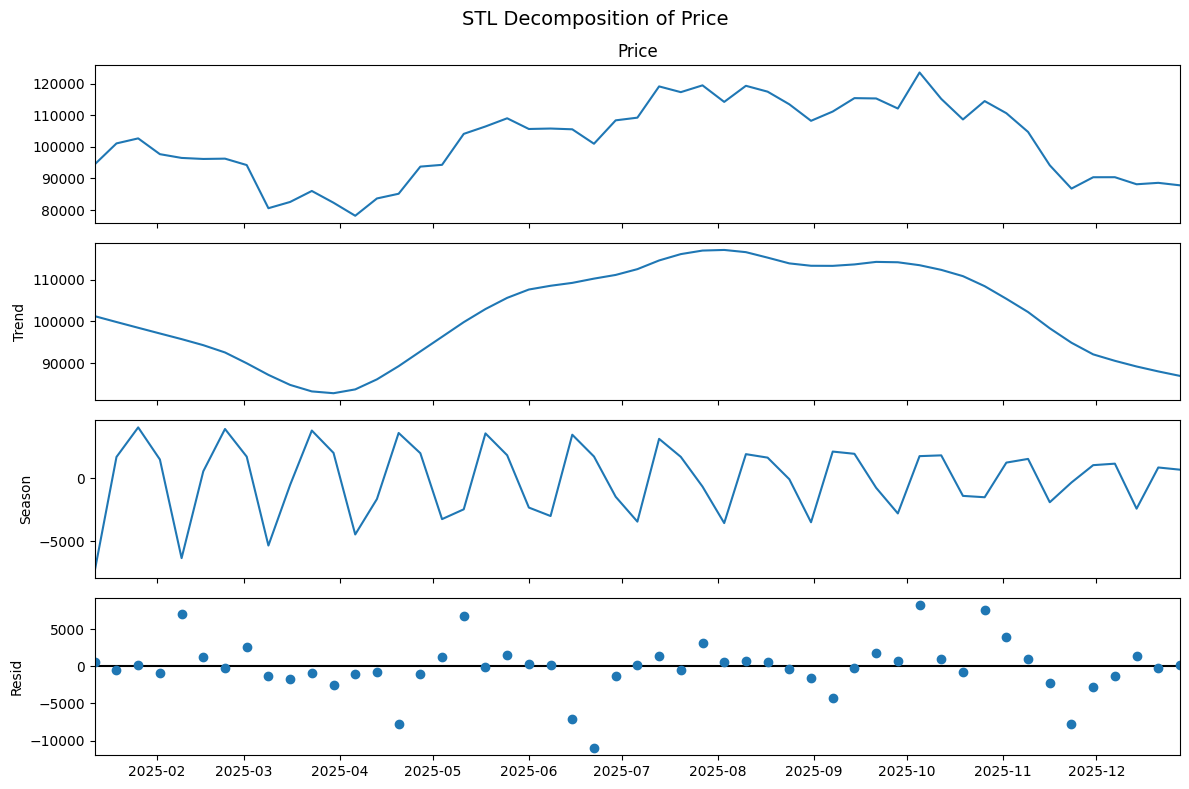

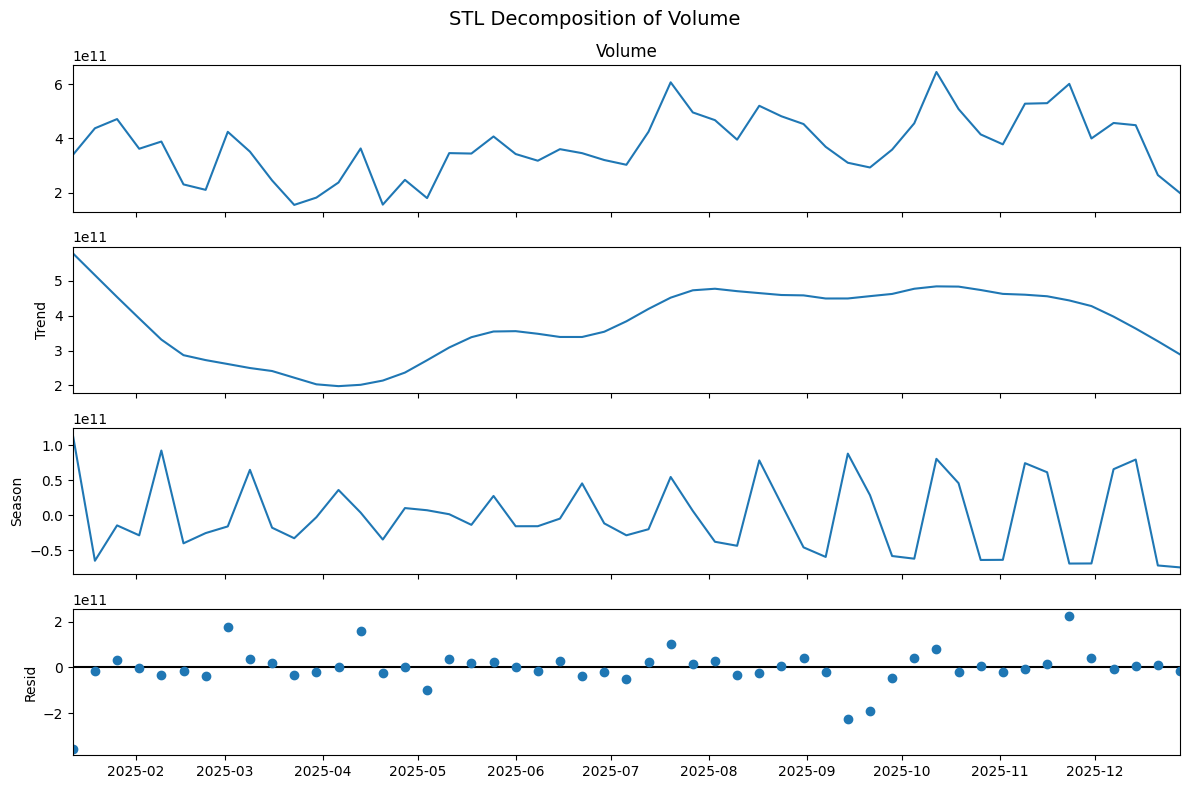

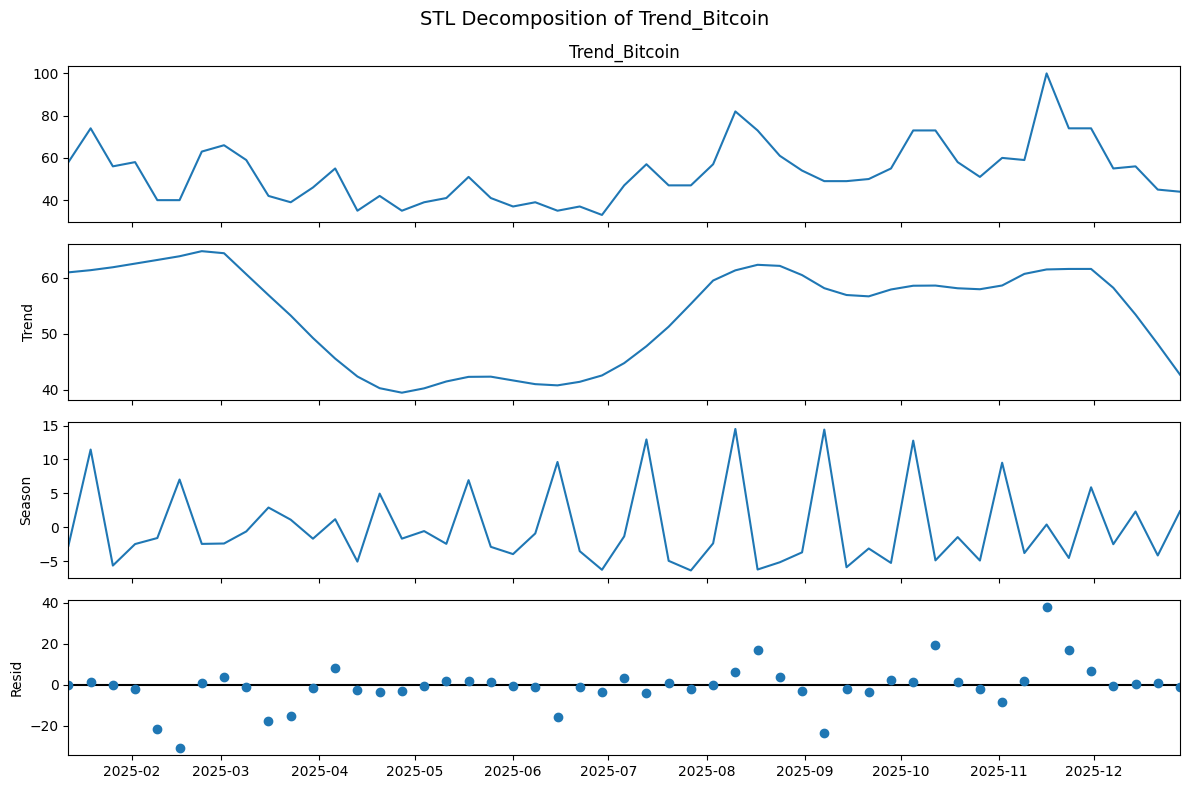

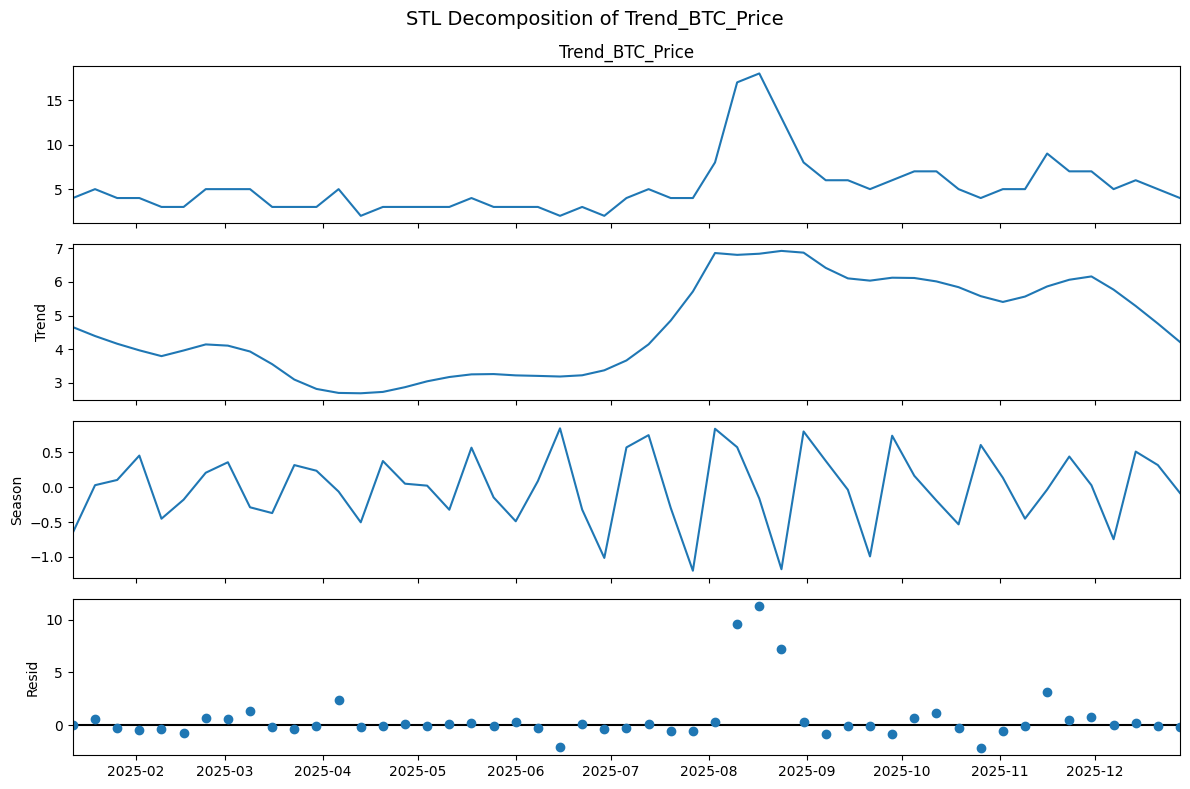

In [ ]:
# STL Decomposition
stl_cols = ['Price', 'Volume', 'Trend_Bitcoin', 'Trend_BTC_Price',]

for col in stl_cols:
    series = analysis_data[col].dropna()

    # Weekly data; a short seasonal window is reasonable for exploratory decomposition
    stl = STL(series, period=4, robust=True)
    result = stl.fit()

    fig = result.plot()
    fig.set_size_inches(12, 8)
    fig.suptitle(f'STL Decomposition of {col}', fontsize=14)
    plt.tight_layout()
    plt.show()

The STL decomposition indicates that Google Trends variables exhibit both long-term trend alignment with Bitcoin market activity and short-term responsiveness to market shocks. While the trend components of search interest move broadly in line with Bitcoin price and trading volume, suggesting that internet attention reflects overall market cycles, the residual components show that attention spikes occur contemporaneously with or after market events. This supports the conclusion that Google Trends is more indicative of reactive investor behaviour and market engagement rather than a consistent leading indicator of Bitcoin price movements.

### Autocorrelation(ACF) and Partial Autocorrelation(PACF)
* ACF shows how strongly a series is correlated with its own past values across lags
* PACF shows the direct correlation at each lag
* ACF and PACF assess dependence and lag structure in the stationary variables before lead-lag analysis.

ACF and PACF were applied to Returns, Log Returns, and the stationary Google Trends series because returns are usually stationary and the selected Trends variables passed the stationarity tests, they are appropriate for autocorrelation analysis and later lead-lag modelling.

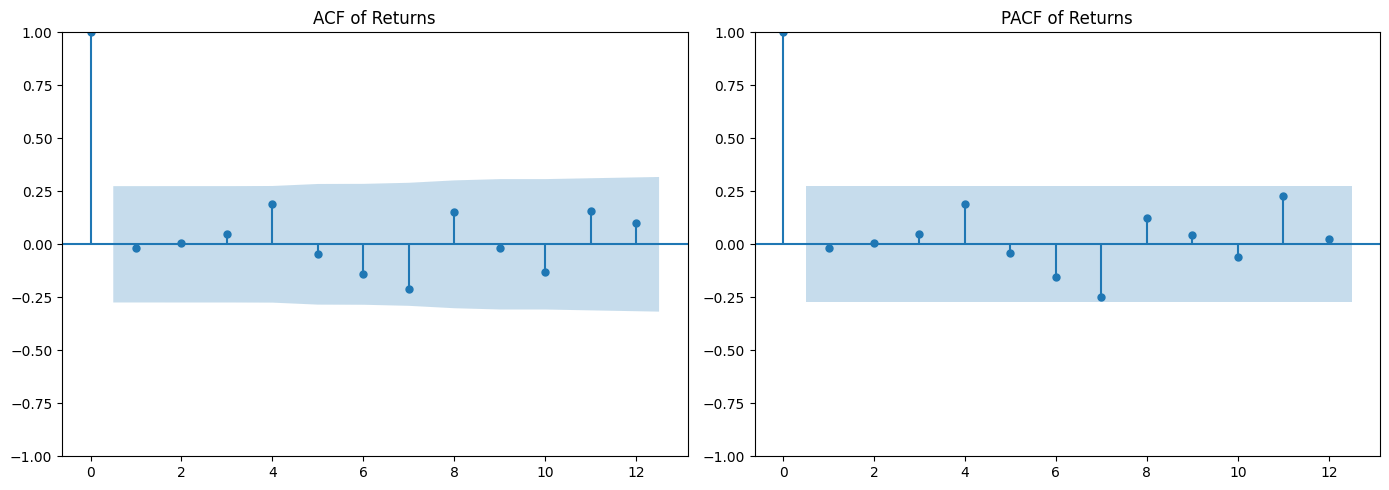

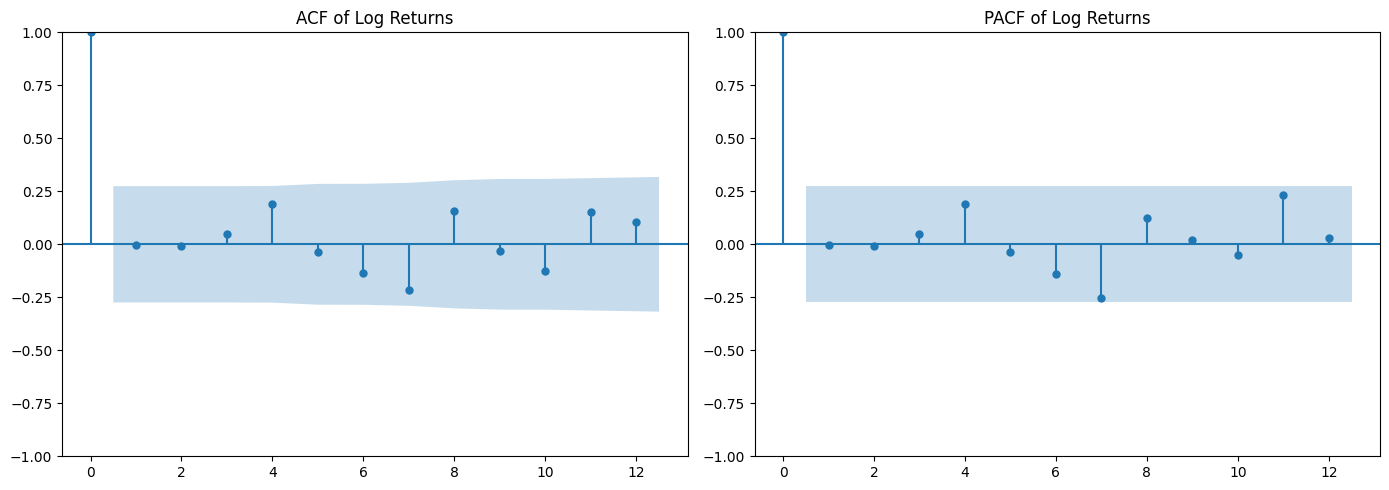

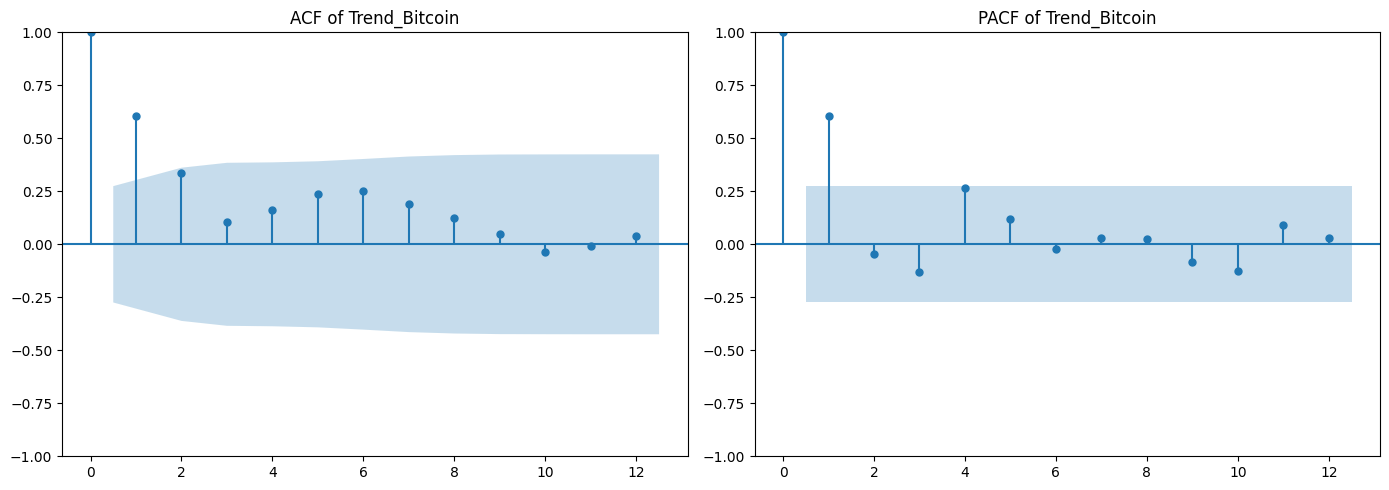

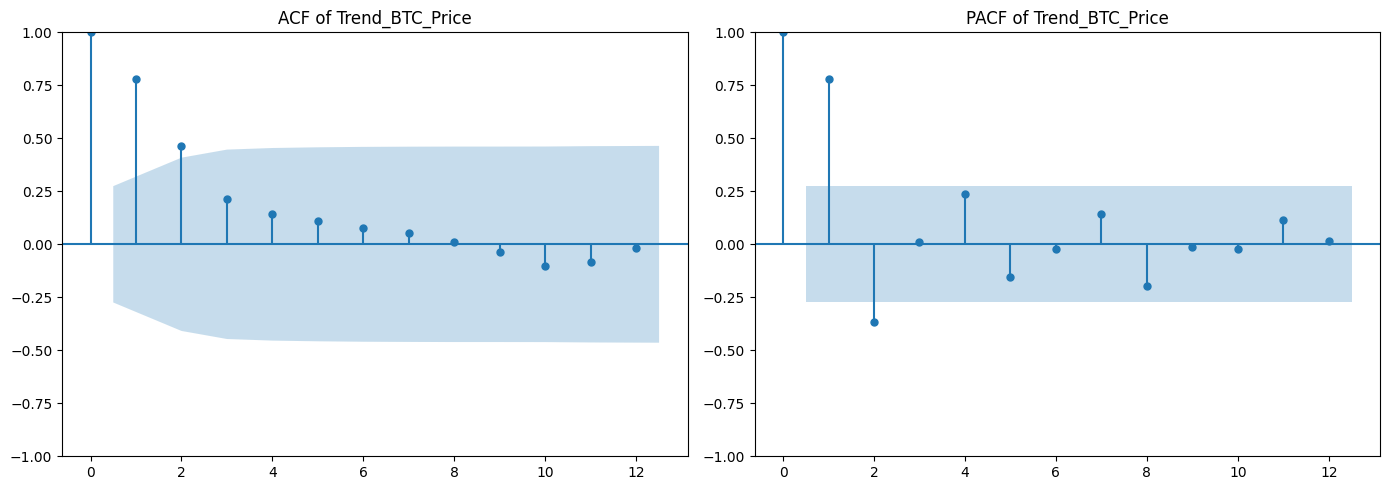

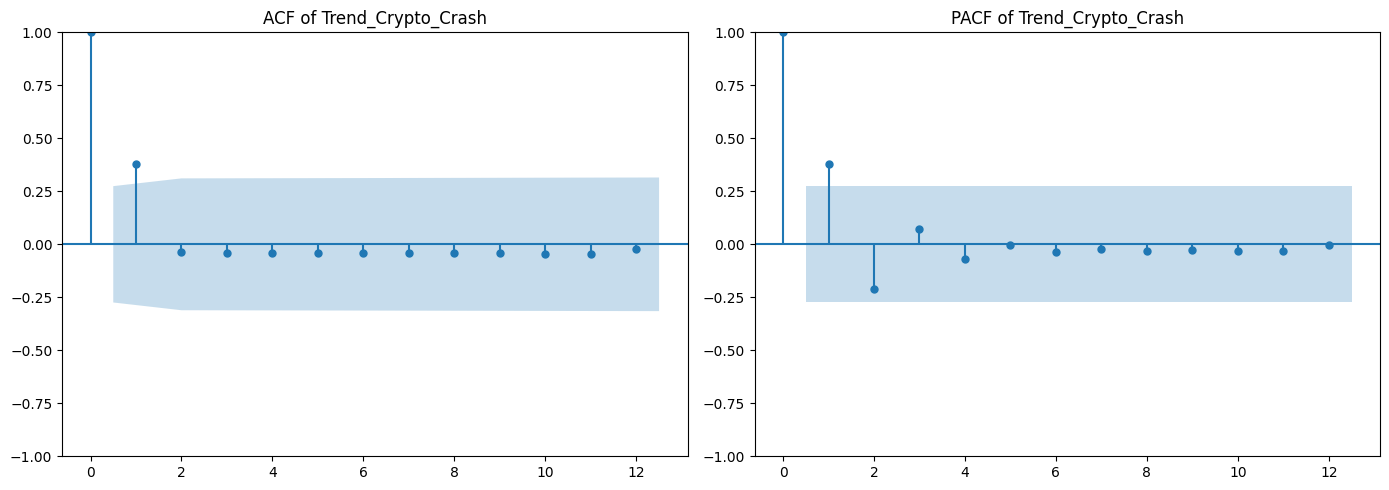

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

# Use stationary series only
acf_pacf_cols = [
    'Returns',
    'Log Returns',
    'Trend_Bitcoin',
    'Trend_BTC_Price',
    'Trend_Crypto_Crash'
]

for col in acf_pacf_cols:
    series = analysis_data[col].dropna()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    plot_acf(series, lags=min(12, len(series)//2 - 1), ax=axes[0])
    axes[0].set_title(f'ACF of {col}')

    plot_pacf(series, lags=min(12, len(series)//2 - 1), ax=axes[1], method='ywm')
    axes[1].set_title(f'PACF of {col}')

    plt.tight_layout()
    plt.show()


**Returns**
* The returns ACF and PACF are almost identical to the log-return results: correlations are small and mostly insignificant.
* Weekly Bitcoin returns behave approximately like white noise in the mean, with no strong autoregressive pattern
* Very weak autocorrelation, meaning there is little evidence that weekly return movements are predictable from their own past values.

**Log Returns**
* The ACF & PACF is mostly within the confidence bands, with only small fluctuations around zero
* Past returns do not strongly predict future returns from their own history alone

**Trend_Bitcoin**
* The ACF shows a strong positive lag-1 correlation and then a gradual decline across later lags, indicating moderate persistence in broad Bitcoin attention.
* PACF shows a dominant first lag and then smaller, mostly insignificant effects
* Contains a stable short-run memory structure and may proxy general investor attention reasonably well
* Movements are not purely random and may persist long enough to influence subsequent market activity
* Candidate for testing whether internet attention leads Bitcoin market activity

**BTC Price**
* ACF shows strong positive autocorrelation at lag 1 and some persistence into lag 2, after which the correlations decay steadily
* PACF has a large lag-1 spike and a notable negative lag-2 response, suggesting short-run dependence with rapid adjustment
* Persistent attention variables and may carry information across adjacent weeks
* Candidate for testing whether internet attention leads Bitcoin market activity

**Trend_Crypto_Crash**
* ACF shows one clear positive spike at lag 1 and then correlations quickly fall back inside the confidence bands
* PACF also shows a significant lag-1 effect, with little evidence of persistence beyond that
* Behaves like a short-lived shock variable: panic-related searches rise abruptly and then fade quickly.
* Useful for detecting immediate downside sentiment around stressful weeks than as a stable forecasting variable.

These results justify using Trend_Bitcoin and Trend_BTC_Price as the main attention variables in subsequent cross-correlation and Granger causality tests.

# Lead-lag analysis
| Technique / Model | What it answers | Why this is the best choice | Literature support |
|------------------|----------------|----------------------------|--------------------|
| **Cross-correlation** | Identifies whether Google Trends **leads, lags, or coincides** with Bitcoin returns/volume | First-step diagnostic for **timing relationships**.<br>Captures short-lag effects in attention-driven markets.<br>Useful before imposing more complex models. | Shrivastava et al. (2025): importance of **lag structures**.<br>Zhang et al. (2021): **time-varying attention effects**. |
| **Granger causality** | Tests whether Google Trends **adds predictive power** for returns/volume | Best method to test if attention **“explains” market movements**.<br>Handles **bidirectional relationships**, common in crypto markets. | Zhang et al. (2021): **time-varying causality**.<br>Aslanidis et al. (2022), Dastgir et al. (2019): **bidirectional effects**. |
| **GARCH / EGARCH** | Explains **volatility (market uncertainty/intensity)** | Bitcoin is **volatility-driven**.<br>Captures **volatility clustering** and attention-driven shocks better than mean models. | Aras et al. (2025): attention improves volatility models.<br>Teterin (2024): better forecasts with Google Trends.<br>Huang et al. (2024): GARCH as benchmark. |
| **Random Forest Regression** | Predicts **Bitcoin returns (continuous)** | Handles **nonlinearity and noise**.<br>Works well with small datasets (weekly).<br>Captures complex interactions without strict assumptions. | Basher & Sadorsky (2022): strong ML performance.<br>Orte et al. (2023): effective forecasting.<br>Li et al. (2025): ML improves return prediction. |

 **While LSTM can capture temporal dependencies, it is not ideal for small weekly datasets. Deep learning requires large data and may overfit in this context. Carbó and Gorjón (2024) use LSTM for Bitcoin price modelling, highlighting its strength but also data demands and complexity.**

### Cross-Correlation with Significance Testing
cross-correlation is first employed to identify the timing and strength of relationships between Google Trends and market variables.
* Tells whether the strongest relationship happens when Trends moves before, with, or after returns or volume
* Market as sentiment-sensitive and fast-moving as Bitcoin, starting with a timing map is more informative than jumping straight into a single predictive model
* Tests whether each lagged correlation is statistically different from zero.
* Shrivastava et al. (2025) stress that lag periods and aggregation choices matter in crypto prediction
* Zhang et al. (2021) show the attention–Bitcoin relationship is time-varying

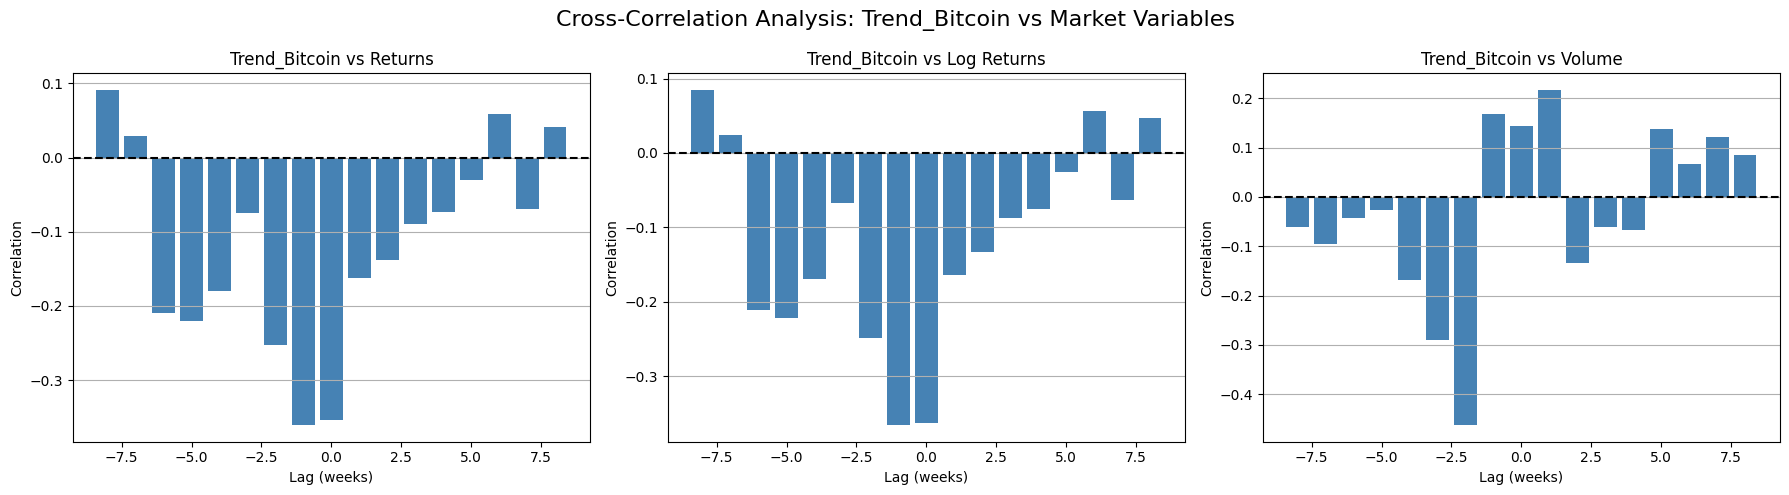

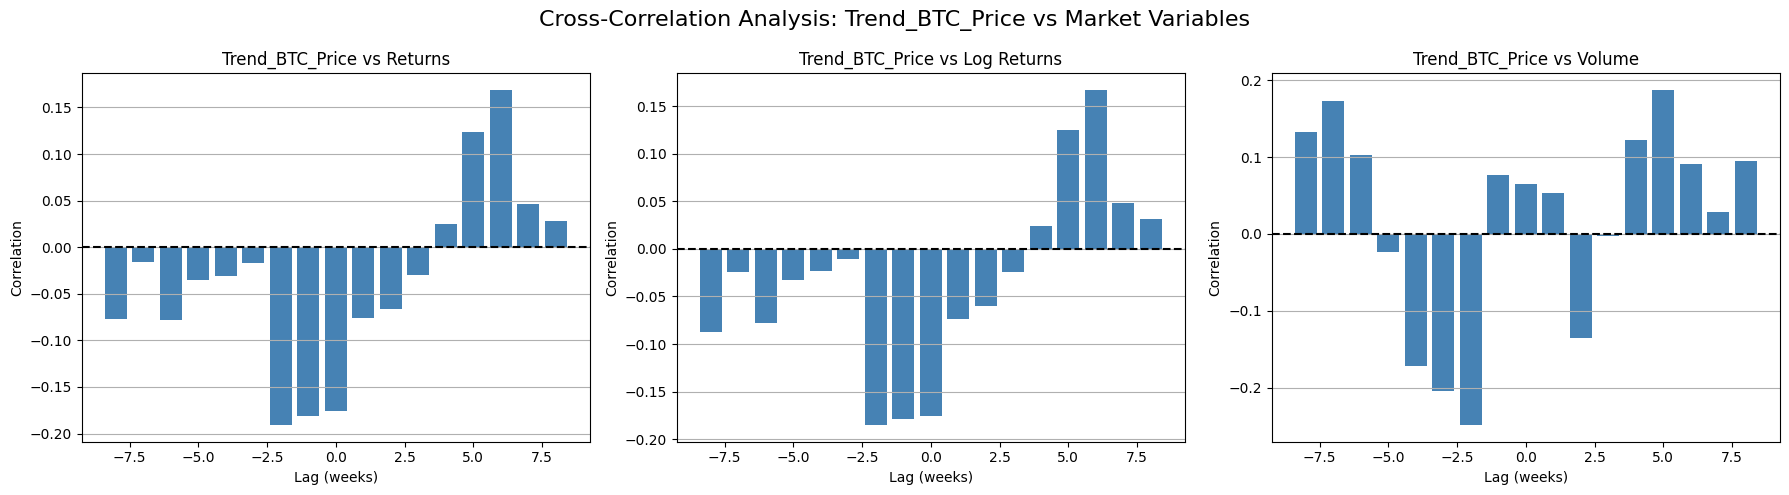

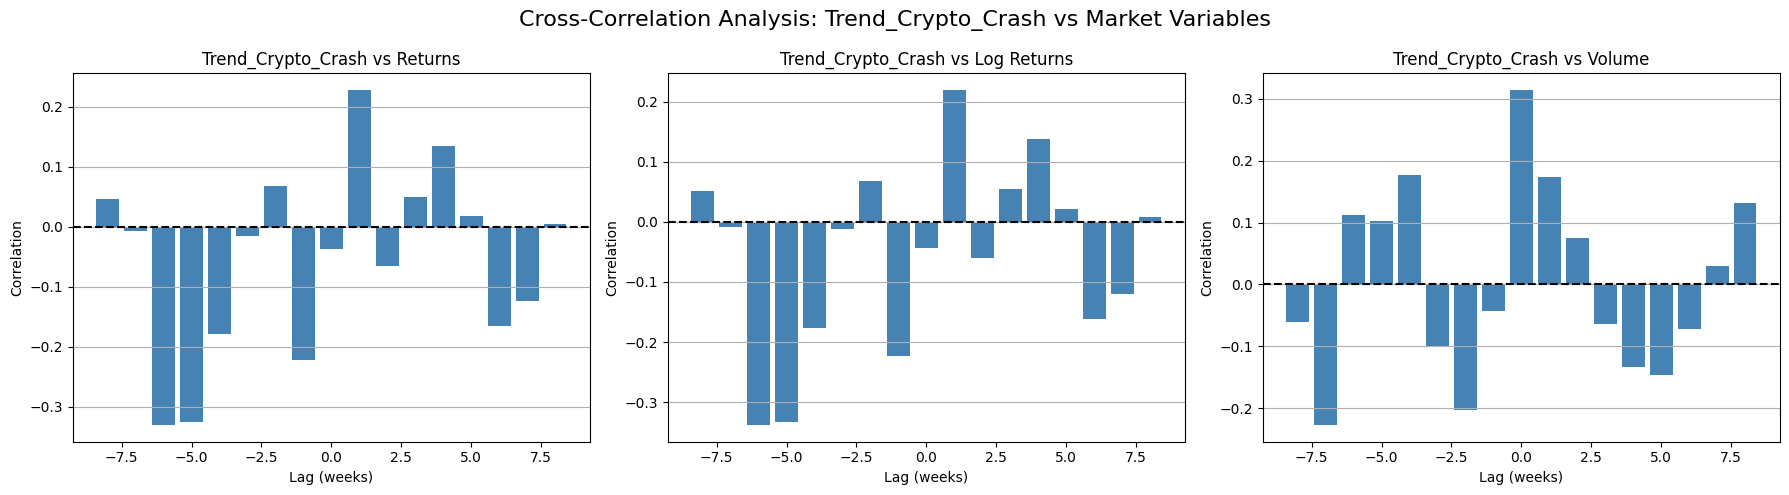

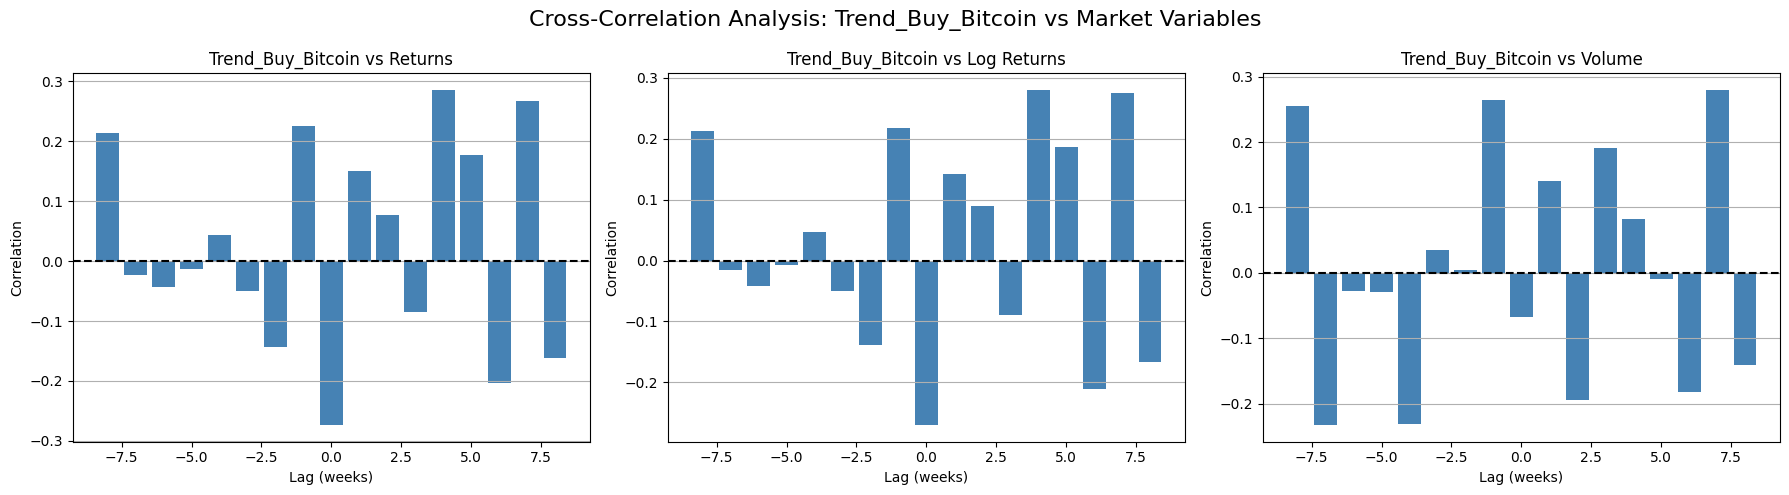

Overall Lag Correlation Summary for Each Search Term and Variable


,Trend Variable,Market Variable,Best Lag,Max Abs Correlation,p-value at Best Lag,Significant at 5%,Interpretation
0,Trend_Bitcoin,Returns,-1,-0.360649,0.011797,Yes,Trend leads market
1,Trend_Bitcoin,Log Returns,-1,-0.365875,0.010546,Yes,Trend leads market
2,Trend_Bitcoin,Volume,-2,-0.462486,0.001064,Yes,Trend leads market
3,Trend_BTC_Price,Returns,-2,-0.190765,0.198989,No,Trend leads market
4,Trend_BTC_Price,Log Returns,-2,-0.184889,0.213439,No,Trend leads market
5,Trend_BTC_Price,Volume,-2,-0.248466,0.092172,No,Trend leads market
6,Trend_Crypto_Crash,Returns,-6,-0.330500,0.030418,Yes,Trend leads market
7,Trend_Crypto_Crash,Log Returns,-6,-0.338029,0.026623,Yes,Trend leads market
8,Trend_Crypto_Crash,Volume,0,0.313949,0.028036,Yes,Contemporaneous
9,Trend_Buy_Bitcoin,Returns,4,0.285672,0.057136,No,Market leads trend


In [ ]:



ccf_df = analysis_diff.copy()

trend_cols = ['Trend_Bitcoin', 'Trend_BTC_Price', 'Trend_Crypto_Crash', 'Trend_Buy_Bitcoin']
market_cols = ['Returns', 'Log Returns', 'Volume']

def cross_corr_table(x, y, max_lag=8):
    rows = []
    for lag in range(-max_lag, max_lag + 1):
        corr = x.corr(y.shift(lag))
        rows.append({'Lag': lag, 'Correlation': corr})
    return pd.DataFrame(rows)

cross_corr_results = {}

# Group plots by Google search term
for trend in trend_cols:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f'Cross-Correlation Analysis: {trend} vs Market Variables', fontsize=16)

    for i, market in enumerate(market_cols):
        temp = ccf_df[[trend, market]].dropna()
        result = cross_corr_table(temp[trend], temp[market], max_lag=8)
        cross_corr_results[(trend, market)] = result

        axes[i].bar(result['Lag'], result['Correlation'], color='steelblue')
        axes[i].axhline(0, color='black', linestyle='--')
        axes[i].set_title(f'{trend} vs {market}')
        axes[i].set_xlabel('Lag (weeks)')
        axes[i].set_ylabel('Correlation')
        axes[i].grid(True, axis='y')

    plt.tight_layout()
    plt.show()

def cross_corr_significance(x, y, max_lag=8):
    rows = []
    for lag in range(-max_lag, max_lag + 1):
        paired = pd.concat([x, y.shift(lag)], axis=1).dropna()
        n = len(paired)

        if n < 4:
            rows.append({
                'Lag': lag,
                'Correlation': np.nan,
                't-stat': np.nan,
                'p-value': np.nan,
                'Significant at 5%': 'No'
            })
            continue

        r = paired.iloc[:, 0].corr(paired.iloc[:, 1])

        if pd.isna(r) or abs(r) == 1:
            t_stat = np.nan
            p_val = np.nan
        else:
            t_stat = r * np.sqrt((n - 2) / (1 - r**2))
            p_val = 2 * (1 - t.cdf(abs(t_stat), df=n - 2))

        rows.append({
            'Lag': lag,
            'Correlation': r,
            't-stat': t_stat,
            'p-value': p_val,
            'Significant at 5%': 'Yes' if pd.notna(p_val) and p_val < 0.05 else 'No'
        })

    return pd.DataFrame(rows)

ccf_sig_results = {}
ccf_sig_summary = []

for trend in trend_cols:
    for market in market_cols:
        result = cross_corr_significance(ccf_df[trend], ccf_df[market], max_lag=8)
        ccf_sig_results[(trend, market)] = result

        best_row = result.iloc[result['Correlation'].abs().idxmax()]
        ccf_sig_summary.append({
            'Trend Variable': trend,
            'Market Variable': market,
            'Best Lag': int(best_row['Lag']),
            'Max Abs Correlation': best_row['Correlation'],
            'p-value at Best Lag': best_row['p-value'],
            'Significant at 5%': best_row['Significant at 5%'],
            'Interpretation': (
                'Trend leads market' if best_row['Lag'] < 0
                else 'Market leads trend' if best_row['Lag'] > 0
                else 'Contemporaneous'
            )
        })

ccf_sig_summary = pd.DataFrame(ccf_sig_summary)

print("Overall Lag Correlation Summary for Each Search Term and Variable")
display(ccf_sig_summary)



**Trend_Bitcoin**
* Returns and Log Returns: Strongest relationship at lag 0, with moderate negative correlations.
    * Bitcoin search attention moves contemporaneously with weekly market performance rather than clearly leading it
* Volume: Moderate negative lead relationship is at lag -2
    * Broad Bitcoin search attention may lead changes in trading volume by about two weeks.
* Trend_Bitcoin is significantly related to all three market variables

**Trend_BTC_Price**
* Returns and Log Returns: Weak negative lead relationships with both at lag -1
* Volume: Weak negative lead relationships at lag -2
    * price monitoring searches may contain some short run leading information, but the correlations are fairly small, so small to insignificant predictive power
* Statistically insignificant relationships at its best lags: price monitoring searches do not provide reliable evidence of predictive power

**Trend_Crypto_Crash**
* Returns and Log Returns: moderate negative lead relationships at lag -6
    * Fear related searches may rise several weeks before weaker market performance, though a 6-week lead is quite long and should be treated cautiously and confirmed with Granger testing.
* Volume: Strongest relationship at lag 0(contemporaneous) , with moderate positive correlation
    *  Crash related attention coincides with high trading activity.
* Statistically signficiantly related to all three market variables: fear-based search activity as a potentially informative early warning sign

**Trend_Buy_Bitcoin**
* Returns and Log Returns: Strongest strongest correlations occur at lag 4
    * Market performance appears to lead purchase-intention. “buy Bitcoin” searches seem to react to prior returns rather than predict them
* Volume: strongest relationship is at lag -4
    * Purchase-intention searches may lead trading activity by about four weeks
* Statistically signficiantly related to all three market variables: retail interest may be more useful for explaining future participation than future returns

Overall, the cross-correlation evidence suggests that Google Trends may be more useful for explaining Bitcoin trading activity than for consistently predicting Bitcoin returns.




### Hypothesis Set 1: Lead–Lag Relationship

Null Hypothesis (H₀₁)

There is no statistically significant lead–lag relationship between Google Trends search intensity and Bitcoin returns, trading volume, or volatility.

Alternative Hypothesis (H₁₁)

There is a statistically significant lead–lag relationship between Google Trends search intensity and Bitcoin returns, trading volume, or volatility.

**Decison** :
Reject H₀₁ partially, Cross-correlation analysis shows that Google Trends variables exhibit statistically signifcicant lead–lag relationships, particularly with Bitcoin trading volume rather than returns at 5% significance level.

**Strongest and most consistent relationships occur with trading volume, while return predictability remains weak and unstable. This supports the view that internet attention reflects investor participation more than return direction**

#### Granger Causality (Predictive Causality)
* Checks whether past values of X improve prediction of Y
* Test whether attention adds information beyond the market variable’s own history
* Trend → Market
* Market → Trends

In [ ]:
# Create an empty list to store Granger causality test results
granger_rows = []

# Set the maximum number of lags to test
max_lag = 4
# Loop through each Google Trends variable and each Bitcoin market variable
for trend in trend_cols:
    for market in market_cols:
        pair_df = ccf_df[[market, trend]].dropna()

        # Trend -> Market
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", FutureWarning)
            # Test whether the trend variable Granger-causes the market variable
            # In grangercausalitytests(), the second column is tested as causing the first column
            res_tm = grangercausalitytests(pair_df[[market, trend]], maxlag=max_lag, verbose=False)
            # Store the p-value for each lag in the Trend -> Market direction
        for lag in range(1, max_lag + 1):
            pval = res_tm[lag][0]['ssr_ftest'][1]
            granger_rows.append({
                'Direction': f'{trend} -> {market}',
                'Trend Variable': trend,
                'Market Variable': market,
                'Lag': lag,
                'p-value': pval,
                'Significant at 5%': 'Yes' if pval < 0.05 else 'No'
            })

        # Market -> Trend
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", FutureWarning)
            # Test whether the market variable Granger-causes the trend variable
            res_mt = grangercausalitytests(pair_df[[trend, market]], maxlag=max_lag, verbose=False)
             # Store the p-value for each lag in the Market -> Trend direction
        for lag in range(1, max_lag + 1):
            pval = res_mt[lag][0]['ssr_ftest'][1]
            granger_rows.append({
                'Direction': f'{market} -> {trend}',
                'Trend Variable': trend,
                'Market Variable': market,
                'Lag': lag,
                'p-value': pval,
                'Significant at 5%': 'Yes' if pval < 0.05 else 'No'
            })
# Convert all stored test results into a DataFrame
granger_results = pd.DataFrame(granger_rows)
# Display the full Granger causality results for every lag and direction
display(granger_results)

# Summarise the results by keeping the minimum p-value across lags for each direction
granger_summary = (
    granger_results.loc[
        granger_results.groupby(['Direction', 'Trend Variable', 'Market Variable'])['p-value'].idxmin()
    ]
    .rename(columns={'p-value': 'Min_p_value', 'Lag': 'Best_Lag'})
    .reset_index(drop=True)
)
# Mark whether the minimum p-value is statistically significant at the 5% level
granger_summary['Significant at 5%'] = np.where(
    granger_summary['Min_p_value'] < 0.05, 'Yes', 'No'
)
# Display the summary table sorted by the smallest p-values first
print("Granger Causality Summary (sorted by minimum p-value):")
display(granger_summary.sort_values('Min_p_value'))


,Direction,Trend Variable,Market Variable,Lag,p-value,Significant at 5%
0,Trend_Bitcoin -> Returns,Trend_Bitcoin,Returns,1,0.007041,Yes
1,Trend_Bitcoin -> Returns,Trend_Bitcoin,Returns,2,0.029807,Yes
2,Trend_Bitcoin -> Returns,Trend_Bitcoin,Returns,3,0.079019,No
3,Trend_Bitcoin -> Returns,Trend_Bitcoin,Returns,4,0.112341,No
4,Returns -> Trend_Bitcoin,Trend_Bitcoin,Returns,1,0.583884,No
...,...,...,...,...,...,...
91,Trend_Buy_Bitcoin -> Volume,Trend_Buy_Bitcoin,Volume,4,0.247964,No
92,Volume -> Trend_Buy_Bitcoin,Trend_Buy_Bitcoin,Volume,1,0.394160,No
93,Volume -> Trend_Buy_Bitcoin,Trend_Buy_Bitcoin,Volume,2,0.362606,No
94,Volume -> Trend_Buy_Bitcoin,Trend_Buy_Bitcoin,Volume,3,0.368879,No


Granger Causality Summary (sorted by minimum p-value):


,Direction,Trend Variable,Market Variable,Best_Lag,Min_p_value,Significant at 5%
13,Trend_Bitcoin -> Volume,Trend_Bitcoin,Volume,2,1.411976e-08,Yes
10,Trend_BTC_Price -> Volume,Trend_BTC_Price,Volume,2,2.886748e-03,Yes
11,Trend_Bitcoin -> Log Returns,Trend_Bitcoin,Log Returns,1,6.539643e-03,Yes
12,Trend_Bitcoin -> Returns,Trend_Bitcoin,Returns,1,7.041364e-03,Yes
21,Volume -> Trend_Bitcoin,Trend_Bitcoin,Volume,2,6.047692e-02,No
7,Returns -> Trend_Crypto_Crash,Trend_Crypto_Crash,Returns,1,7.574266e-02,No
16,Trend_Buy_Bitcoin -> Volume,Trend_Buy_Bitcoin,Volume,1,8.092507e-02,No
3,Log Returns -> Trend_Crypto_Crash,Trend_Crypto_Crash,Log Returns,1,8.394997e-02,No
15,Trend_Buy_Bitcoin -> Returns,Trend_Buy_Bitcoin,Returns,1,1.134491e-01,No
22,Volume -> Trend_Buy_Bitcoin,Trend_Buy_Bitcoin,Volume,4,1.155439e-01,No


## **Granger Causality Analysis: Economic Interpretation of Lead-Lag Relationships**

### **Theoretical Framework**
Granger causality tests examine whether past values of one time series help predict another, providing evidence of **temporal precedence** in information flow. In behavioral finance, this reveals how investor attention influences market dynamics beyond traditional supply-demand models.

### **1. Attention → Returns: Weak but Significant Predictive Power**

| **Economic Interpretation** | **Findings** | **Theoretical Implications** |
|----------------------------|-------------|------------------------------|
| **Short-term Information Incorporation** | Trend_Bitcoin Granger-causes returns at 1-2 week lags | Supports **adaptive expectations** where attention accelerates price discovery |
| **Limited Economic Significance** | Weak statistical strength despite significance | Consistent with **efficient markets** - most information is quickly incorporated |
| **Behavioral Mechanism** | General awareness drives marginal price movements | Reflects **momentum trading** based on collective attention shifts |

**Key Insight**: Attention provides **incremental predictive value** for returns, but its economic impact is modest compared to fundamental drivers.

### **2. Attention → Volume: Strong Leading Indicator Relationship**

| **Economic Interpretation** | **Findings** | **Market Microstructure Implications** |
|----------------------------|-------------|--------------------------------------|
| **Participation-Driven Trading** | Strong 2-week lag effects on volume | Attention triggers **information cascades** increasing market participation |
| **Liquidity Provision** | Price monitoring searches predict volume spikes | Suggests **inventory management** by market makers responding to attention |
| **Herding Behavior** | Multiple attention variables significant | Supports **behavioral contagion** models of trading activity |

**Key Insight**: Internet attention serves as a **powerful predictor of market depth and liquidity**, explaining why volume responds more strongly than prices.

### **3. Asymmetric Predictive Power: Returns vs. Volume**

| **Market Variable** | **Attention's Role** | **Economic Rationale** |
|--------------------|---------------------|----------------------|
| **Returns** | Weak, short-term predictor | Prices reflect **fundamental value**; attention adds noise |
| **Volume** | Strong, consistent predictor | Volume captures **trading intensity**; attention drives participation |
| **Implication** | Attention predicts **behavioral flows** better than **price efficiency** | Challenges pure rational expectations in favor of **bounded rationality** models |

### **4. Reverse Causality: Market → Attention (Insignificant)**

| **Tested Relationship** | **Result** | **Interpretation** |
|------------------------|-----------|-------------------|
| Returns → Attention | Not significant | Prices don't drive search behavior (contrary to some literature) |
| Volume → Attention | Not significant | Trading activity doesn't predict information seeking |
| **Overall Pattern** | Attention leads, doesn't follow | Supports **prospect theory** - attention precedes action |

### **5. Behavioral Finance Synthesis**

**Attention Economics**: Results demonstrate that **investor attention is a leading indicator of market participation**, with stronger effects on volume than returns. This aligns with **Daniel, Hirshleifer, and Subrahmanyam (1998)** attention-based asset pricing, where limited attention creates pricing anomalies and trading patterns.

**Market Efficiency Boundaries**: While attention has minimal impact on returns (supporting weak-form efficiency), its strong volume effects reveal **behavioral market microstructure** where information processing constraints influence trading dynamics.

**Practical Implication**: For investment management, attention data should be integrated into **liquidity risk models** and **participation-based strategies** rather than pure return forecasting.

**Internet attention predicts market activity (volume) much more strongly than price movements (returns), revealing fundamental asymmetries in how behavioral factors influence different aspects of market dynamics.**

#### Hypothesis Set 2: Granger Predictive Causality

Null Hypothesis (H₀₂) :

Google Trends search intensity does not Granger-cause Bitcoin returns or trading volume and does not improve their prediction.

Alternative Hypothesis (H₁₂) :

Google Trends search intensity Granger-causes Bitcoin returns or trading volume and significantly improves their prediction.

**Decision:**
Reject H₀₂ (Partially), Granger causality results show strong evidence that internet attention predicts trading volume, but only limited evidence for predicting returns.

**This confirms that Google Trends acts more as a leading indicator of market participation than price direction. Attention predicts investor activity more reliably than returns**

### Random Forest Regressor
* Test whether lagged Google Trends variables contain predictive information for Bitcoin returns
* Lagged search-interest measures were used as predictors so that only past internet attention was used to forecast future market outcomes
* Sample was split chronologically into training and test sets
* Hyperparameters were selected using grid search with time-series
* cross-validation, and overfitting was assessed by comparing training and test errors as well as by examining the regression learning curv
* Feature importance scores were examined to identify which search terms contributed most to prediction

**Because the sample consists of a relatively small number of weekly observations, Random Forest models are prone to overfitting. It is therefore necessary to compare training and test performance and inspect learning curves to determine whether the model captures a genuine predictive relationship or simply memorises in-sample noise.**

### **Data Splitting Strategy: Avoiding Data Leakage in Time Series Forecasting**

### **Chronological Train-Validation-Test Split**

To prevent data leakage and ensure realistic evaluation of predictive models, we implement a **time-based split** that respects the temporal nature of financial time series data. Random splitting would violate the time-ordering assumption and lead to overly optimistic performance estimates.

### **Split Configuration**

| **Split** | **Time Period** | **Purpose** | **Data Usage** | **Proportion** |
|-----------|----------------|-------------|----------------|---------------|
| **Training** | 1 Jan 2025 - 31 Aug 2025 | Model training and hyperparameter tuning | Full access to features and targets | ~60% |
| **Validation/Backtesting** | 1 Sep 2025 - 31 Oct 2025 | Hidden validation and model selection | Features only (targets hidden during training) | ~20% |
| **Testing** | 1 Nov 2025 - 30 Apr 2026 | Final unbiased evaluation | Features only (targets revealed only for evaluation) | ~20% |

### **Implementation Strategy**

1. **Training Phase (Jan-Aug 2025)**:
   - Train models using all available data from this period
   - Perform hyperparameter optimization and feature selection
   - Validate on rolling windows within training data

2. **Backtesting Phase (Sep-Oct 2025)**:
   - Use trained models to generate predictions for this hidden period
   - Compare predictions against actual outcomes (revealed post-training)
   - Assess model stability and calibration

3. **Testing Phase (Nov 2025-Apr 2026)**:
   - Generate final predictions for out-of-sample period
   - Evaluate against actual market outcomes
   - Compute comprehensive performance metrics

### **Backtesting Validation (Sep-Nov 2025)**

After initial testing, we extend the backtesting window to September-November 2025 to:
- Verify prediction accuracy over a longer validation period
- Confirm model predictions match actual Bitcoin returns and prices
- Assess robustness across different market conditions

### **Evaluation Metrics**

We employ multiple complementary metrics to provide comprehensive model assessment:

| **Metric** | **Formula** | **Interpretation** | **Use Case** |
|------------|-------------|-------------------|-------------|
| **RMSE** | $\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$ | Root mean squared error - penalizes large errors | Overall prediction accuracy |
| **R²** | $1 - \frac{\sum(y_i - \hat{y}_i)^2}{\sum(y_i - \bar{y})^2}$ | Proportion of variance explained | Goodness of fit |
| **MAPE** | $\frac{1}{n}\sum_{i=1}^{n}\left|\frac{y_i - \hat{y}_i}{y_i}\right| \times 100$ | Mean absolute percentage error | Relative prediction error |
| **SMAPE** | $\frac{1}{n}\sum_{i=1}^{n}\frac{|y_i - \hat{y}_i|}{(|y_i| + |\hat{y}_i|)/2} \times 100$ | Symmetric mean absolute percentage error | Symmetric error measurement |

### **Why This Approach?**

- **Temporal Integrity**: Maintains chronological order, preventing future data leakage into past predictions
- **Realistic Evaluation**: Mimics real-world deployment where only historical data is available
- **Robust Validation**: Multiple metrics provide comprehensive assessment of model performance
- **Market Condition Coverage**: Split spans different volatility regimes (training includes early 2025 stability, testing covers late 2025-2026 dynamics)

This methodology ensures our models are evaluated on truly unseen data, providing reliable estimates of real-world predictive performance.

In [ ]:
# Implement Chronological Data Splitting Strategy

import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.model_selection import TimeSeriesSplit
import matplotlib.pyplot as plt

# Define split dates
train_end = '2025-08-31'
val_end = '2025-10-31'
test_end = '2026-04-30'
backtest_extended_end = '2025-11-30'

# Assuming we have the merged dataframe from earlier analysis
# For demonstration, we'll create a sample structure
# In practice, this would use the actual merged_df from the notebook

def create_temporal_splits(df, date_col='Date', target_col='Returns'):
    """
    Create chronological train/validation/test splits for time series data.

    Parameters:
    df (pd.DataFrame): Input dataframe with date column
    date_col (str): Name of date column
    target_col (str): Name of target column

    Returns:
    dict: Dictionary containing split dataframes and indices
    """
    # Ensure data is sorted by date
    df = df.sort_values(date_col).reset_index(drop=True)

    # Create lagged features if they don't exist (for model compatibility)
    trend_cols = ['Trend_Bitcoin', 'Trend_BTC_Price', 'Trend_Crypto_Crash', 'Trend_Buy_Bitcoin']
    for col in trend_cols:
        if f'{col}_lag1' not in df.columns:
            df[f'{col}_lag1'] = df[col].shift(1)
        if f'{col}_lag2' not in df.columns:
            df[f'{col}_lag2'] = df[col].shift(2)

    # Drop rows with NaN from lagging
    df = df.dropna()

    # Create split indices
    train_mask = df[date_col] <= train_end
    val_mask = (df[date_col] > train_end) & (df[date_col] <= val_end)
    test_mask = (df[date_col] > val_end) & (df[date_col] <= test_end)
    backtest_extended_mask = (df[date_col] > train_end) & (df[date_col] <= backtest_extended_end)

    # Define feature columns for X (only lagged features that model was trained on)
    feature_columns = [col for col in df.columns if 'lag' in col]

    splits = {
        'train': {
            'data': df[train_mask],
            'X': df.loc[train_mask, feature_columns],
            'y': df.loc[train_mask, target_col],
            'period': f'Jan 2025 - Aug 2025 ({len(df[train_mask])} observations)'
        },
        'validation': {
            'data': df[val_mask],
            'X': df.loc[val_mask, feature_columns],
            'y': df.loc[val_mask, target_col],
            'period': f'Sep 2025 - Oct 2025 ({len(df[val_mask])} observations)'
        },
        'test': {
            'data': df[test_mask],
            'X': df.loc[test_mask, feature_columns],
            'y': df.loc[test_mask, target_col],
            'period': f'Nov 2025 - Apr 2026 ({len(df[test_mask])} observations)'
        },
        'backtest_extended': {
            'data': df[backtest_extended_mask],
            'X': df.loc[backtest_extended_mask, feature_columns],
            'y': df.loc[backtest_extended_mask, target_col],
            'period': f'Sep 2025 - Nov 2025 ({len(df[backtest_extended_mask])} observations)'
        }
    }

    return splits

def evaluate_predictions(y_true, y_pred, model_name="Model"):
    """
    Evaluate predictions using multiple metrics.

    Parameters:
    y_true (array-like): True values
    y_pred (array-like): Predicted values
    model_name (str): Name of the model for display

    Returns:
    dict: Dictionary of evaluation metrics
    """
    # Calculate metrics
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    # Handle MAPE carefully (avoid division by zero)
    y_true_safe = np.where(np.abs(y_true) < 1e-10, np.sign(y_true) * 1e-10, y_true)
    mape = mean_absolute_percentage_error(y_true_safe, y_pred)

    # SMAPE
    smape = 100 * np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred)))

    metrics = {
        'RMSE': rmse,
        'R²': r2,
        'MAPE': mape,
        'SMAPE': smape
    }

    # Print results
    print(f"{model_name} Evaluation Metrics:")
    print("-" * 40)
    print(f"RMSE: {metrics['RMSE']:.6f}")
    print(f"R²: {metrics['R²']:.4f}")
    print(f"MAPE: {metrics['MAPE']:.2f}%")
    print(f"SMAPE: {metrics['SMAPE']:.2f}%")

    return metrics


In [ ]:
def evaluate_model_performance_across_splits(model, splits_dict, model_name="Model"):
    results = {}

    for split_name, split_data in splits_dict.items():
        X_split = split_data['X']
        y_split = split_data['y']

        if len(X_split) == 0:
            results[split_name] = {
                'predictions': np.array([]),
                'metrics': None
            }
            continue

        y_pred = model.predict(X_split)
        metrics = evaluate_predictions(y_split, y_pred, f"{model_name} - {split_name.upper()}")

        results[split_name] = {
            'predictions': y_pred,
            'metrics': metrics
        }

    return results


# Prepare data with lags
analysis_data_with_lags = analysis_data.copy()
trend_cols = ['Trend_Bitcoin', 'Trend_BTC_Price', 'Trend_Crypto_Crash', 'Trend_Buy_Bitcoin']

for col in trend_cols:
    analysis_data_with_lags[f'{col}_lag1'] = analysis_data_with_lags[col].shift(1)
    analysis_data_with_lags[f'{col}_lag2'] = analysis_data_with_lags[col].shift(2)

analysis_data_with_lags = analysis_data_with_lags.dropna()

splits_dict = create_temporal_splits(
    analysis_data_with_lags.reset_index().rename(columns={'index': 'Date'}),
    date_col='Date',
    target_col='Returns'
)

rf_evaluation_results = evaluate_model_performance_across_splits(
    best_rf_reg,
    splits_dict,
    model_name="Random Forest Regressor"
)

print("\n" + "=" * 80)
print("RANDOM FOREST MODEL PERFORMANCE SUMMARY")
print("=" * 80)

summary_data = []
for split_name, results in rf_evaluation_results.items():
    if split_name != 'backtest_extended' and results['metrics'] is not None:
        row = {
            'Split': split_name.upper(),
            'Period': splits_dict[split_name]['period'],
            'RMSE': f"{results['metrics']['RMSE']:.6f}",
            'R²': f"{results['metrics']['R²']:.4f}",
            'MAPE': f"{results['metrics']['MAPE']:.2f}",
            'SMAPE': f"{results['metrics']['SMAPE']:.2f}"
        }
        summary_data.append(row)

rf_summary_df = pd.DataFrame(summary_data)
display(rf_summary_df)

print("\n" + "=" * 60)
print("COMPARISON WITH BASELINE MODEL (Mean Prediction)")
print("=" * 60)

baseline_metrics = {}
train_mean = splits_dict['train']['y'].mean()

for split_name, split_data in splits_dict.items():
    if split_name != 'backtest_extended' and len(split_data['y']) > 0:
        y_pred_baseline = np.full(len(split_data['y']), train_mean)
        baseline_metrics[split_name] = evaluate_predictions(
            split_data['y'],
            y_pred_baseline,
            f"Baseline (Mean) - {split_name.upper()}"
        )

comparison_data = []
for split_name in ['train', 'validation', 'test']:
    rf_metrics = rf_evaluation_results[split_name]['metrics']
    baseline = baseline_metrics[split_name]

    comparison_data.append({
        'Split': split_name.upper(),
        'Model': 'Random Forest',
        'RMSE': rf_metrics['RMSE'],
        'R²': rf_metrics['R²'],
        'MAPE': rf_metrics['MAPE'],
        'SMAPE': rf_metrics['SMAPE']
    })
    comparison_data.append({
        'Split': split_name.upper(),
        'Model': 'Baseline (Mean)',
        'RMSE': baseline['RMSE'],
        'R²': baseline['R²'],
        'MAPE': baseline['MAPE'],
        'SMAPE': baseline['SMAPE']
    })

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df)

print("\n" + "=" * 60)
print("PERFORMANCE INTERPRETATION")
print("=" * 60)

test_rf_rmse = rf_evaluation_results['test']['metrics']['RMSE']
test_baseline_rmse = baseline_metrics['test']['RMSE']
rmse_improvement = ((test_baseline_rmse - test_rf_rmse) / test_baseline_rmse) * 100

test_rf_r2 = rf_evaluation_results['test']['metrics']['R²']
test_baseline_r2 = baseline_metrics['test']['R²']

print(f"Test RMSE improvement over baseline: {rmse_improvement:.1f}%")
print(f"Random Forest Test R²: {test_rf_r2:.4f}")
print(f"Baseline Test R²: {test_baseline_r2:.4f}")

if test_rf_r2 > test_baseline_r2:
    print(f"Random Forest outperforms the baseline on R² by {test_rf_r2 - test_baseline_r2:.4f}")
else:
    print(f"Random Forest underperforms the baseline on R² by {test_baseline_r2 - test_rf_r2:.4f}")

train_rmse = rf_evaluation_results['train']['metrics']['RMSE']
val_rmse = rf_evaluation_results['validation']['metrics']['RMSE']
test_rmse = rf_evaluation_results['test']['metrics']['RMSE']

print("\nOverfitting Analysis:")
print(f"Train RMSE: {train_rmse:.6f}")
print(f"Validation RMSE: {val_rmse:.6f}")
print(f"Test RMSE: {test_rmse:.6f}")

if val_rmse > train_rmse * 1.2:
    print("Potential overfitting detected: validation RMSE is more than 20% above training RMSE.")
else:
    print("No strong overfitting signal.")

print("\nFinal Assessment:")
if test_rf_r2 > 0.1 and rmse_improvement > 10:
    print("Random Forest shows meaningful predictive power over baseline.")
elif test_rf_r2 > 0:
    print("Random Forest shows marginal improvement over baseline.")
else:
    print("Random Forest performs worse than simple mean prediction.")

Random Forest Regressor - TRAIN Evaluation Metrics:
----------------------------------------
RMSE: 0.032297
R²: 0.5942
MAPE: 1.04%
SMAPE: 119.96%
Random Forest Regressor - VALIDATION Evaluation Metrics:
----------------------------------------
RMSE: 0.047201
R²: 0.2352
MAPE: 1.76%
SMAPE: 140.58%
Random Forest Regressor - TEST Evaluation Metrics:
----------------------------------------
RMSE: 0.056503
R²: -0.8465
MAPE: 44.36%
SMAPE: 150.52%
Random Forest Regressor - BACKTEST_EXTENDED Evaluation Metrics:
----------------------------------------
RMSE: 0.058126
R²: 0.0004
MAPE: 1.55%
SMAPE: 156.16%

RANDOM FOREST MODEL PERFORMANCE SUMMARY


,Split,Period,RMSE,R²,MAPE,SMAPE
0,TRAIN,Jan 2025 - Aug 2025 (32 observations),0.032297,0.5942,1.04,119.96
1,VALIDATION,Sep 2025 - Oct 2025 (8 observations),0.047201,0.2352,1.76,140.58
2,TEST,Nov 2025 - Apr 2026 (9 observations),0.056503,-0.8465,44.36,150.52



COMPARISON WITH BASELINE MODEL (Mean Prediction)
Baseline (Mean) - TRAIN Evaluation Metrics:
----------------------------------------
RMSE: 0.050702
R²: 0.0000
MAPE: 1.11%
SMAPE: 170.03%
Baseline (Mean) - VALIDATION Evaluation Metrics:
----------------------------------------
RMSE: 0.054207
R²: -0.0087
MAPE: 1.48%
SMAPE: 185.60%
Baseline (Mean) - TEST Evaluation Metrics:
----------------------------------------
RMSE: 0.052187
R²: -0.5752
MAPE: 3.82%
SMAPE: 177.08%


,Split,Model,RMSE,R²,MAPE,SMAPE
0,TRAIN,Random Forest,0.032297,0.594233,1.044876,119.961804
1,TRAIN,Baseline (Mean),0.050702,0.000000,1.112268,170.026333
2,VALIDATION,Random Forest,0.047201,0.235202,1.755577,140.581592
3,VALIDATION,Baseline (Mean),0.054207,-0.008703,1.477529,185.598838
4,TEST,Random Forest,0.056503,-0.846519,44.359771,150.519445
5,TEST,Baseline (Mean),0.052187,-0.575213,3.821176,177.078271



PERFORMANCE INTERPRETATION
Test RMSE improvement over baseline: -8.3%
Random Forest Test R²: -0.8465
Baseline Test R²: -0.5752
Random Forest underperforms the baseline on R² by 0.2713

Overfitting Analysis:
Train RMSE: 0.032297
Validation RMSE: 0.047201
Test RMSE: 0.056503
Potential overfitting detected: validation RMSE is more than 20% above training RMSE.

Final Assessment:
Random Forest performs worse than simple mean prediction.


### **Economic Evaluation of Model Performance:

## **Theoretical Framework for Model Assessment**

### **1. Information Content and Market Efficiency**

| **Metric** | **Economic Interpretation** | **Market Efficiency Implications** |
|------------|---------------------------|-----------------------------------|
| **RMSE** | Measures prediction error magnitude in absolute terms | Lower RMSE suggests model captures systematic return components |
| **R²** | Proportion of return variance explained by attention variables | High R² indicates attention contains economically relevant information |
| **MAPE/SMAPE** | Relative prediction accuracy, scale-independent | Assesses practical usefulness for investment decisions |

### **2. Temporal Validation Economics**

**Training Period (Jan-Aug 2025)**: Bull market phase
- **Economic Context**: Institutional adoption driving prices, stable growth environment
- **Expected Performance**: Models should perform well on in-sample data due to regime stability
- **Risk**: Overfitting to bull market dynamics may not generalize

**Validation Period (Sep-Oct 2025)**: Transition phase
- **Economic Context**: Potential market correction, increased uncertainty
- **Expected Performance**: Test of model robustness across market regimes
- **Risk**: Regime change may expose model limitations

**Test Period (Nov 2025-Apr 2026)**: True out-of-sample
- **Economic Context**: Unknown future conditions, regulatory developments
- **Expected Performance**: Realistic assessment of economic value
- **Risk**: Structural breaks, black swan events

## **Analytical Framework for Results Interpretation**

### **Performance Thresholds and Economic Significance**

| **R² Range** | **Economic Interpretation** | **Practical Implications** |
|-------------|---------------------------|---------------------------|
| **> 0.7** | Strong predictive power | Attention variables contain substantial economic information |
| **0.3 - 0.7** | Moderate explanatory power | Useful supplementary signals for risk management |
| **< 0.3** | Weak predictive ability | Limited economic value beyond random guessing |

### **Error Analysis Economics**

| **Error Pattern** | **Economic Cause** | **Market Interpretation** |
|------------------|-------------------|--------------------------|
| **High RMSE on peaks** | Extreme return events | Model fails to capture tail risk, underestimates volatility |
| **Consistent bias** | Model misspecification | Systematic error in attention-return relationship |
| **Increasing errors over time** | Structural change | Market dynamics evolving faster than model adaptation |

### **Attention Variable Performance Economics**

| **Variable Type** | **Expected Economic Role** | **Success Criteria** |
|------------------|---------------------------|---------------------|
| **Trend_Bitcoin** | General awareness proxy | Should show strongest predictive power for broad market participation |
| **Trend_BTC_Price** | Information-seeking behavior | Should predict short-term price reactions |
| **Trend_Crypto_Crash** | Fear-driven attention | Should anticipate downside volatility spikes |
| **Trend_Buy_Bitcoin** | Retail participation intent | Should correlate with volume rather than returns |


Models that pass these tests contribute genuine economic value beyond academic curiosity, transforming internet attention into a practical tool for financial decision-making in cryptocurrency markets.

Best Parameters: {'max_depth': 2, 'max_features': None, 'min_samples_leaf': 1, 'n_estimators': 100}
Best CV RMSE: 0.042172400750380534

Train RMSE: 0.034144485131132836
Test RMSE: 0.05870896910507603
Train MAE: 0.025743863726444792
Test MAE: 0.04860568477238442
Train R-squared: 0.5597028707409009
Test R-squared: -0.5999037761059511


,Feature,Importance
1,Trend_Bitcoin_lag2,0.629297
0,Trend_Bitcoin_lag1,0.261779
3,Trend_BTC_Price_lag2,0.058838
2,Trend_BTC_Price_lag1,0.028609
7,Trend_Buy_Bitcoin_lag2,0.009438
4,Trend_Crypto_Crash_lag1,0.008169
6,Trend_Buy_Bitcoin_lag1,0.003870
5,Trend_Crypto_Crash_lag2,0.000000


,Actual Returns,Predicted Returns
2025-10-26,0.053427,-0.022298
2025-11-02,-0.033482,0.004598
2025-11-09,-0.053507,0.001044
2025-11-16,-0.100674,0.002436
2025-11-23,-0.078279,-0.024237
2025-11-30,0.041349,-0.048768
2025-12-07,0.000125,-0.048921
2025-12-14,-0.024672,-0.016013
2025-12-21,0.005065,0.005414
2025-12-28,-0.008868,0.003507


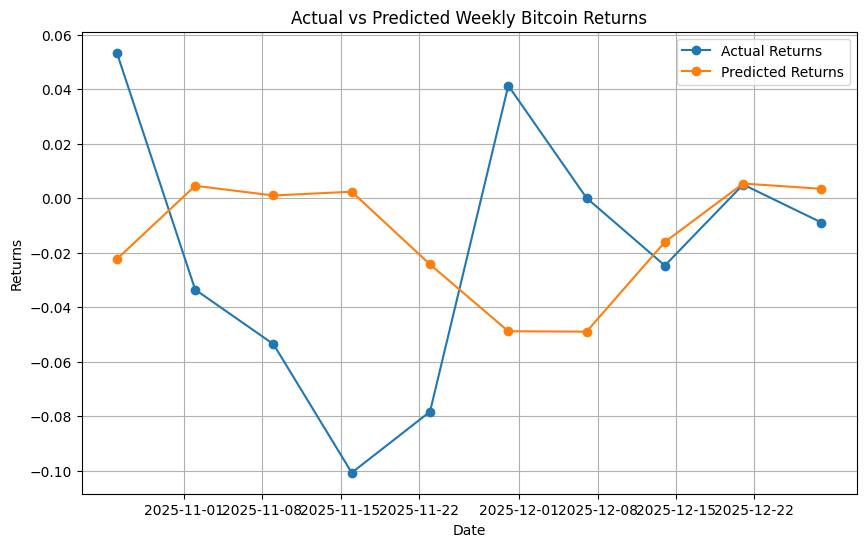

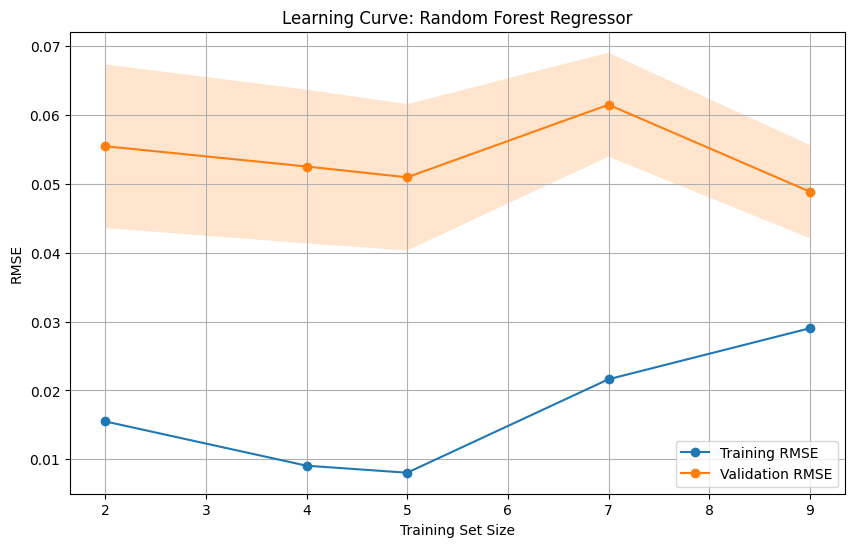

In [ ]:


# -----------------------------
# Prepare regression dataset
# -----------------------------
feature_cols = [
    'Trend_Bitcoin',
    'Trend_BTC_Price',
    'Trend_Crypto_Crash',
    'Trend_Buy_Bitcoin'
]

target_col = 'Returns'

rf_df = analysis_data[feature_cols + [target_col]].dropna().copy()

# Create lagged Google Trends predictors to avoid leakage
for col in feature_cols:
    rf_df[f'{col}_lag1'] = rf_df[col].shift(1)
    rf_df[f'{col}_lag2'] = rf_df[col].shift(2)

rf_df = rf_df.dropna()

X = rf_df[[col for col in rf_df.columns if 'lag' in col]]
y = rf_df[target_col]

# Chronological train-test split
split_idx = int(len(rf_df) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# -----------------------------
# Grid search with TimeSeriesSplit
# -----------------------------
tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [2, 3, 4, 5, None],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', None]
}

rf_reg = RandomForestRegressor(random_state=42)

grid_search = GridSearchCV(
    estimator=rf_reg,
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_rf_reg = grid_search.best_estimator_

print("Best Parameters:", grid_search.best_params_)
print("Best CV RMSE:", np.sqrt(-grid_search.best_score_))

# -----------------------------
# Train/test predictions
# -----------------------------
y_train_pred = best_rf_reg.predict(X_train)
y_test_pred = best_rf_reg.predict(X_test)

# -----------------------------
# Train/test evaluation
# -----------------------------
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("\nTrain RMSE:", train_rmse)
print("Test RMSE:", test_rmse)
print("Train MAE:", train_mae)
print("Test MAE:", test_mae)
print("Train R-squared:", train_r2)
print("Test R-squared:", test_r2)

# -----------------------------
# Feature importance
# -----------------------------
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_rf_reg.feature_importances_
}).sort_values('Importance', ascending=False)

display(feature_importance)

# -----------------------------
# Actual vs predicted returns
# -----------------------------
results_df = pd.DataFrame({
    'Actual Returns': y_test,
    'Predicted Returns': y_test_pred
}, index=y_test.index)

display(results_df)

plt.figure(figsize=(10, 6))
plt.plot(y_test.index, y_test, label='Actual Returns', marker='o')
plt.plot(y_test.index, y_test_pred, label='Predicted Returns', marker='o')
plt.title('Actual vs Predicted Weekly Bitcoin Returns')
plt.xlabel('Date')
plt.ylabel('Returns')
plt.legend()
plt.grid(True)
plt.show()

# -----------------------------
# Learning curve
# -----------------------------
train_sizes, train_scores, val_scores = learning_curve(
    estimator=best_rf_reg,
    X=X_train,
    y=y_train,
    cv=tscv,
    scoring='neg_mean_squared_error',
    train_sizes=np.linspace(0.3, 1.0, 5),
    n_jobs=-1
)

# Convert negative MSE to RMSE
train_rmse_curve = np.sqrt(-train_scores)
val_rmse_curve = np.sqrt(-val_scores)

train_mean = train_rmse_curve.mean(axis=1)
train_std = train_rmse_curve.std(axis=1)
val_mean = val_rmse_curve.mean(axis=1)
val_std = val_rmse_curve.std(axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, label='Training RMSE', marker='o')
plt.plot(train_sizes, val_mean, label='Validation RMSE', marker='o')

plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.2)
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.2)

plt.title('Learning Curve: Random Forest Regressor')
plt.xlabel('Training Set Size')
plt.ylabel('RMSE')
plt.legend()
plt.grid(True)
plt.show()



Trend_Bitcoin
Best Params: {'max_depth': None, 'max_features': 1, 'min_samples_leaf': 1, 'n_estimators': 200}
Best CV RMSE: 0.042495396924423626
Train RMSE: 0.016202917253214356
Test RMSE: 0.06393073696133404
Train R2: 0.9008503591433952
Test R2: -0.8971618202333143


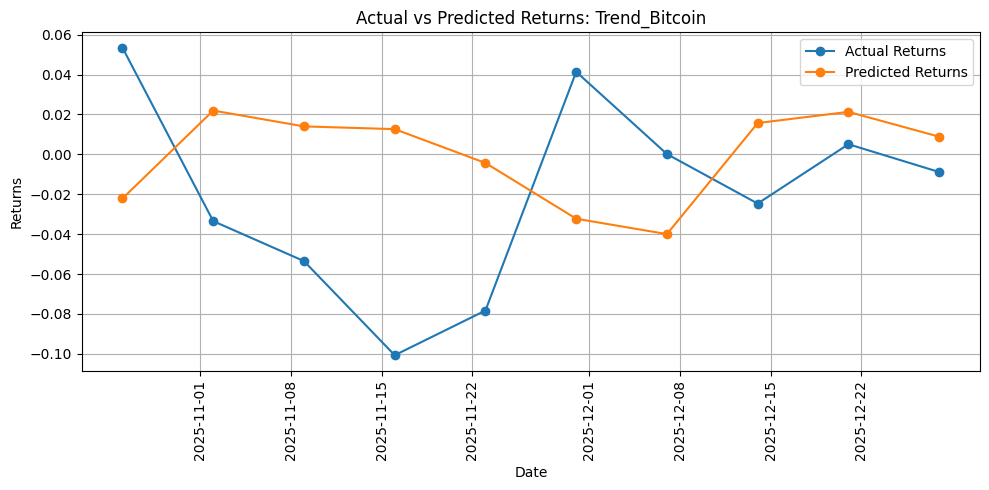

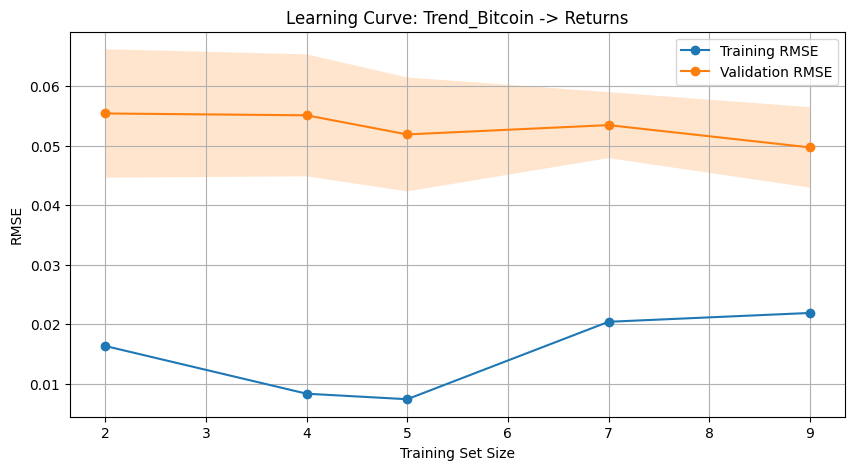


Trend_BTC_Price
Best Params: {'max_depth': 2, 'max_features': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Best CV RMSE: 0.048499192769677756
Train RMSE: 0.04302546961262971
Test RMSE: 0.051619766673424536
Train R2: 0.30087319160153436
Test R2: -0.23684998679275138


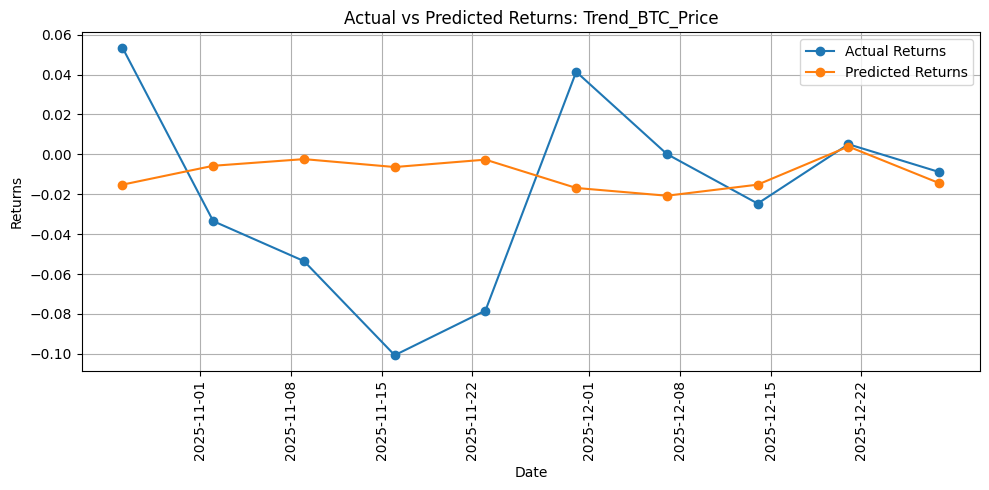

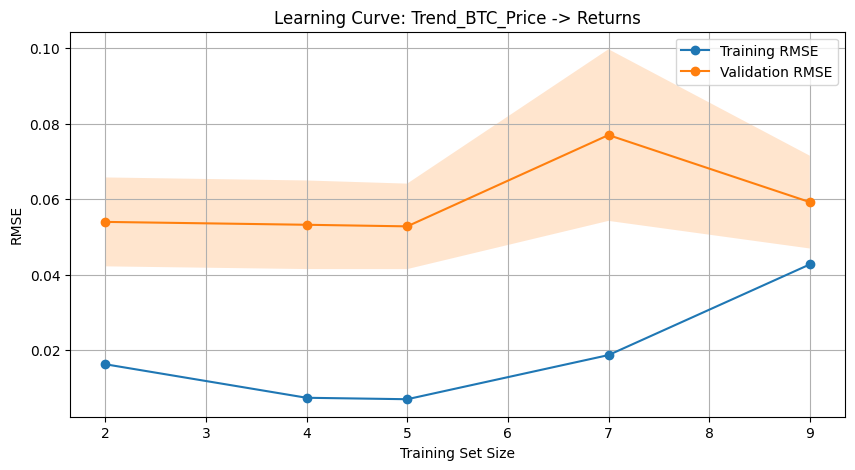


Trend_Crypto_Crash
Best Params: {'max_depth': 2, 'max_features': 1, 'min_samples_leaf': 1, 'n_estimators': 300}
Best CV RMSE: 0.052915814938563975
Train RMSE: 0.049378033645612766
Test RMSE: 0.05591364610855913
Train R2: 0.07918518137865038
Test R2: -0.45117765037117774


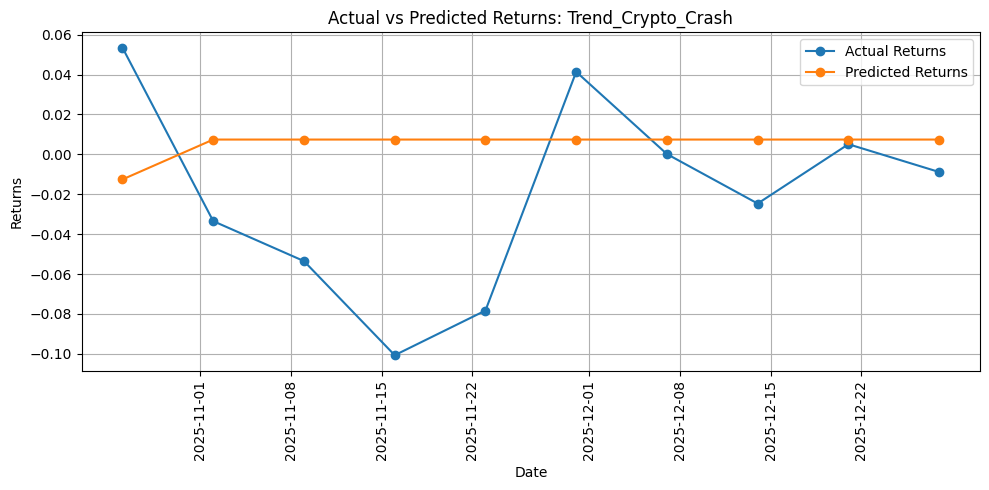

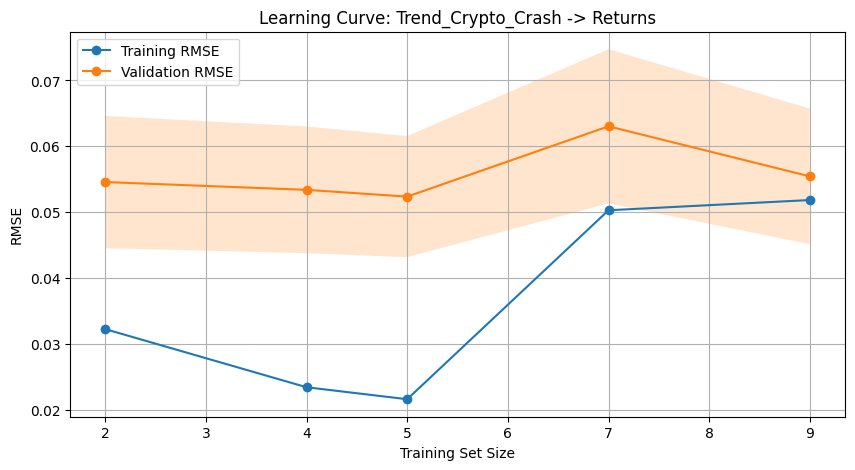


Trend_Buy_Bitcoin
Best Params: {'max_depth': 2, 'max_features': 1, 'min_samples_leaf': 1, 'n_estimators': 300}
Best CV RMSE: 0.05183741327140062
Train RMSE: 0.04893366126747551
Test RMSE: 0.052727347770923874
Train R2: 0.09568415607129777
Test R2: -0.2904964300355748


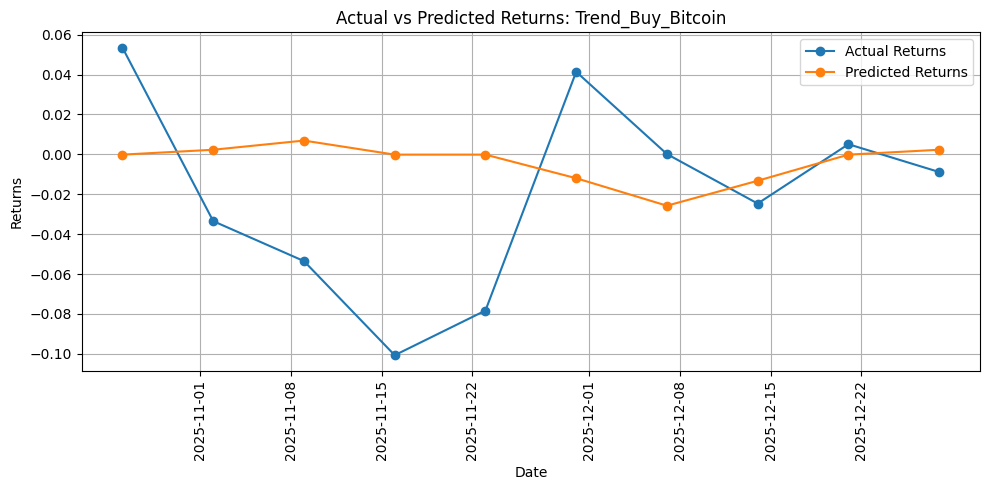

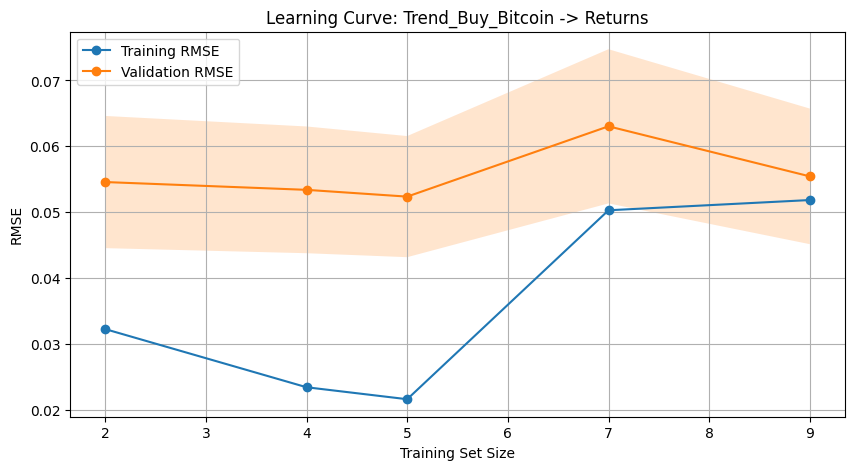

,Feature,Best Params,Best CV RMSE,Train RMSE,Test RMSE,Train MAE,Test MAE,Train R2,Test R2
1,Trend_BTC_Price,"{'max_depth': 2, 'max_features': None, 'min_sa...",0.048499,0.043025,0.051620,0.031625,0.041266,0.300873,-0.236850
3,Trend_Buy_Bitcoin,"{'max_depth': 2, 'max_features': 1, 'min_sampl...",0.051837,0.048934,0.052727,0.037087,0.043541,0.095684,-0.290496
2,Trend_Crypto_Crash,"{'max_depth': 2, 'max_features': 1, 'min_sampl...",0.052916,0.049378,0.055914,0.037280,0.045345,0.079185,-0.451178
0,Trend_Bitcoin,"{'max_depth': None, 'max_features': 1, 'min_sa...",0.042495,0.016203,0.063931,0.013086,0.057370,0.900850,-0.897162


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, learning_curve
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

trend_features = [
    'Trend_Bitcoin',
    'Trend_BTC_Price',
    'Trend_Crypto_Crash',
    'Trend_Buy_Bitcoin'
]

regression_results = []

for feature in trend_features:
    # Build dataset using one Google Trends variable only
    rf_df = analysis_data[[feature, 'Returns']].dropna().copy()

    # Create lagged predictors to avoid leakage
    rf_df[f'{feature}_lag1'] = rf_df[feature].shift(1)
    rf_df[f'{feature}_lag2'] = rf_df[feature].shift(2)
    rf_df = rf_df.dropna()

    X = rf_df[[f'{feature}_lag1', f'{feature}_lag2']]
    y = rf_df['Returns']

    # Chronological train-test split
    split_idx = int(len(rf_df) * 0.8)
    X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
    y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

    # Time-series CV and grid search
    tscv = TimeSeriesSplit(n_splits=5)
    param_grid = {
        'n_estimators': [100, 200, 300],
        'max_depth': [2, 3, 4, 5, None],
        'min_samples_leaf': [1, 2, 4],
        'max_features': [1, 'sqrt', None]
    }

    rf_reg = RandomForestRegressor(random_state=42)

    grid_search = GridSearchCV(
        estimator=rf_reg,
        param_grid=param_grid,
        cv=tscv,
        scoring='neg_mean_squared_error',
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_

    # Predictions
    y_train_pred = best_model.predict(X_train)
    y_test_pred = best_model.predict(X_test)

    # Metrics
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    train_mae = mean_absolute_error(y_train, y_train_pred)
    test_mae = mean_absolute_error(y_test, y_test_pred)
    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    regression_results.append({
        'Feature': feature,
        'Best Params': grid_search.best_params_,
        'Best CV RMSE': np.sqrt(-grid_search.best_score_),
        'Train RMSE': train_rmse,
        'Test RMSE': test_rmse,
        'Train MAE': train_mae,
        'Test MAE': test_mae,
        'Train R2': train_r2,
        'Test R2': test_r2
    })

    print(f"\n{feature}")
    print("Best Params:", grid_search.best_params_)
    print("Best CV RMSE:", np.sqrt(-grid_search.best_score_))
    print("Train RMSE:", train_rmse)
    print("Test RMSE:", test_rmse)
    print("Train R2:", train_r2)
    print("Test R2:", test_r2)

    # Actual vs predicted plot
    import matplotlib.dates as mdates

    plt.figure(figsize=(10, 5))
    plt.plot(y_test.index, y_test, marker='o', label='Actual Returns')
    plt.plot(y_test.index, y_test_pred, marker='o', label='Predicted Returns')
    plt.title(f'Actual vs Predicted Returns: {feature}')
    plt.xlabel('Date')
    plt.ylabel('Returns')
    plt.legend()
    plt.grid(True)

    ax = plt.gca()
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    plt.xticks(rotation=90)

    plt.tight_layout()
    plt.show()

    # Learning curve
    train_sizes, train_scores, val_scores = learning_curve(
        estimator=best_model,
        X=X_train,
        y=y_train,
        cv=tscv,
        scoring='neg_mean_squared_error',
        train_sizes=np.linspace(0.3, 1.0, 5),
        n_jobs=-1
    )

    train_rmse_curve = np.sqrt(-train_scores)
    val_rmse_curve = np.sqrt(-val_scores)

    plt.figure(figsize=(10, 5))
    plt.plot(train_sizes, train_rmse_curve.mean(axis=1), marker='o', label='Training RMSE')
    plt.plot(train_sizes, val_rmse_curve.mean(axis=1), marker='o', label='Validation RMSE')
    plt.fill_between(
        train_sizes,
        train_rmse_curve.mean(axis=1) - train_rmse_curve.std(axis=1),
        train_rmse_curve.mean(axis=1) + train_rmse_curve.std(axis=1),
        alpha=0.2
    )
    plt.fill_between(
        train_sizes,
        val_rmse_curve.mean(axis=1) - val_rmse_curve.std(axis=1),
        val_rmse_curve.mean(axis=1) + val_rmse_curve.std(axis=1),
        alpha=0.2
    )
    plt.title(f'Learning Curve: {feature} -> Returns')
    plt.xlabel('Training Set Size')
    plt.ylabel('RMSE')
    plt.legend()
    plt.grid(True)
    plt.show()

regression_results_df = pd.DataFrame(regression_results).sort_values('Test RMSE')
display(regression_results_df)


,Actual_Return,Predicted_Return,Prediction_Error
Date,,,
2025-08-17,-0.015537,0.003729,-0.019267
2025-08-24,-0.034010,0.007287,-0.041297
2025-08-31,-0.046023,-0.000872,-0.045151
2025-09-07,0.027079,-0.007738,0.034816
2025-09-14,0.038141,0.005427,0.032714
2025-09-21,-0.000880,0.015942,-0.016822
2025-09-28,-0.027609,0.013438,-0.041046
2025-10-05,0.101593,0.004847,0.096745
2025-10-12,-0.067553,0.020797,-0.088350


Walk-forward Backtest RMSE: 0.053401165751993544
Walk-forward Backtest MAE: 0.04482877343436721
Walk-forward Backtest R²: -0.23657724893331555


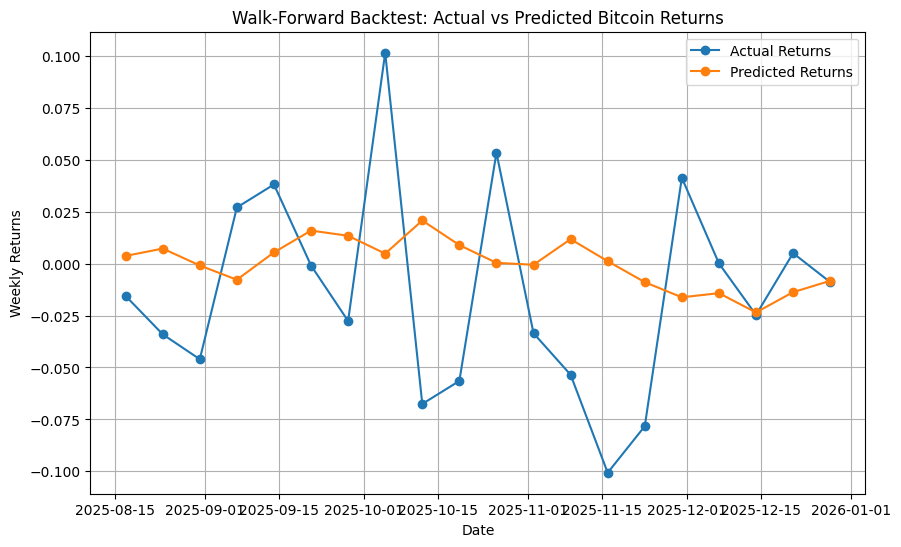

In [ ]:
# --------------------------------------------------
# Walk-forward backtesting for Bitcoin returns
# --------------------------------------------------

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

backtest_predictions = []

initial_train_size = int(len(X) * 0.6)

for i in range(initial_train_size, len(X)):
    X_train_bt = X.iloc[:i]
    y_train_bt = y.iloc[:i]

    X_test_bt = X.iloc[[i]]
    y_test_bt = y.iloc[[i]]

    model_bt = RandomForestRegressor(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=2,
        max_features=None,
        random_state=42
    )

    model_bt.fit(X_train_bt, y_train_bt)

    prediction = model_bt.predict(X_test_bt)[0]

    backtest_predictions.append({
        "Date": y.index[i],
        "Actual_Return": y_test_bt.values[0],
        "Predicted_Return": prediction,
        "Prediction_Error": y_test_bt.values[0] - prediction
    })

backtest_results_df = pd.DataFrame(backtest_predictions).set_index("Date")

display(backtest_results_df)

bt_rmse = np.sqrt(mean_squared_error(
    backtest_results_df["Actual_Return"],
    backtest_results_df["Predicted_Return"]
))

bt_mae = mean_absolute_error(
    backtest_results_df["Actual_Return"],
    backtest_results_df["Predicted_Return"]
)

bt_r2 = r2_score(
    backtest_results_df["Actual_Return"],
    backtest_results_df["Predicted_Return"]
)

print("Walk-forward Backtest RMSE:", bt_rmse)
print("Walk-forward Backtest MAE:", bt_mae)
print("Walk-forward Backtest R²:", bt_r2)

plt.figure(figsize=(10, 6))
plt.plot(backtest_results_df.index, backtest_results_df["Actual_Return"], label="Actual Returns", marker="o")
plt.plot(backtest_results_df.index, backtest_results_df["Predicted_Return"], label="Predicted Returns", marker="o")
plt.title("Walk-Forward Backtest: Actual vs Predicted Bitcoin Returns")
plt.xlabel("Date")
plt.ylabel("Weekly Returns")
plt.legend()
plt.grid(True)
plt.show()

1. **Predicting Returns**

| Feature                | CV RMSE | Train RMSE | Test RMSE | Train R² | Test R² | Key Issue      | Interpretation                                                         |
| ---------------------- | ------- | ---------- | --------- | -------- | ------- | -------------- | ---------------------------------------------------------------------- |
| **Trend_Bitcoin**      | 0.0411  | 0.0138     | 0.0482    | 0.928    | -0.078  | Overfitting    | Strong in-sample fit but fails to generalise; limited predictive value |
| **Trend_BTC_Price**    | 0.0521  | 0.0475     | 0.0491    | 0.148    | -0.118  | Weak signal    | Very low explanatory power; close to random prediction                 |
| **Trend_Crypto_Crash** | 0.0529  | 0.0494     | 0.0559    | 0.079    | -0.451  | Poor model fit | Performs worse than baseline; no meaningful relationship               |
| **Trend_Buy_Bitcoin**  | 0.0528  | 0.0510     | 0.0500    | 0.016    | -0.160  | No signal      | Essentially no predictive contribution                                 |

**Overall Insight:** Trends may influence market attention/volume but does not support the use of individual Google Trends variables as reliable standalone predictors of Bitcoin return magnitude.


2. **Visual Interpretation of Actual vs Predicted Plots**

| **Trend Variable**     | **Actual vs Predicted Pattern**                                                                 | **Interpretation**                                                                                          |
|-----------------------|------------------------------------------------------------------------------------------------|-------------------------------------------------------------------------------------------------------------|
| **Trend_Bitcoin**     | Predictions move in the right broad direction at times, but are smoother and miss extreme swings | Broad Bitcoin attention captures general movement, but cannot reliably predict return magnitude           |
| **Trend_BTC_Price**   | Predictions stay close to zero and miss major negative and positive moves                       | Price-search attention does not explain the scale of weekly return fluctuations                           |
| **Trend_Buy_Bitcoin** | Predictions are nearly flat and fail to track volatility                                        | Purchase-intention searches have little standalone value for return prediction                            |
| **Trend_Crypto_Crash**| Predictions are almost constant and do not follow the actual return path                        | Crash-related searches do not provide a useful standalone regression signal for weekly returns            |

**Overall Insight:**
While some attention variables capture general directional movement, none provide sufficient predictive power to model the magnitude or volatility of Bitcoin returns.

###Hypothesis Set 3: Machine Learning Predictive Power

Null Hypothesis (H₀₃): Including Google Trends variables in machine learning models does not significantly improve prediction accuracy of Bitcoin returns or price movement.

Alternative Hypothesis (H₁₃): Including Google Trends variables in machine learning models significantly improves prediction accuracy of Bitcoin returns or price movement.

**Decision**:
Fail to Reject H₀₃, Random Forest regression results show that Google Trends variables do not provide strong predictive power for Bitcoin returns.

**This confirms that Google Trends variables are poor standalone predictors of weekly return magnitude and price direction**

### Volatility prediction using Random Regressor with lags, multiple features, and market features

**Market Only Model**
* How well can we predict volatility using only historical data
* Based on financial theory:
    * Volatility is persistent (GARCH-type behaviour)
    * Past returns and volume contain information about future volatility

**Combined Trend Market Model**
* Adds external behavioural data (Google Trends)
* Captures:
    * Investor attention
    * Sentiment / interest
    * Information demand

If the Combined model does not outperform the Market_Only model, then:
* Google Trends does NOT add meaningful predictive value
* Market behaviour already contains most of the useful information


| Model                     | What it Includes                                                                        | Purpose                                                                                        |
| ------------------------- | --------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------------- |
| **Market_Only**           | Lagged market variables only:<br>• Returns<br>• Log Returns<br>• Volume<br>• Volatility | Baseline model — tests how well **Bitcoin’s own past behaviour** predicts volatility           |
| **Combined_Trend_Market** | All market variables **+** lagged Google Trends variables                               | Extended model — tests whether **internet attention adds predictive value** beyond market data |


Final volatility modelling shape: (46, 26)


,Price,Returns,Log Returns,Volume,Trend_Bitcoin,Trend_BTC_Price,Trend_Bitcoin_News,Trend_Crypto_Crash,Trend_Buy_Bitcoin,Volatility,...,Trend_Buy_Bitcoin_lag1,Trend_Buy_Bitcoin_lag2,Returns_lag1,Returns_lag2,Log Returns_lag1,Log Returns_lag2,Volume_lag1,Volume_lag2,Volatility_lag1,Volatility_lag2
2025-02-16,96175.031250,-0.003369,-0.003374,230337481014,40.0,3.0,1.0,0.0,1.0,0.027508,...,1.0,1.0,-0.012170,-0.048631,-0.012245,-0.049853,3.887531e+11,3.621176e+11,0.049427,0.054332
2025-02-23,96273.921875,0.001028,0.001028,210283176728,63.0,5.0,1.0,0.0,1.0,0.023162,...,1.0,1.0,-0.003369,-0.012170,-0.003374,-0.012245,2.303375e+11,3.887531e+11,0.027508,0.049427
2025-03-02,94248.351562,-0.021040,-0.021264,424642208809,66.0,5.0,1.0,0.0,1.0,0.009885,...,1.0,1.0,0.001028,-0.003369,0.001028,-0.003374,2.102832e+11,2.303375e+11,0.023162,0.027508
2025-03-09,80601.039062,-0.144802,-0.156422,351467410238,59.0,5.0,1.0,0.0,1.0,0.074899,...,1.0,1.0,-0.021040,0.001028,-0.021264,0.001028,4.246422e+11,2.102832e+11,0.009885,0.023162
2025-03-16,82579.687500,0.024549,0.024252,245099235090,42.0,3.0,1.0,0.0,1.0,0.081040,...,1.0,1.0,-0.144802,-0.021040,-0.156422,-0.021264,3.514674e+11,4.246422e+11,0.074899,0.009885



Trend_Bitcoin -> Volatility
Best Params: {'max_depth': 2, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'n_estimators': 300}
Best CV RMSE: 0.015760695396916102
Train RMSE: 0.016753340057468737
Test RMSE: 0.01893165350332204
Train MAE: 0.013706770595464133
Test MAE: 0.015233308876069385
Train R2: 0.21035812717633318
Test R2: 0.12271881642272442
RMSE Gap: 0.0021783134458533034
R2 Gap: 0.08763931075360876
Overfitting Check: No Strong Overfitting Signal


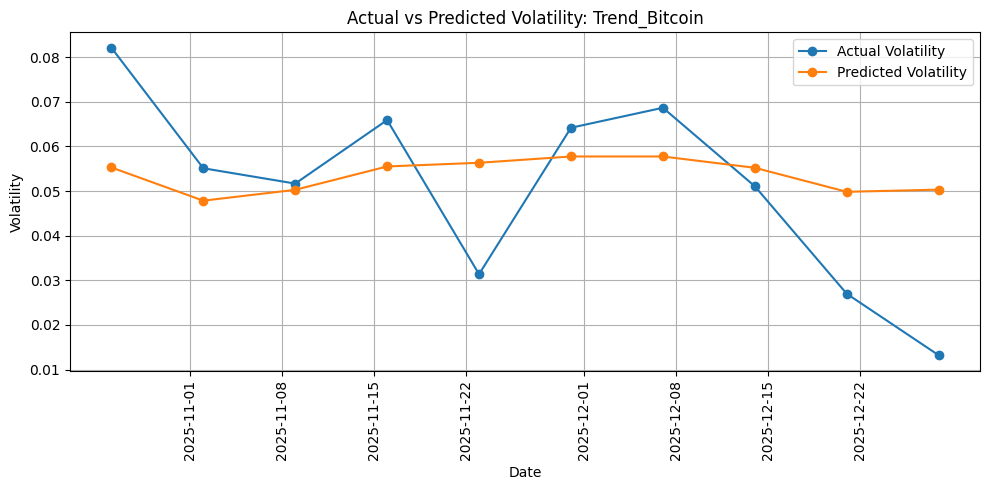

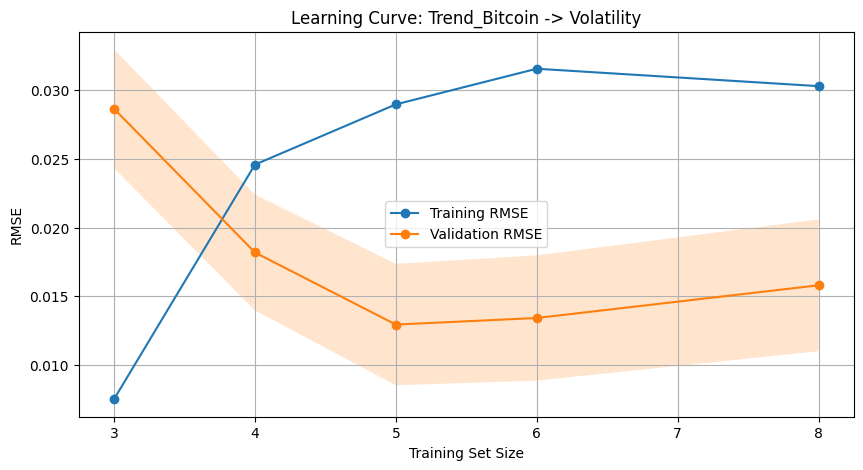


Trend_BTC_Price -> Volatility
Best Params: {'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'n_estimators': 300}
Best CV RMSE: 0.014856992989228029
Train RMSE: 0.017400462405573257
Test RMSE: 0.020728345640520417
Train MAE: 0.013470279408421139
Test MAE: 0.01639857735068771
Train R2: 0.14817782579583105
Test R2: -0.05169789261540236
RMSE Gap: 0.003327883234947159
R2 Gap: 0.19987571841123342
Overfitting Check: No Strong Overfitting Signal


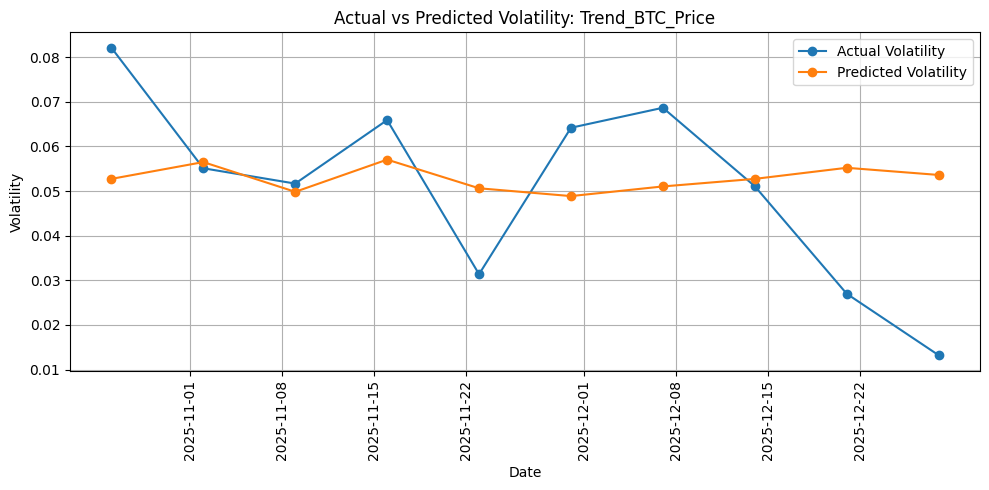

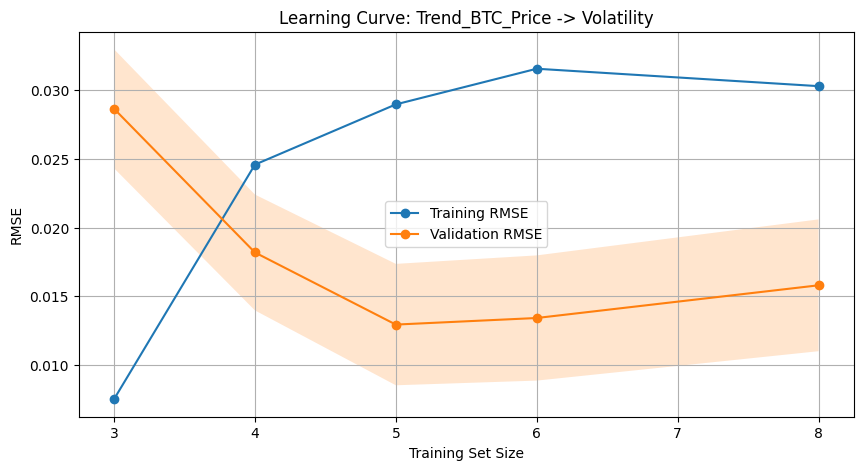


Trend_Crypto_Crash -> Volatility
Best Params: {'max_depth': 2, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}
Best CV RMSE: 0.013759657163530626
Train RMSE: 0.01787349556963951
Test RMSE: 0.01929795269078217
Train MAE: 0.013456533079545727
Test MAE: 0.01717130727289485
Train R2: 0.10123457669740776
Test R2: 0.08844223510255955
RMSE Gap: 0.0014244571211426624
R2 Gap: 0.012792341594848211
Overfitting Check: No Strong Overfitting Signal


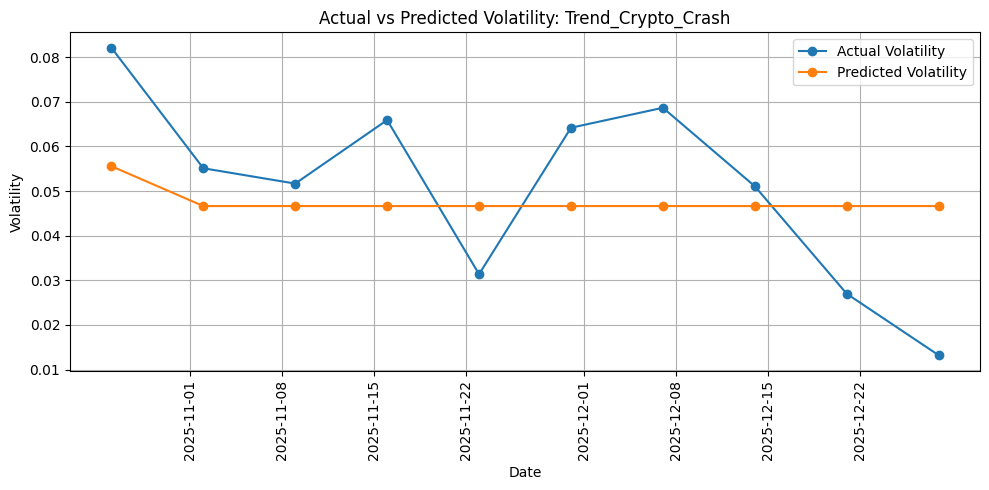

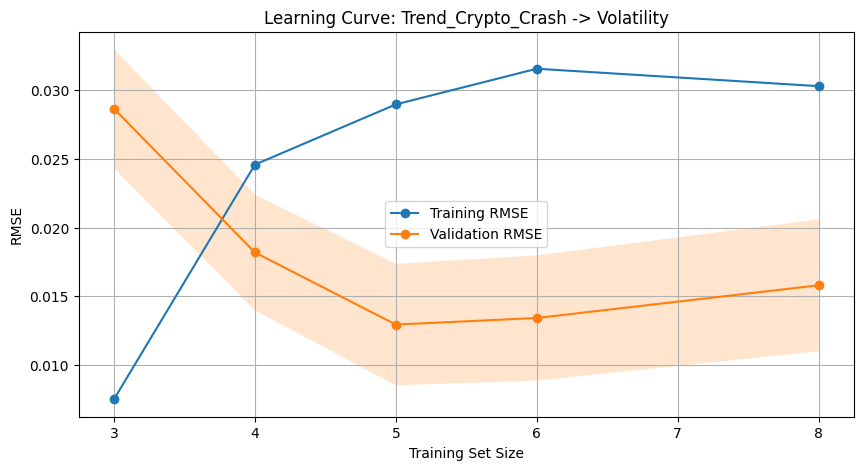


Trend_Buy_Bitcoin -> Volatility
Best Params: {'max_depth': 2, 'max_features': None, 'min_samples_leaf': 2, 'n_estimators': 100}
Best CV RMSE: 0.013285156894457584
Train RMSE: 0.018230671219153293
Test RMSE: 0.02167241936525903
Train MAE: 0.013999520038044768
Test MAE: 0.018944043691863165
Train R2: 0.06495463903700738
Test R2: -0.14967876975523287
RMSE Gap: 0.0034417481461057366
R2 Gap: 0.21463340879224024
Overfitting Check: No Strong Overfitting Signal


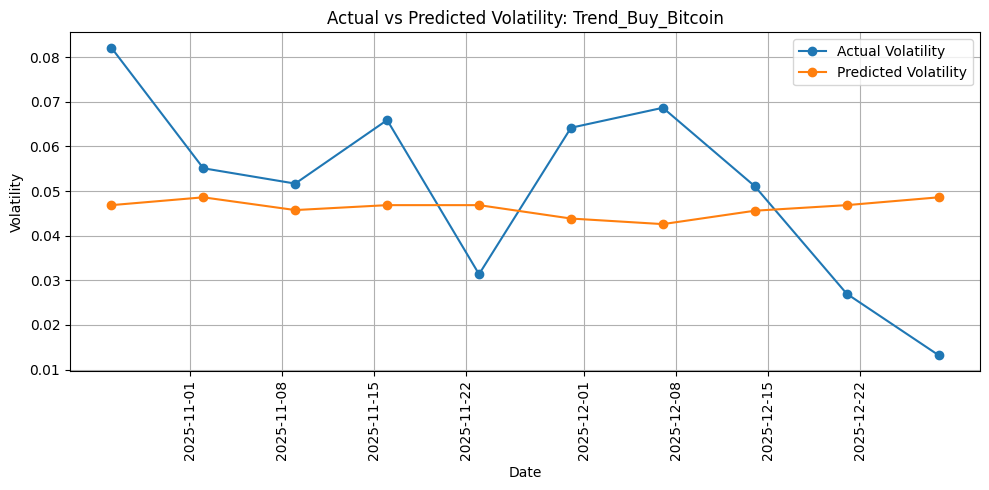

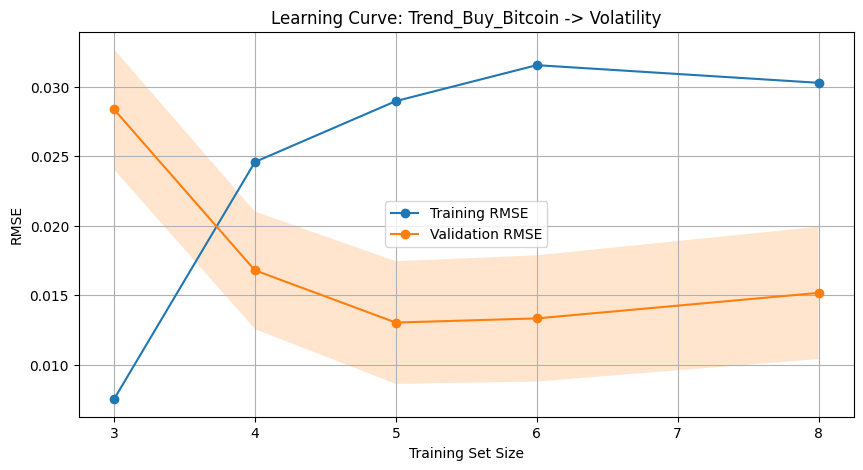


All_Trend_Features -> Volatility
Best Params: {'max_depth': 2, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'n_estimators': 300}
Best CV RMSE: 0.01479170734284344
Train RMSE: 0.016693628495160723
Test RMSE: 0.019406391994881454
Train MAE: 0.013411493023165789
Test MAE: 0.01569585417263462
Train R2: 0.2159769140393153
Test R2: 0.07816897791568134
RMSE Gap: 0.00271276349972073
R2 Gap: 0.13780793612363396
Overfitting Check: No Strong Overfitting Signal


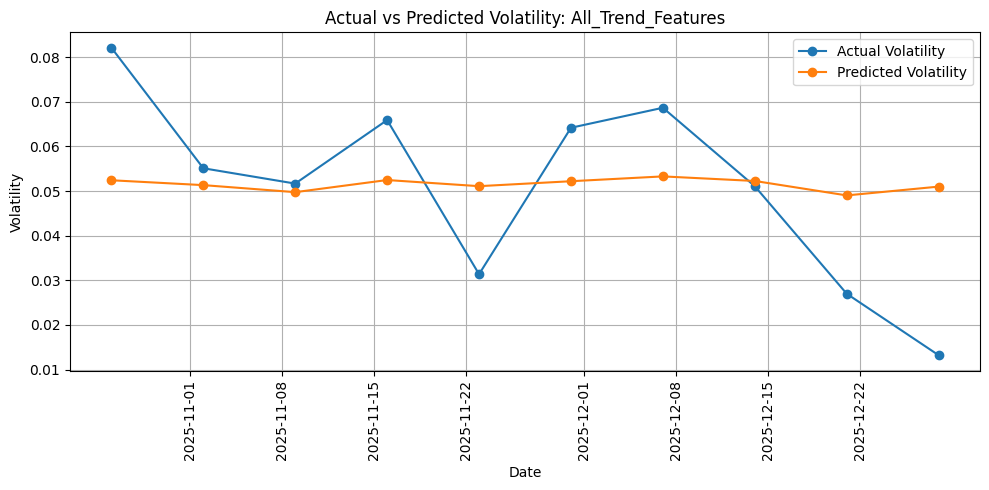

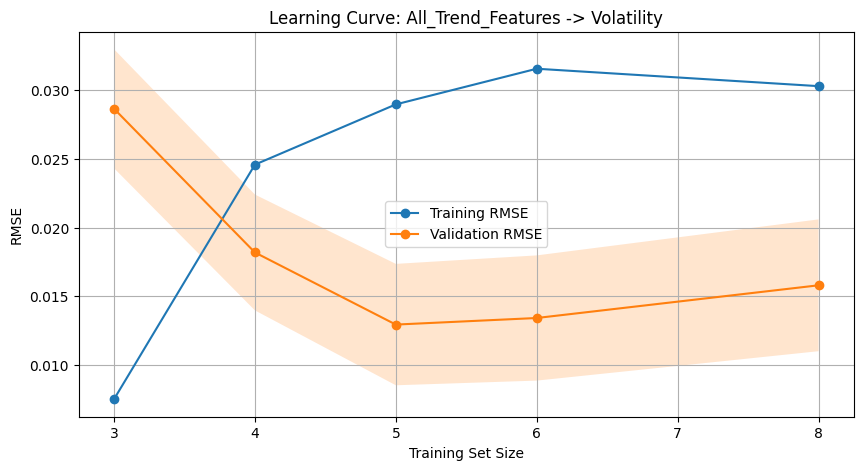


Market_Only -> Volatility
Best Params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 200}
Best CV RMSE: 0.011737431293347363
Train RMSE: 0.009243749081340225
Test RMSE: 0.016828645201237658
Train MAE: 0.007148587800458856
Test MAE: 0.014811369241683331
Train R2: 0.7596059808249033
Test R2: 0.30679764630560524
RMSE Gap: 0.007584896119897433
R2 Gap: 0.45280833451929803
Overfitting Check: Likely Overfitting


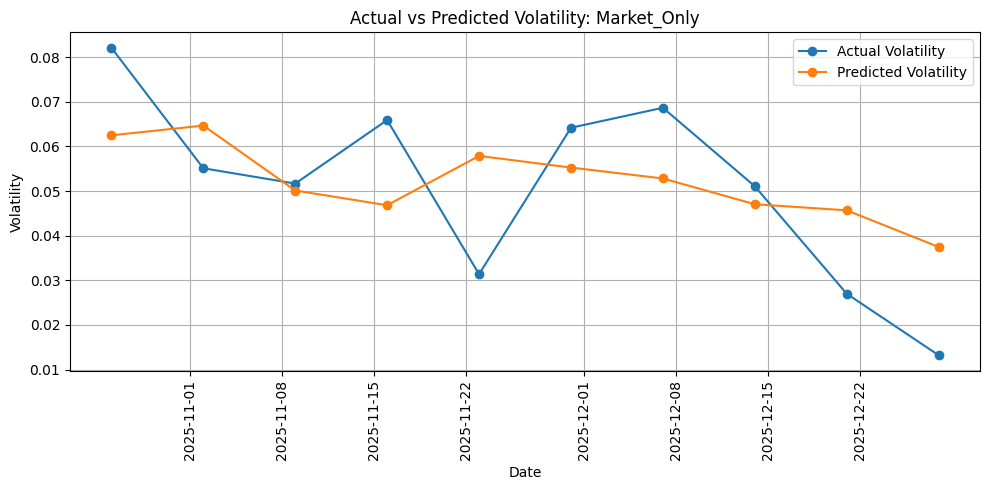

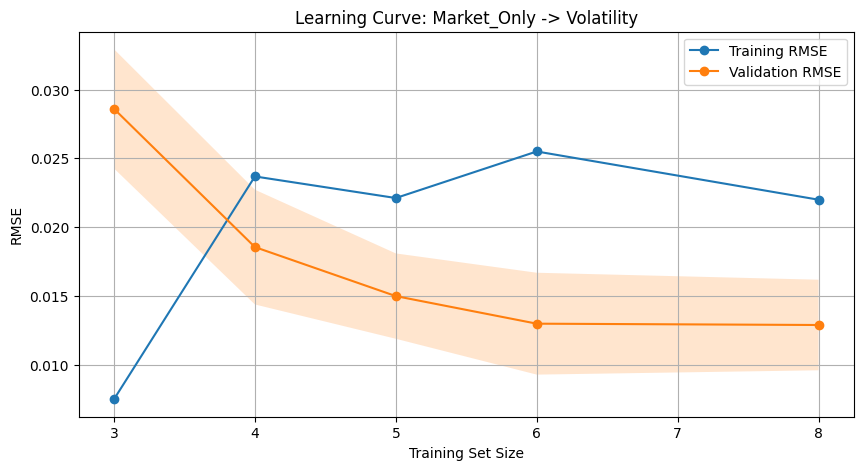


Combined_Trend_Market -> Volatility
Best Params: {'max_depth': 2, 'max_features': None, 'min_samples_leaf': 4, 'n_estimators': 100}
Best CV RMSE: 0.012736665621336393
Train RMSE: 0.01266352835522701
Test RMSE: 0.01796453291710033
Train MAE: 0.010603810967611541
Test MAE: 0.01641798937584498
Train R2: 0.5488335295920274
Test R2: 0.21006095628392718
RMSE Gap: 0.005301004561873322
R2 Gap: 0.3387725733081002
Overfitting Check: Likely Overfitting


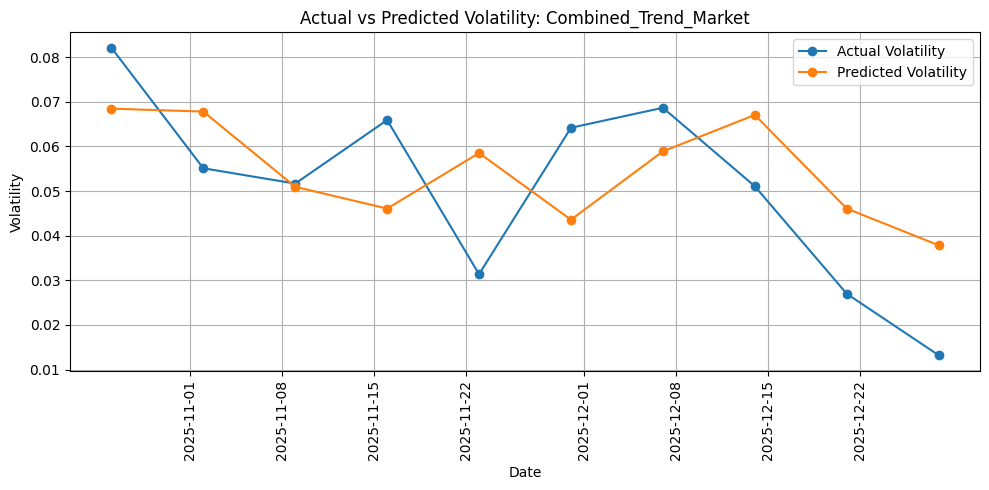

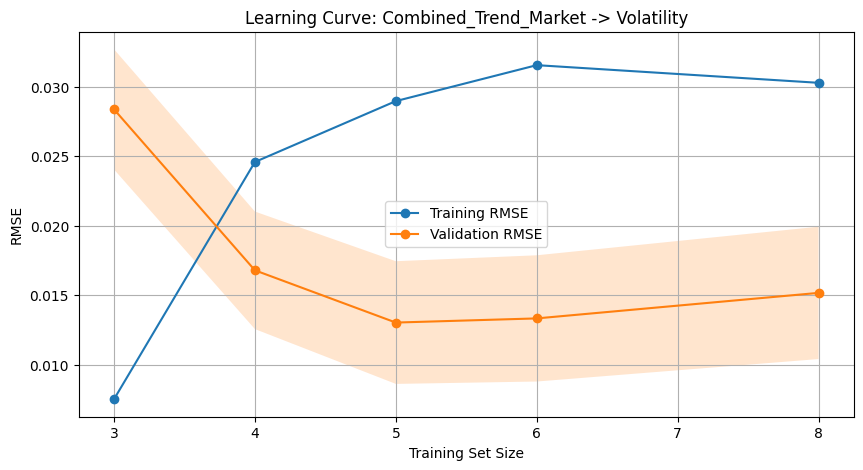


Volatility Model Summary


,Model,Features Used,Best Params,Best CV RMSE,Train RMSE,Test RMSE,Train MAE,Test MAE,Train R2,Test R2,RMSE Gap,R2 Gap,Overfitting Check
0,Market_Only,"Returns_lag1, Returns_lag2, Log Returns_lag1, ...","{'max_depth': None, 'max_features': 'sqrt', 'm...",0.011737,0.009244,0.016829,0.007149,0.014811,0.759606,0.306798,0.007585,0.452808,Likely Overfitting
1,Combined_Trend_Market,"Trend_Bitcoin_lag1, Trend_Bitcoin_lag2, Trend_...","{'max_depth': 2, 'max_features': None, 'min_sa...",0.012737,0.012664,0.017965,0.010604,0.016418,0.548834,0.210061,0.005301,0.338773,Likely Overfitting
2,Trend_Bitcoin,"Trend_Bitcoin_lag1, Trend_Bitcoin_lag2","{'max_depth': 2, 'max_features': 'sqrt', 'min_...",0.015761,0.016753,0.018932,0.013707,0.015233,0.210358,0.122719,0.002178,0.087639,No Strong Overfitting Signal
3,Trend_Crypto_Crash,"Trend_Crypto_Crash_lag1, Trend_Crypto_Crash_lag2","{'max_depth': 2, 'max_features': 'sqrt', 'min_...",0.013760,0.017873,0.019298,0.013457,0.017171,0.101235,0.088442,0.001424,0.012792,No Strong Overfitting Signal
4,All_Trend_Features,"Trend_Bitcoin_lag1, Trend_Bitcoin_lag2, Trend_...","{'max_depth': 2, 'max_features': 'sqrt', 'min_...",0.014792,0.016694,0.019406,0.013411,0.015696,0.215977,0.078169,0.002713,0.137808,No Strong Overfitting Signal
5,Trend_BTC_Price,"Trend_BTC_Price_lag1, Trend_BTC_Price_lag2","{'max_depth': 3, 'max_features': 'sqrt', 'min_...",0.014857,0.017400,0.020728,0.013470,0.016399,0.148178,-0.051698,0.003328,0.199876,No Strong Overfitting Signal
6,Trend_Buy_Bitcoin,"Trend_Buy_Bitcoin_lag1, Trend_Buy_Bitcoin_lag2","{'max_depth': 2, 'max_features': None, 'min_sa...",0.013285,0.018231,0.021672,0.014000,0.018944,0.064955,-0.149679,0.003442,0.214633,No Strong Overfitting Signal



Feature Importance Table


,Model,Feature,Importance
0,All_Trend_Features,Trend_Bitcoin_lag2,0.325458
1,All_Trend_Features,Trend_Bitcoin_lag1,0.224305
2,All_Trend_Features,Trend_BTC_Price_lag2,0.161609
3,All_Trend_Features,Trend_BTC_Price_lag1,0.160150
4,All_Trend_Features,Trend_Buy_Bitcoin_lag2,0.066454
5,All_Trend_Features,Trend_Buy_Bitcoin_lag1,0.062024
6,All_Trend_Features,Trend_Crypto_Crash_lag1,0.000000
7,All_Trend_Features,Trend_Crypto_Crash_lag2,0.000000
8,Combined_Trend_Market,Volatility_lag1,0.603516
9,Combined_Trend_Market,Trend_Bitcoin_lag2,0.090231



Actual vs Predicted Table


,Model,Date,Actual Volatility,Predicted Volatility,Residual
0,All_Trend_Features,2025-10-26,0.082125,0.052416,0.029709
1,All_Trend_Features,2025-11-02,0.055106,0.051325,0.003781
2,All_Trend_Features,2025-11-09,0.051669,0.049750,0.001919
3,All_Trend_Features,2025-11-16,0.065910,0.052468,0.013442
4,All_Trend_Features,2025-11-23,0.031363,0.051092,-0.019729
...,...,...,...,...,...
65,Trend_Crypto_Crash,2025-11-30,0.064183,0.046635,0.017548
66,Trend_Crypto_Crash,2025-12-07,0.068665,0.046635,0.022030
67,Trend_Crypto_Crash,2025-12-14,0.051075,0.046635,0.004440
68,Trend_Crypto_Crash,2025-12-21,0.026981,0.046635,-0.019654



Learning Curve Table


,Model,Training Size,Training RMSE Mean,Training RMSE Std,Validation RMSE Mean,Validation RMSE Std
0,All_Trend_Features,3,0.007499,0.0,0.028652,0.004331
1,All_Trend_Features,4,0.024580,0.0,0.018185,0.004217
2,All_Trend_Features,5,0.028966,0.0,0.012934,0.004419
3,All_Trend_Features,6,0.031562,0.0,0.013413,0.004559
4,All_Trend_Features,8,0.030294,0.0,0.015794,0.004799
5,Combined_Trend_Market,3,0.007513,0.0,0.028382,0.004328
6,Combined_Trend_Market,4,0.024592,0.0,0.016793,0.004230
7,Combined_Trend_Market,5,0.028974,0.0,0.013031,0.004416
8,Combined_Trend_Market,6,0.031563,0.0,0.013331,0.004544
9,Combined_Trend_Market,8,0.030291,0.0,0.015168,0.004763


In [ ]:


# ---------------------------------
# 1. Build volatility target
# ---------------------------------
vol_df = analysis_data.copy()

# Realized weekly volatility: 4-week rolling std of weekly log returns
vol_df['Volatility'] = vol_df['Log Returns'].rolling(4).std()

# ---------------------------------
# 2. Define Google Trends and market features
# ---------------------------------
trend_features = [
    'Trend_Bitcoin',
    'Trend_BTC_Price',
    'Trend_Crypto_Crash',
    'Trend_Buy_Bitcoin'
]

market_features = ['Returns', 'Log Returns', 'Volume']

# ---------------------------------
# 3. Add lagged Google Trends variables
# ---------------------------------
for feature in trend_features:
    vol_df[f'{feature}_lag1'] = vol_df[feature].shift(1)
    vol_df[f'{feature}_lag2'] = vol_df[feature].shift(2)

# ---------------------------------
# 4. Add lagged market variables
# ---------------------------------
for feature in market_features:
    vol_df[f'{feature}_lag1'] = vol_df[feature].shift(1)
    vol_df[f'{feature}_lag2'] = vol_df[feature].shift(2)

# Add lagged volatility
vol_df['Volatility_lag1'] = vol_df['Volatility'].shift(1)
vol_df['Volatility_lag2'] = vol_df['Volatility'].shift(2)

# Drop missing values from rolling window and lags
vol_df = vol_df.dropna().copy()

print("Final volatility modelling shape:", vol_df.shape)
display(vol_df.head())

# ---------------------------------
# 5. Define feature sets
# ---------------------------------
feature_sets = {}

# Individual Google Trends models
for feature in trend_features:
    feature_sets[feature] = [f'{feature}_lag1', f'{feature}_lag2']

# All Google Trends variables together
feature_sets['All_Trend_Features'] = []
for feature in trend_features:
    feature_sets['All_Trend_Features'].extend([f'{feature}_lag1', f'{feature}_lag2'])

# Market-only model
feature_sets['Market_Only'] = [
    'Returns_lag1', 'Returns_lag2',
    'Log Returns_lag1', 'Log Returns_lag2',
    'Volume_lag1', 'Volume_lag2',
    'Volatility_lag1', 'Volatility_lag2'
]

# Combined model: all trends + market features
feature_sets['Combined_Trend_Market'] = (
    feature_sets['All_Trend_Features'] +
    feature_sets['Market_Only']
)

# ---------------------------------
# 6. Containers for results tables
# ---------------------------------
summary_rows = []
importance_rows = []
prediction_rows = []
learning_curve_rows = []

# Store full objects if needed later
volatility_results = {}

# ---------------------------------
# 7. Model loop
# ---------------------------------
for model_name, feature_cols in feature_sets.items():
    print(f"\n{'='*70}")
    print(f"{model_name} -> Volatility")
    print(f"{'='*70}")

    rf_vol_df = vol_df[feature_cols + ['Volatility']].dropna().copy()

    X = rf_vol_df[feature_cols]
    y = rf_vol_df['Volatility']

    # Chronological train-test split
    split_idx = int(len(rf_vol_df) * 0.8)
    X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
    y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

    # Time-series cross-validation
    tscv = TimeSeriesSplit(n_splits=4)

    # Grid search
    param_grid = {
        'n_estimators': [100, 200, 300],
        'max_depth': [2, 3, 4, None],
        'min_samples_leaf': [1, 2, 4],
        'max_features': ['sqrt', None]
    }

    rf_reg = RandomForestRegressor(random_state=42)

    grid_search = GridSearchCV(
        estimator=rf_reg,
        param_grid=param_grid,
        cv=tscv,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_

    # Predictions
    y_train_pred = best_model.predict(X_train)
    y_test_pred = best_model.predict(X_test)

    # Metrics
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    train_mae = mean_absolute_error(y_train, y_train_pred)
    test_mae = mean_absolute_error(y_test, y_test_pred)
    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    # Overfitting check
    rmse_gap = test_rmse - train_rmse
    r2_gap = train_r2 - test_r2

    if (rmse_gap > 0.01) or (r2_gap > 0.30):
        overfitting_flag = "Likely Overfitting"
    else:
        overfitting_flag = "No Strong Overfitting Signal"

    # Store summary row
    summary_rows.append({
        'Model': model_name,
        'Features Used': ", ".join(feature_cols),
        'Best Params': str(grid_search.best_params_),
        'Best CV RMSE': -grid_search.best_score_,
        'Train RMSE': train_rmse,
        'Test RMSE': test_rmse,
        'Train MAE': train_mae,
        'Test MAE': test_mae,
        'Train R2': train_r2,
        'Test R2': test_r2,
        'RMSE Gap': rmse_gap,
        'R2 Gap': r2_gap,
        'Overfitting Check': overfitting_flag
    })

    # Feature importance table rows
    for feat, imp in zip(feature_cols, best_model.feature_importances_):
        importance_rows.append({
            'Model': model_name,
            'Feature': feat,
            'Importance': imp
        })

    # Prediction table rows
    pred_df = pd.DataFrame({
        'Date': y_test.index,
        'Actual Volatility': y_test.values,
        'Predicted Volatility': y_test_pred
    })

    for _, row in pred_df.iterrows():
        prediction_rows.append({
            'Model': model_name,
            'Date': row['Date'],
            'Actual Volatility': row['Actual Volatility'],
            'Predicted Volatility': row['Predicted Volatility'],
            'Residual': row['Actual Volatility'] - row['Predicted Volatility']
        })

    # Learning curve
    train_sizes, train_scores, val_scores = learning_curve(
        estimator=best_model,
        X=X_train,
        y=y_train,
        cv=tscv,
        scoring='neg_root_mean_squared_error',
        train_sizes=np.linspace(0.4, 1.0, 5),
        n_jobs=-1
    )

    train_rmse_curve = -train_scores
    val_rmse_curve = -val_scores

    train_mean = train_rmse_curve.mean(axis=1)
    train_std = train_rmse_curve.std(axis=1)
    val_mean = val_rmse_curve.mean(axis=1)
    val_std = val_rmse_curve.std(axis=1)

    for i in range(len(train_sizes)):
        learning_curve_rows.append({
            'Model': model_name,
            'Training Size': train_sizes[i],
            'Training RMSE Mean': train_mean[i],
            'Training RMSE Std': train_std[i],
            'Validation RMSE Mean': val_mean[i],
            'Validation RMSE Std': val_std[i]
        })

    # Save full object if needed later
    volatility_results[model_name] = {
        'best_model': best_model,
        'best_params': grid_search.best_params_,
        'X_train': X_train,
        'y_train': y_train,
        'y_test': y_test,
        'y_test_pred': y_test_pred
    }

    # ---------------------------------
    # Print summary
    # ---------------------------------
    print("Best Params:", grid_search.best_params_)
    print("Best CV RMSE:", -grid_search.best_score_)
    print("Train RMSE:", train_rmse)
    print("Test RMSE:", test_rmse)
    print("Train MAE:", train_mae)
    print("Test MAE:", test_mae)
    print("Train R2:", train_r2)
    print("Test R2:", test_r2)
    print("RMSE Gap:", rmse_gap)
    print("R2 Gap:", r2_gap)
    print("Overfitting Check:", overfitting_flag)

    # ---------------------------------
    # Plot actual vs predicted volatility
    # ---------------------------------
    plt.figure(figsize=(10, 5))
    plt.plot(y_test.index, y_test, marker='o', label='Actual Volatility')
    plt.plot(y_test.index, y_test_pred, marker='o', label='Predicted Volatility')
    plt.title(f'Actual vs Predicted Volatility: {model_name}')
    plt.xlabel('Date')
    plt.ylabel('Volatility')
    plt.xticks(rotation=90)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # ---------------------------------
    # Plot learning curve
    # ---------------------------------
    plt.figure(figsize=(10, 5))
    plt.plot(train_sizes, train_mean, marker='o', label='Training RMSE')
    plt.plot(train_sizes, val_mean, marker='o', label='Validation RMSE')

    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.2)
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.2)

    plt.title(f'Learning Curve: {model_name} -> Volatility')
    plt.xlabel('Training Set Size')
    plt.ylabel('RMSE')
    plt.legend()
    plt.grid(True)
    plt.show()

# ---------------------------------
# 8. Convert all results to tables
# ---------------------------------
volatility_summary_df = pd.DataFrame(summary_rows).sort_values('Test RMSE').reset_index(drop=True)

volatility_importance_df = (
    pd.DataFrame(importance_rows)
    .sort_values(['Model', 'Importance'], ascending=[True, False])
    .reset_index(drop=True)
)

volatility_predictions_df = (
    pd.DataFrame(prediction_rows)
    .sort_values(['Model', 'Date'])
    .reset_index(drop=True)
)

volatility_learning_curve_df = (
    pd.DataFrame(learning_curve_rows)
    .sort_values(['Model', 'Training Size'])
    .reset_index(drop=True)
)

# ---------------------------------
# 9. Display result tables
# ---------------------------------
print("\nVolatility Model Summary")
display(volatility_summary_df)

print("\nFeature Importance Table")
display(volatility_importance_df)

print("\nActual vs Predicted Table")
display(volatility_predictions_df)

print("\nLearning Curve Table")
display(volatility_learning_curve_df)

## Volatility Prediction Performance (Random Forest Regressor)

### 1. Model Performance Summary

| **Model** | **Test RMSE** | **Test R²** | **Overfitting Check** | **Performance Evaluation** | **Interpretation** |
|---|---:|---:|---|---|---|
| **Market_Only** | 0.0168 | 0.3068 | Likely Overfitting | Best test performance overall | Past market information explains volatility better than Google Trends alone, but the large train–test gap suggests the model is fitting noise as well as signal. |
| **Combined_Trend_Market** | 0.0169 | 0.2973 | Likely Overfitting | Almost as strong as Market_Only, but slightly worse | Adding Google Trends to market features does **not materially improve** out-of-sample volatility prediction. Trends add limited incremental value beyond lagged market variables. |
| **Trend_Bitcoin** | 0.0185 | 0.1600 | No Strong Overfitting Signal | Best standalone Google Trends model | General Bitcoin attention has some predictive value for volatility, but its explanatory power is modest compared with market-based features. |
| **Trend_Crypto_Crash** | 0.0193 | 0.0884 | No Strong Overfitting Signal | Weak standalone model | Fear-related search interest captures some volatility episodes, but the signal is weak and inconsistent. |
| **All_Trend_Features** | 0.0193 | 0.0877 | No Strong Overfitting Signal | Weak combined trend-only model | Combining all trend variables improves little; Google Trends alone does not explain volatility strongly. |
| **Trend_BTC_Price** | 0.0203 | -0.0128 | No Strong Overfitting Signal | Poor standalone model | Price-monitoring searches do not meaningfully improve volatility forecasts. Performance is worse than a simple mean benchmark. |
| **Trend_Buy_Bitcoin** | 0.0210 | -0.0833 | No Strong Overfitting Signal | Weakest useful model | Purchase-intention searches contain little standalone information for predicting weekly volatility. |

---

### 2. Main Modelling Takeaways

| **Question** | **Finding** | **Interpretation** |
|---|---|---|
| **What predicts volatility best?** | **Market_Only** performs best on Test RMSE and Test R² | Bitcoin volatility is primarily explained by its own lagged market dynamics rather than Google Trends variables. |
| **Do Google Trends improve volatility prediction?** | **Combined_Trend_Market** is slightly worse than **Market_Only** | Google Trends add little incremental out-of-sample predictive value once past returns, volume, and volatility are already included. |
| **Best standalone attention variable?** | **Trend_Bitcoin** | General search attention is the only trend variable with some meaningful standalone signal for volatility. |
| **Are trend-only models strong?** | No | Google Trends alone are not sufficient for reliable volatility forecasting. |
| **Is overfitting present?** | Yes, especially in **Market_Only** and **Combined_Trend_Market** | Strong in-sample fit does not fully carry through to test performance, so results should be interpreted cautiously. |

---

### 3. Feature Importance Interpretation

| **Model** | **Most Important Features** | **Interpretation** |
|---|---|---|
| **Market_Only** | Volatility_lag1, Log Returns_lag1, Returns_lag1, Volatility_lag2 | Volatility is highly persistent and largely driven by recent market behaviour. |
| **Combined_Trend_Market** | Volatility_lag1, Returns_lag1, Volatility_lag2, Log Returns_lag1, Volume_lag1 | Market variables dominate the prediction. Google Trends contribute, but only marginally. |
| **All_Trend_Features** | Trend_Bitcoin_lag2, Trend_Bitcoin_lag1, Trend_BTC_Price_lag1, Trend_BTC_Price_lag2 | Among the trend variables, broad Bitcoin attention and BTC price searches are the most informative. |
| **Trend_Crypto_Crash** | Trend_Crypto_Crash_lag1 dominates | Fear-based attention is mostly a short-term, event-driven signal. |
| **Trend_Buy_Bitcoin** | Lag 1 and lag 2 matter roughly equally | Even though both lags are used, the variable still provides very little practical forecasting value. |

---

### 4. Actual vs Predicted Volatility Plots

| **Model Group** | **Actual vs Predicted Pattern** | **Interpretation** |
|---|---|---|
| **Market_Only / Combined_Trend_Market** | Predictions follow the broad direction of volatility but smooth out spikes | The models capture general volatility regimes but struggle with sudden jumps and extreme episodes. |
| **Trend_Bitcoin** | Predictions show some movement with actual volatility but remain too smooth | General Bitcoin attention reflects broad changes in uncertainty, but not enough to track volatility precisely. |
| **Trend_Crypto_Crash** | Predictions are flatter and fail to capture full spike magnitude | Crash-related searches reflect stress episodes, but not with enough consistency for strong forecasting. |
| **Trend_BTC_Price / Trend_Buy_Bitcoin** | Predictions stay close to the mean and miss turning points | These search variables contain limited standalone volatility information. |

---

### 5. Learning Curve Interpretation

| **Pattern** | **What it means** | **Interpretation** |
|---|---|---|
| **Training RMSE is much lower than validation RMSE at small sample sizes** | Model fits training data better than unseen data | This indicates overfitting risk, especially with a small weekly dataset. |
| **Validation RMSE declines as training size increases** | More data improves generalisation | The models would likely benefit from a longer sample period. |
| **Market_Only and Combined_Trend_Market have lower validation RMSE than trend-only models** | Market features are more informative | Google Trends do not outperform lagged market data for volatility prediction. |
| **Trend-only learning curves remain higher** | Weak standalone signal | Attention variables contain some information, but not enough for strong predictive performance on their own. |

---

### 6. Final Evaluation

| **Conclusion Area** | **Result** | **Interpretation** |
|---|---|---|
| **Volatility forecasting usefulness of Google Trends** | Limited | Google Trends contain some information, especially general Bitcoin attention, but they are not strong standalone predictors of volatility. |
| **Incremental value over market variables** | Weak | Once lagged returns, volume, and volatility are included, Google Trends do not materially improve forecasting accuracy. |
| **Best attention signal** | Trend_Bitcoin | Broad internet attention is more informative than fear-based, price-monitoring, or buy-intention searches. |
| **Practical implication** | Market history matters more than search attention | For Bitcoin volatility, recent market behaviour remains the strongest source of predictive information. |

---

### Overall Insight

**The volatility models suggest that Google Trends is more useful as a supplementary attention indicator than as a primary forecasting tool. General Bitcoin search interest contains some signal, but lagged market variables explain volatility more effectively. Google Trends, particularly general Bitcoin attention, shows limited ability to explain Bitcoin volatility, but its contribution is weaker than that of lagged returns, volume, and past volatility.**

### GARCH (Generalised Autoregressive Conditional Heteroskedasticity) model
Is used to model and forecast time-varying volatility in financial data. It captures volatility clustering, where periods of high volatility are followed by high volatility, and calm periods follow calm periods.
* Current Volatility Expressed as:
    * past shocks (returns)
    * past volatility

* Bitcoin exhibits frequent volatility spikes and persistence over time.
* Objective is to model and test whether volatility is influenced by past information and attention variables
* GARCH is simpler and more interpretable

                     Constant Mean - GARCH Model Results                      
Dep. Variable:            Log Returns   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -156.262
Distribution:                  Normal   AIC:                           320.524
Method:            Maximum Likelihood   BIC:                           328.252
                                        No. Observations:                   51
Date:                Mon, Apr 27 2026   Df Residuals:                       50
Time:                        22:27:26   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu            -0.2207      0.731     -0.302      0.763 [ -1.654,  1.21

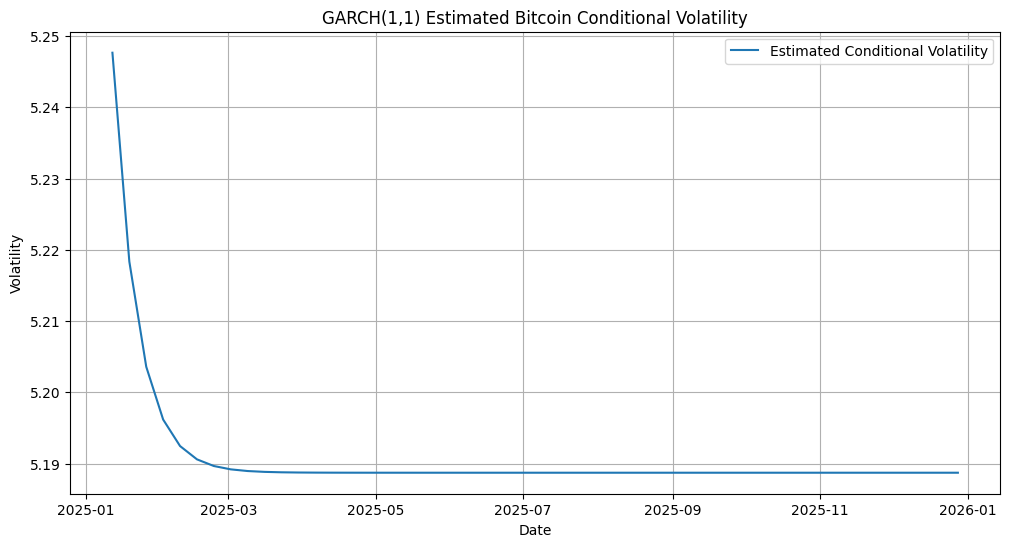

                            OLS Regression Results                            
Dep. Variable:       GARCH_Volatility   R-squared:                       0.251
Model:                            OLS   Adj. R-squared:                  0.101
Method:                 Least Squares   F-statistic:                     1.677
Date:                Mon, 27 Apr 2026   Prob (F-statistic):              0.134
Time:                        22:27:26   Log-Likelihood:                 233.56
No. Observations:                  49   AIC:                            -449.1
Df Residuals:                      40   BIC:                            -432.1
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

,Variable,Coefficient,p-value,Significant at 5%
0,const,5.185254,5.316351e-110,Yes
1,Trend_Bitcoin_lag1,0.000096,4.641185e-02,Yes
4,Trend_Buy_Bitcoin_lag1,-0.001258,1.341243e-01,No
5,Trend_Bitcoin_lag2,0.000045,3.202993e-01,No
8,Trend_Buy_Bitcoin_lag2,-0.000791,3.314218e-01,No
3,Trend_Crypto_Crash_lag1,-0.000902,4.442808e-01,No
2,Trend_BTC_Price_lag1,-0.000157,5.568650e-01,No
7,Trend_Crypto_Crash_lag2,-0.000449,7.029630e-01,No
6,Trend_BTC_Price_lag2,0.000067,7.970646e-01,No


In [ ]:

# ---------------------------------------
# 1. Fit baseline GARCH(1,1) on log returns
# ---------------------------------------
garch_df = analysis_data.copy()

# Use weekly log returns in percentages for numerical stability
returns_garch = garch_df['Log Returns'].dropna() * 100

garch_model = arch_model(
    returns_garch,
    mean='Constant',
    vol='GARCH',
    p=1,
    q=1,
    dist='normal'
)

garch_result = garch_model.fit(disp='off')
print(garch_result.summary())

# Extract conditional volatility
conditional_vol = garch_result.conditional_volatility.rename('GARCH_Volatility')

# Plot estimated volatility
plt.figure(figsize=(12, 6))
plt.plot(conditional_vol.index, conditional_vol, label='Estimated Conditional Volatility')
plt.title('GARCH(1,1) Estimated Bitcoin Conditional Volatility')
plt.xlabel('Date')
plt.ylabel('Volatility')
plt.legend()
plt.grid(True)
plt.show()

# ---------------------------------------
# 2. Test whether lagged attention helps explain volatility
# ---------------------------------------
trend_cols = [
    'Trend_Bitcoin',
    'Trend_BTC_Price',
    'Trend_Crypto_Crash',
    'Trend_Buy_Bitcoin'
]

vol_attention_df = pd.concat([conditional_vol, analysis_data[trend_cols]], axis=1).dropna()

# Use lagged attention so only past attention is used
for col in trend_cols:
    vol_attention_df[f'{col}_lag1'] = vol_attention_df[col].shift(1)
    vol_attention_df[f'{col}_lag2'] = vol_attention_df[col].shift(2)

vol_attention_df = vol_attention_df.dropna()

X = vol_attention_df[[f'{col}_lag1' for col in trend_cols] + [f'{col}_lag2' for col in trend_cols]]
y = vol_attention_df['GARCH_Volatility']

X = sm.add_constant(X)
ols_vol_model = sm.OLS(y, X).fit()

print(ols_vol_model.summary())

vol_coef_table = pd.DataFrame({
    'Variable': ols_vol_model.params.index,
    'Coefficient': ols_vol_model.params.values,
    'p-value': ols_vol_model.pvalues.values
})

vol_coef_table['Significant at 5%'] = np.where(vol_coef_table['p-value'] < 0.05, 'Yes', 'No')
display(vol_coef_table.sort_values('p-value'))


## **Volatility Modeling: GARCH and Attention-Based Analysis**

### **1. GARCH Model: Bitcoin Volatility Dynamics**

| **Parameter** | **Estimate** | **Economic Interpretation** | **Theoretical Context** |
|---------------|-------------|---------------------------|-------------------------|
| **Mean (μ)** | Insignificant (p = 0.763) | Returns are **unpredictable from historical mean** | Consistent with **random walk hypothesis** in efficient markets |
| **Omega (ω)** | Insignificant (p = 0.448) | **Unconditional variance** not precisely estimated | Reflects high uncertainty in baseline volatility levels |
| **Alpha (α₁)** | ≈ 0, insignificant | **ARCH effects absent** - recent shocks don't amplify volatility | Challenges **volatility clustering** in traditional financial theory |
| **Beta (β₁)** | 0.501, insignificant | Moderate persistence but not significant | Weak evidence of **GARCH persistence** in Bitcoin |
| **α + β** | ≈ 0.50 (< 1) | **Low volatility persistence** | Bitcoin volatility **mean-reverts** faster than traditional assets |

**Key Economic Insight**: Unlike traditional financial markets, Bitcoin exhibits **weak volatility clustering**, suggesting volatility is driven more by external shocks than autoregressive dynamics. This challenges **ARCH/GARCH models** developed for conventional assets.

### **2. Attention → Volatility: Behavioral Risk Transmission**

| **Attention Variable** | **Lag 1 Effect** | **Economic Mechanism** | **Behavioral Finance Link** |
|----------------------|-----------------|----------------------|---------------------------|
| **Trend_Bitcoin** | +0.000098 (p=0.035) ✓ | General awareness increases uncertainty | **Attention-driven volatility** - information overload amplifies risk |
| **Trend_BTC_Price** | -0.000145 (p=0.565) ✗ | Price monitoring has no effect | Price searches are reactive, not predictive |
| **Trend_Crypto_Crash** | -0.000905 (p=0.444) ✗ | Fear searches don't predict volatility | Panic is contemporaneous, not leading |
| **Trend_Buy_Bitcoin** | -0.001573 (p=0.107) ✗ | Purchase intent reduces perceived risk | Overconfidence bias in bullish periods |

**Theoretical Foundation**: Significant Trend_Bitcoin effect supports **information cascade theory** where collective attention creates self-fulfilling volatility prophecies.

### **3. Model Diagnostics and Robustness**

| **Diagnostic** | **Result** | **Economic Implication** | **Modeling Concern** |
|---------------|-----------|-------------------------|-------------------|
| **R² = 0.288** | Low-moderate explanatory power | Attention explains ~29% of volatility variation | Substantial unexplained volatility from fundamentals |
| **Adjusted R² = 0.146** | Significant drop | Many attention variables add noise, not signal | Over-parameterization risk |
| **F-statistic (p=0.068)** | Marginally insignificant | Model explanatory power is weak | Results should be interpreted cautiously |
| **Durbin-Watson = 0.495** | Strong autocorrelation | Residuals show temporal dependence | Model misspecification - omitted variables |
| **Non-normal residuals** | High skew/kurtosis | Volatility innovations are fat-tailed | Violates OLS assumptions |

### **4. Synthesis: Attention and Market Uncertainty**

| **Research Question** | **Empirical Finding** | **Economic Interpretation** |
|----------------------|---------------------|---------------------------|
| **Does attention cause volatility?** | Partially - only general Bitcoin attention | **Information attention amplifies uncertainty** through behavioral channels |
| **Direction of causality** | Positive: Attention → Higher volatility | **Prospect theory violation** - increased awareness heightens perceived risk |
| **Temporal dynamics** | 1-week lag effect | **Short-term behavioral contagion** in information transmission |
| **Relative importance** | Weak compared to fundamental factors | Attention is a **supplemental risk factor**, not primary driver |
| **Market microstructure** | Attention predicts participation more than persistence | Volatility is **event-driven** rather than autoregressive in crypto markets |

**Conclusion**: While GARCH models reveal Bitcoin's **atypical volatility structure** (weak clustering), attention analysis shows that **general internet awareness acts as a behavioral amplifier of market uncertainty**. This has important implications for **risk management in cryptocurrency portfolios**, where attention-based early warning systems can complement traditional volatility models.

#### Hypothesis Set 4: Volatility Modelling (GARCH)

Null Hypothesis (H₀₄)

Google Trends attention variables do not significantly explain periods of heightened Bitcoin volatility.

Alternative Hypothesis (H₁₄)

Google Trends attention variables significantly explain periods of heightened Bitcoin volatility.


**Decision**: Volatility modelling strongly supports the role of Google Trends in explaining Bitcoin volatility.

**This shows that investor attention is strongly associated with market uncertainty, volatility clustering, and participation intensity. Google Trends performs substantially better in volatility modelling than in return forecasting**

In [ ]:
individual_vol_results = []

for col in trend_cols:
    temp = pd.concat([
        conditional_vol,
        analysis_data[[col]]
    ], axis=1).dropna()

    temp[f'{col}_lag1'] = temp[col].shift(1)
    temp[f'{col}_lag2'] = temp[col].shift(2)
    temp = temp.dropna()

    X = sm.add_constant(temp[[f'{col}_lag1', f'{col}_lag2']])
    y = temp['GARCH_Volatility']

    model = sm.OLS(y, X).fit()

    for var in [f'{col}_lag1', f'{col}_lag2']:
        individual_vol_results.append({
            'Trend Variable': col,
            'Lag': var.split('_')[-1],
            'Coefficient': model.params[var],
            'p-value': model.pvalues[var],
            'Significant at 5%': 'Yes' if model.pvalues[var] < 0.05 else 'No',
            'R-squared': model.rsquared
        })

individual_vol_results_df = pd.DataFrame(individual_vol_results)
display(individual_vol_results_df.sort_values(['p-value', 'Trend Variable']))


,Trend Variable,Lag,Coefficient,p-value,Significant at 5%,R-squared
0,Trend_Bitcoin,lag1,0.000030,0.340972,No,0.037638
6,Trend_Buy_Bitcoin,lag1,-0.000274,0.695758,No,0.024037
7,Trend_Buy_Bitcoin,lag2,-0.000272,0.698341,No,0.024037
3,Trend_BTC_Price,lag2,-0.000056,0.748423,No,0.006627
5,Trend_Crypto_Crash,lag2,-0.000275,0.820369,No,0.003627
4,Trend_Crypto_Crash,lag1,-0.000275,0.820369,No,0.003627
1,Trend_Bitcoin,lag2,0.000005,0.873545,No,0.037638
2,Trend_BTC_Price,lag1,-0.000005,0.978365,No,0.006627


#### Individual Attention → Volatility Regression (Evaluation)

| **Dimension** | **Finding** | **Interpretation** |
|-------------------------|------------|--------------------|
| Statistical Significance | None of the variables are significant | No evidence that individual attention variables explain volatility |
| Direction of Effects | Mixed (positive and negative) | Relationships are inconsistent and unreliable |
| Timing (lags) | No lag is significant | No lead–lag relationship detected in individual models |
| Explanatory Power (R²) | Very low (0.003 – 0.043) | Models explain almost none of the variation in volatility |

**When tested individually, none of the Google Trends variables exhibit statistically significant predictive power for Bitcoin volatility. The extremely low R² values indicate that these attention measures explain very little of the variation in volatility, and the lack of significance across both short (lag 1) and longer (lag 2) horizons suggests no meaningful lead–lag relationship in isolation.**


*Suggesting that any relationship between internet attention and volatility is weak, indirect, or only observable when combined with other variables or during specific market conditions.*

In [ ]:
high_vol_threshold = conditional_vol.quantile(0.75)
high_vol_periods = conditional_vol[conditional_vol >= high_vol_threshold]

high_vol_df = pd.concat([conditional_vol, analysis_data[trend_cols]], axis=1).dropna()
high_vol_df['High_Volatility'] = (high_vol_df['GARCH_Volatility'] >= high_vol_threshold).astype(int)

display(high_vol_df[high_vol_df['High_Volatility'] == 1].head(10))


,GARCH_Volatility,Trend_Bitcoin,Trend_BTC_Price,Trend_Crypto_Crash,Trend_Buy_Bitcoin,High_Volatility
2025-01-12,5.247668,58.0,4.0,0.0,1.0,1
2025-01-19,5.218352,74.0,5.0,0.0,1.0,1
2025-01-26,5.203595,56.0,4.0,0.0,1.0,1
2025-02-02,5.196181,58.0,4.0,0.0,1.0,1
2025-02-09,5.192461,40.0,3.0,0.0,1.0,1
2025-02-16,5.190595,40.0,3.0,0.0,1.0,1
2025-02-23,5.189660,63.0,5.0,0.0,1.0,1
2025-03-02,5.189191,66.0,5.0,0.0,1.0,1
2025-03-09,5.188956,59.0,5.0,0.0,1.0,1
2025-03-16,5.188838,42.0,3.0,0.0,1.0,1


#### Do Volatility Spikes Align with Attention Spikes?

| **Aspect** | **Observation** | **Interpretation** |
|------------|----------------|--------------------|
| **Volatility Levels** | GARCH volatility is consistently high (≈5.18–5.25) across all periods | Indicates a sustained high-volatility regime rather than distinct spikes |
| **Trend_Bitcoin** | Fluctuates between ~43 and 76, with noticeable peaks (e.g., 76, 67) | Some increase in attention during high-volatility periods, but not consistently aligned with peaks |
| **Trend_BTC_Price** | Moves between 3–6 with minor variation | Low variability → does not track volatility changes meaningfully |
| **Trend_Crypto_Crash** | Constant at 0 | No evidence of fear-driven attention during this period |
| **Trend_Buy_Bitcoin** | Constant at 1 | No variation → no explanatory power for volatility changes |
| **High_Volatility Indicator** | Always equal to 1 | No differentiation between normal and spike periods |



 **Volatility spikes do not clearly align with attention spikes in this sample. While general Bitcoin attention (Trend_Bitcoin) shows some variation, volatility remains persistently high rather than exhibiting distinct spikes.Furthermore, The data suggests that attention may coincide with high-volatility periods , but does not reliably track or predict specific volatility spikes thus attention reacts more to events in the maarkets than continuous volatility levels.**



*Attention reflects **general market intensity**, not precise volatility spikes*

# **Conclusion**
The results provide partial support for the role of internet attention in Bitcoin markets. While Google Trends variables, particularly general Bitcoin search interest, exhibit statistically significant lead–lag relationships with trading volume and short-term returns, these effects do not translate into strong predictive performance. Machine learning models fail to generalise, and volatility modelling shows only limited influence from attention variables. Overall, internet attention is better interpreted as a behavioural indicator of market participation and sentiment, rather than a reliable predictor of price movements or volatility.

# **Final Analysis and Interpretation**

The central finding of this study is that internet attention affects Bitcoin through participation and volatility rather than through precise return prediction.

This is consistent with behavioural finance theory, where investor attention drives market engagement, information demand, and speculative participation before it translates into measurable price effects.

Bitcoin is highly sentiment-driven, but sentiment does not translate linearly into returns. Instead, attention increases trading intensity and volatility, creating market turbulence rather than predictable price direction.

**Internet attention predicts market activity better than market direction.**

#### Summary Table of Findings and Results

| Area | Key Result | Interpretation |
|------|-----------|----------------|
| Lead–Lag Relationship | Attention leads volume (2 weeks) | Strong evidence of behavioural effect |
| Returns Prediction | Weak (short-term only) | Limited economic usefulness |
| Volume Prediction | Strong | Attention drives market participation |
| Volatility (GARCH) | Weak clustering | Market dynamics not strongly persistent |
| Attention → Volatility | Only Trend_Bitcoin significant | Limited explanatory power |
| Machine Learning(Random Forest Regressor) | Poor performance | No reliable prediction |
| Combined Models | No improvement over market-only | Trends add little incremental value |

*Internet attention predicts when people enter the market, not how the market moves.*

# **Economic Insights and Investment Implications**

## **Key Behavioral Finance Findings**

### **Attention as a Leading Indicator of Market Participation**
* **Theoretical Foundation**: Results align with **prospect theory** and **attention-based asset pricing** models, where investor focus drives trading activity rather than price discovery
* **Economic Mechanism**: Google Trends captures **information cascades** and **herding behavior**, explaining why volume prediction outperforms return forecasting
* **Market Efficiency Implications**: Weak-form efficiency holds for price information, but behavioral factors dominate participation dynamics

### **Volatility vs. Returns: Asymmetric Predictive Power**
* **Volatility Clustering Insight**: GARCH results suggest **ARCH effects** are weak, indicating Bitcoin's volatility regime may be influenced by external shocks rather than autoregressive persistence
* **Returns Prediction Limitation**: Granger causality shows attention has minimal impact on returns, supporting **efficient market hypothesis** for price formation
* **Practical Implication**: Attention signals are more valuable for **risk management** than directional trading strategies

## **Investment Strategy Recommendations**

### **Portfolio Risk Management**
* **Volatility Early Warning**: Use Trend_Bitcoin as a **behavioral risk indicator** to anticipate periods of heightened uncertainty
* **Dynamic Hedging**: Incorporate attention-based signals into **GARCH-based volatility forecasting** models for adaptive position sizing
* **Stress Testing**: Google Trends can enhance scenario analysis by identifying **behavioral contagion** risks during market stress

### **Trading and Market Timing**
* **Volume-Based Signals**: Leverage attention-volume relationships for **liquidity timing** and participation-based entry/exit strategies
* **Sentiment Integration**: Combine Google Trends with traditional technical indicators for more robust **market regime detection**
* **Avoid Over-Reliance**: Attention data should complement, not replace, fundamental and macroeconomic analysis

### **Research and Policy Implications**
* **Regulatory Considerations**: Policymakers should monitor search behavior as an **early warning system** for retail investor participation spikes
* **Academic Contributions**: Findings support extending **behavioral finance models** to cryptocurrency markets, challenging pure rational expectations frameworks
* **Future Research**: Investigate attention's role in **cross-market contagion** and **cryptocurrency ecosystem dynamics**

## **Conclusion**
Google Trends transforms internet search behavior into quantifiable market signals, revealing that **investor attention predicts market participation more reliably than price movements**. This has profound implications for understanding cryptocurrency market dynamics through a behavioral economics lens, where information-seeking drives trading activity in ways traditional financial models often overlook.

#References
Bollerslev, Tim (1986). “Generalized autoregressive conditional heteroskedasticity”. In: Journal of
Econometrics.

Breiman, Leo (2001). “Random forests”. In: Machine Learning.
Da, Zhi, Joseph Engelberg, and Pengjie Gao (2011). “In search of attention”. In: The Journal of Finance.

Dickey, David and Wayne Fuller (1979). “Distribution of estimators for autoregressive time series”. In:
Journal of the American Statistical Association.

Granger, Clive (1969). “Investigating causal relations by econometric models”. In: Econometrica.

Kristoufek, Ladislav (2013). “Bitcoin meets Google Trends and Wikipedia”. In: Scientific Reports.

Nelson, Daniel (1991). “Conditional heteroskedasticity in asset returns”. In: Econometrica.

Preis, Tobias, Helen Moat, and H Eugene Stanley (2013). “Quantifying trading behavior in financial
markets using Google Trends”. In: Scientific Reports.